In [23]:
!git clone https://github.com/walid-mk/QiskitFallFest_EMSI_QuantumAfrica.git

fatal: destination path 'QiskitFallFest_EMSI_QuantumAfrica' already exists and is not an empty directory.


In [24]:
import os

project_path = "/kaggle/working/QiskitFallFest_EMSI_QuantumAfrica"

os.listdir(project_path)

['.gitignore',
 'challenge',
 'data',
 'assets',
 'requirements-hardware.txt',
 'configs',
 '.git',
 'README.md',
 'notebooks',
 'LICENSE',
 'requirements.txt',
 'Student_Challenge_Brief.pdf',
 'results',
 'docs']

In [25]:
import pandas as pd
import os

data_path = "/kaggle/working/QiskitFallFest_EMSI_QuantumAfrica/data"

# Afficher les fichiers disponibles
print("Fichiers disponibles :", os.listdir(data_path))

# Charger les datasets
train = pd.read_csv(f"{data_path}/train.csv")
val = pd.read_csv(f"{data_path}/validation.csv")
test = pd.read_csv(f"{data_path}/test.csv")

# Dimensions
print("\nTrain :", train.shape)
print("Validation :", val.shape)
print("Test :", test.shape)

# Aperçu des données
display(train.head())

Fichiers disponibles : ['training_600_ids.json', 'validation.csv', 'test.csv', 'README.md', 'starter_ids.json', 'manifest.json', 'train.csv', 'views', 'validation_groups.json']

Train : (914, 15)
Validation : (150, 15)
Test : (221, 14)


,sample_id,B1,B2,B3,B4,B5,B6,B7,B8,B8A,B9,B11,B12,NDVI,target
0,r2_628897512b6a2af8,735.567992,740.099161,1103.821592,1412.509516,1901.466817,2597.579302,2857.496966,3022.922050,3160.550781,3262.820296,3684.901528,2887.059773,0.362266,wheat
1,r2_52d40a7666662fbd,752.931868,812.251386,1172.340007,1598.965384,2033.616183,2468.844736,2697.697668,2880.773913,3044.599874,3124.898557,3869.040977,3079.286981,0.286029,wheat
2,r2_e76f16082a693985,819.912019,975.489611,1365.777977,1904.760633,2320.778855,2671.421702,2907.777672,3130.940754,3283.921426,3339.404644,4396.221336,3628.698620,0.244120,wheat
3,r2_3839538f981ce331,1001.256331,1198.507762,1684.384185,2361.372939,2784.518664,3070.120886,3279.390119,3499.690057,3605.214034,3556.593666,4756.978472,3886.156420,0.195382,wheat
4,r2_f7cf7a2cbbff3f42,894.788026,737.549029,1095.658738,1346.803236,1833.658738,2538.135761,2808.466181,2910.387379,3107.418447,3350.548867,3945.857443,3290.001780,0.371730,maize



# 2. Data Quality Assessment

Assess data quality by identifying missing values, duplicate records, incorrect data types, and infinite values. Generate descriptive statistics to detect potential inconsistencies before data cleaning and preprocessing.


In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Target: target
Features: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'NDVI']
Dataset sizes: {'Train': (914, 15), 'Validation': (150, 15), 'Test': (221, 14)}


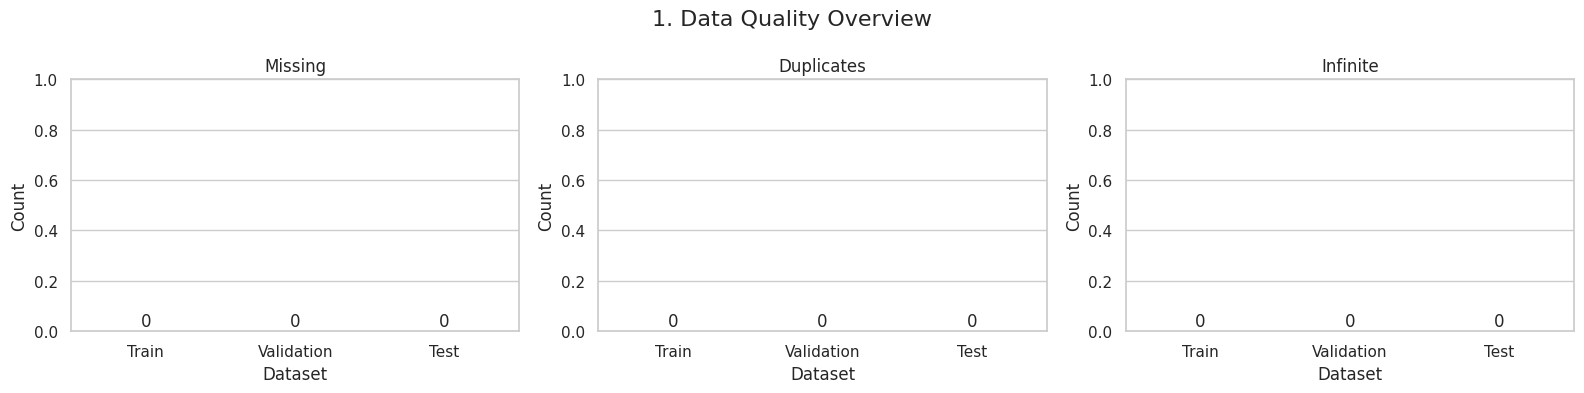

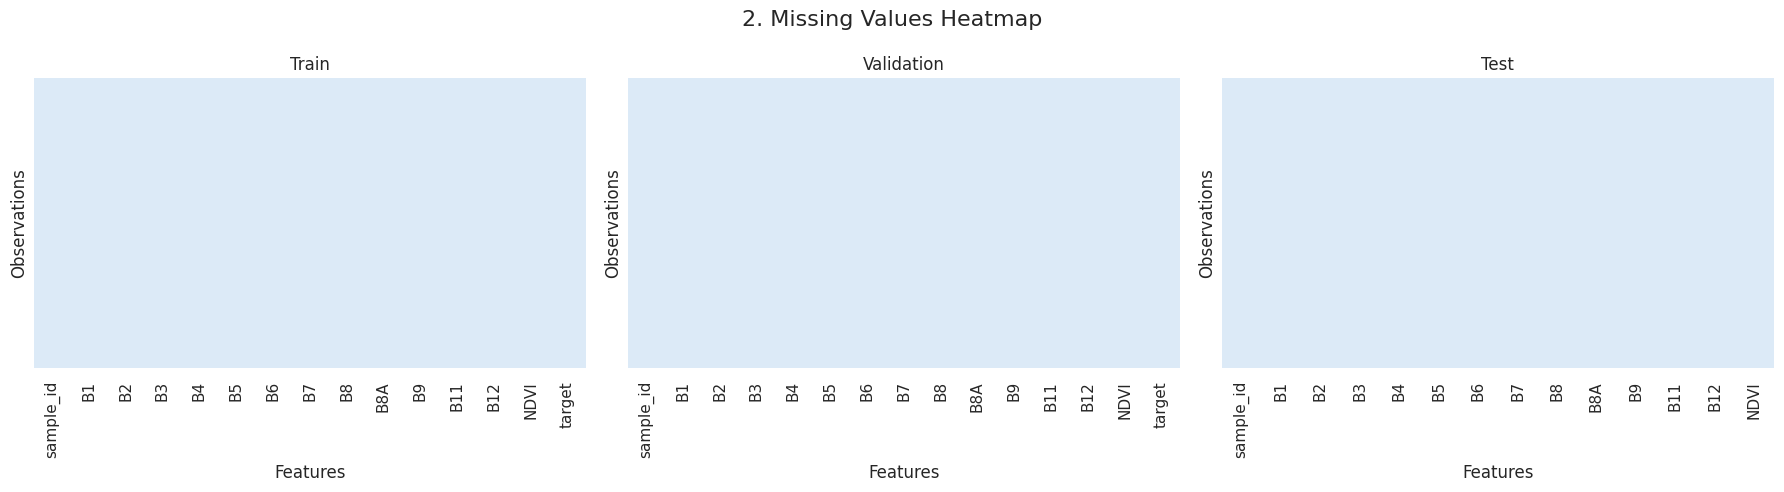

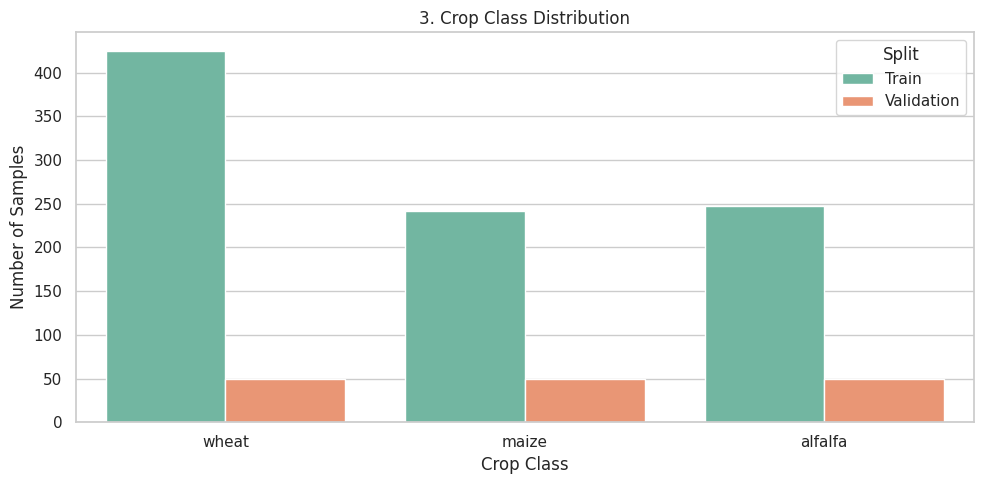

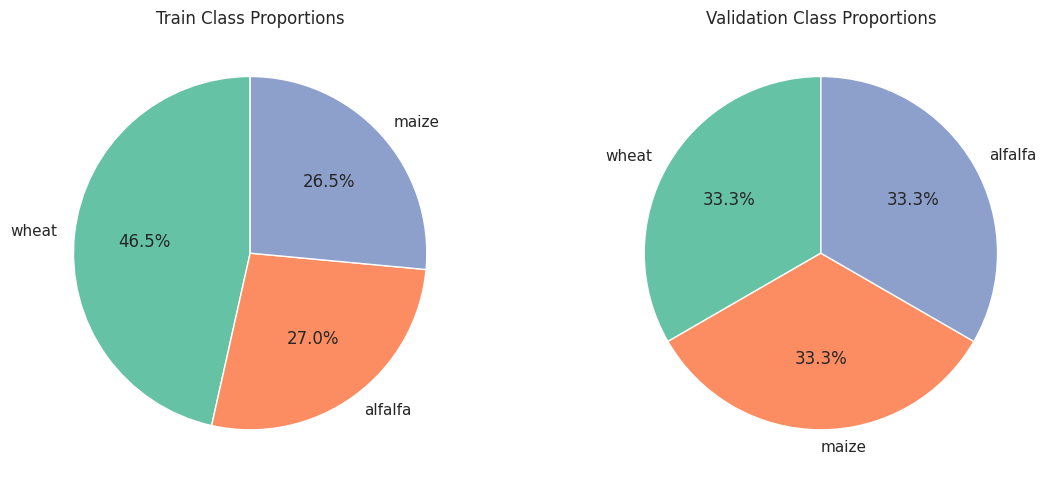

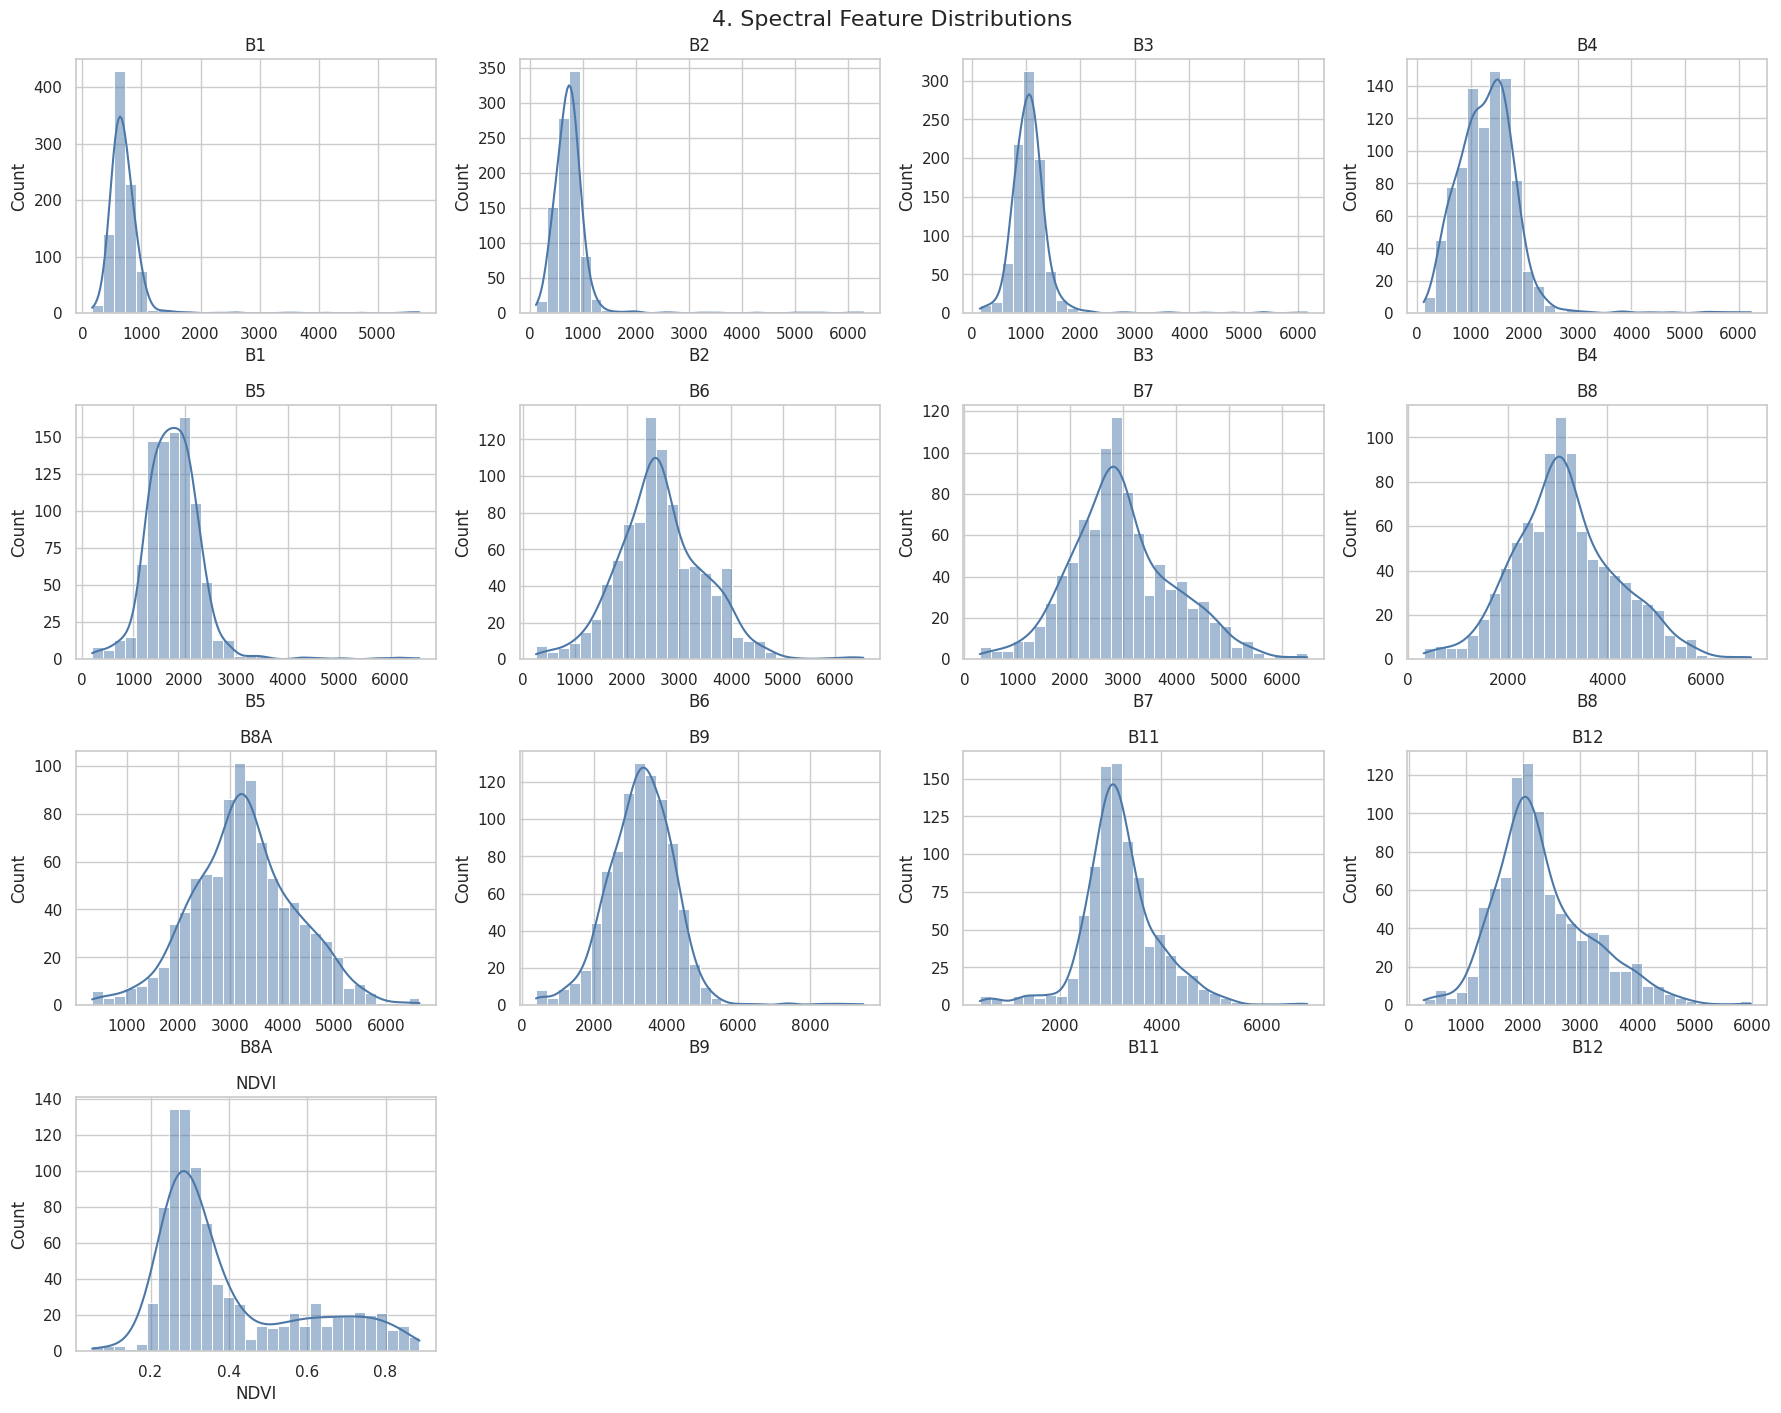

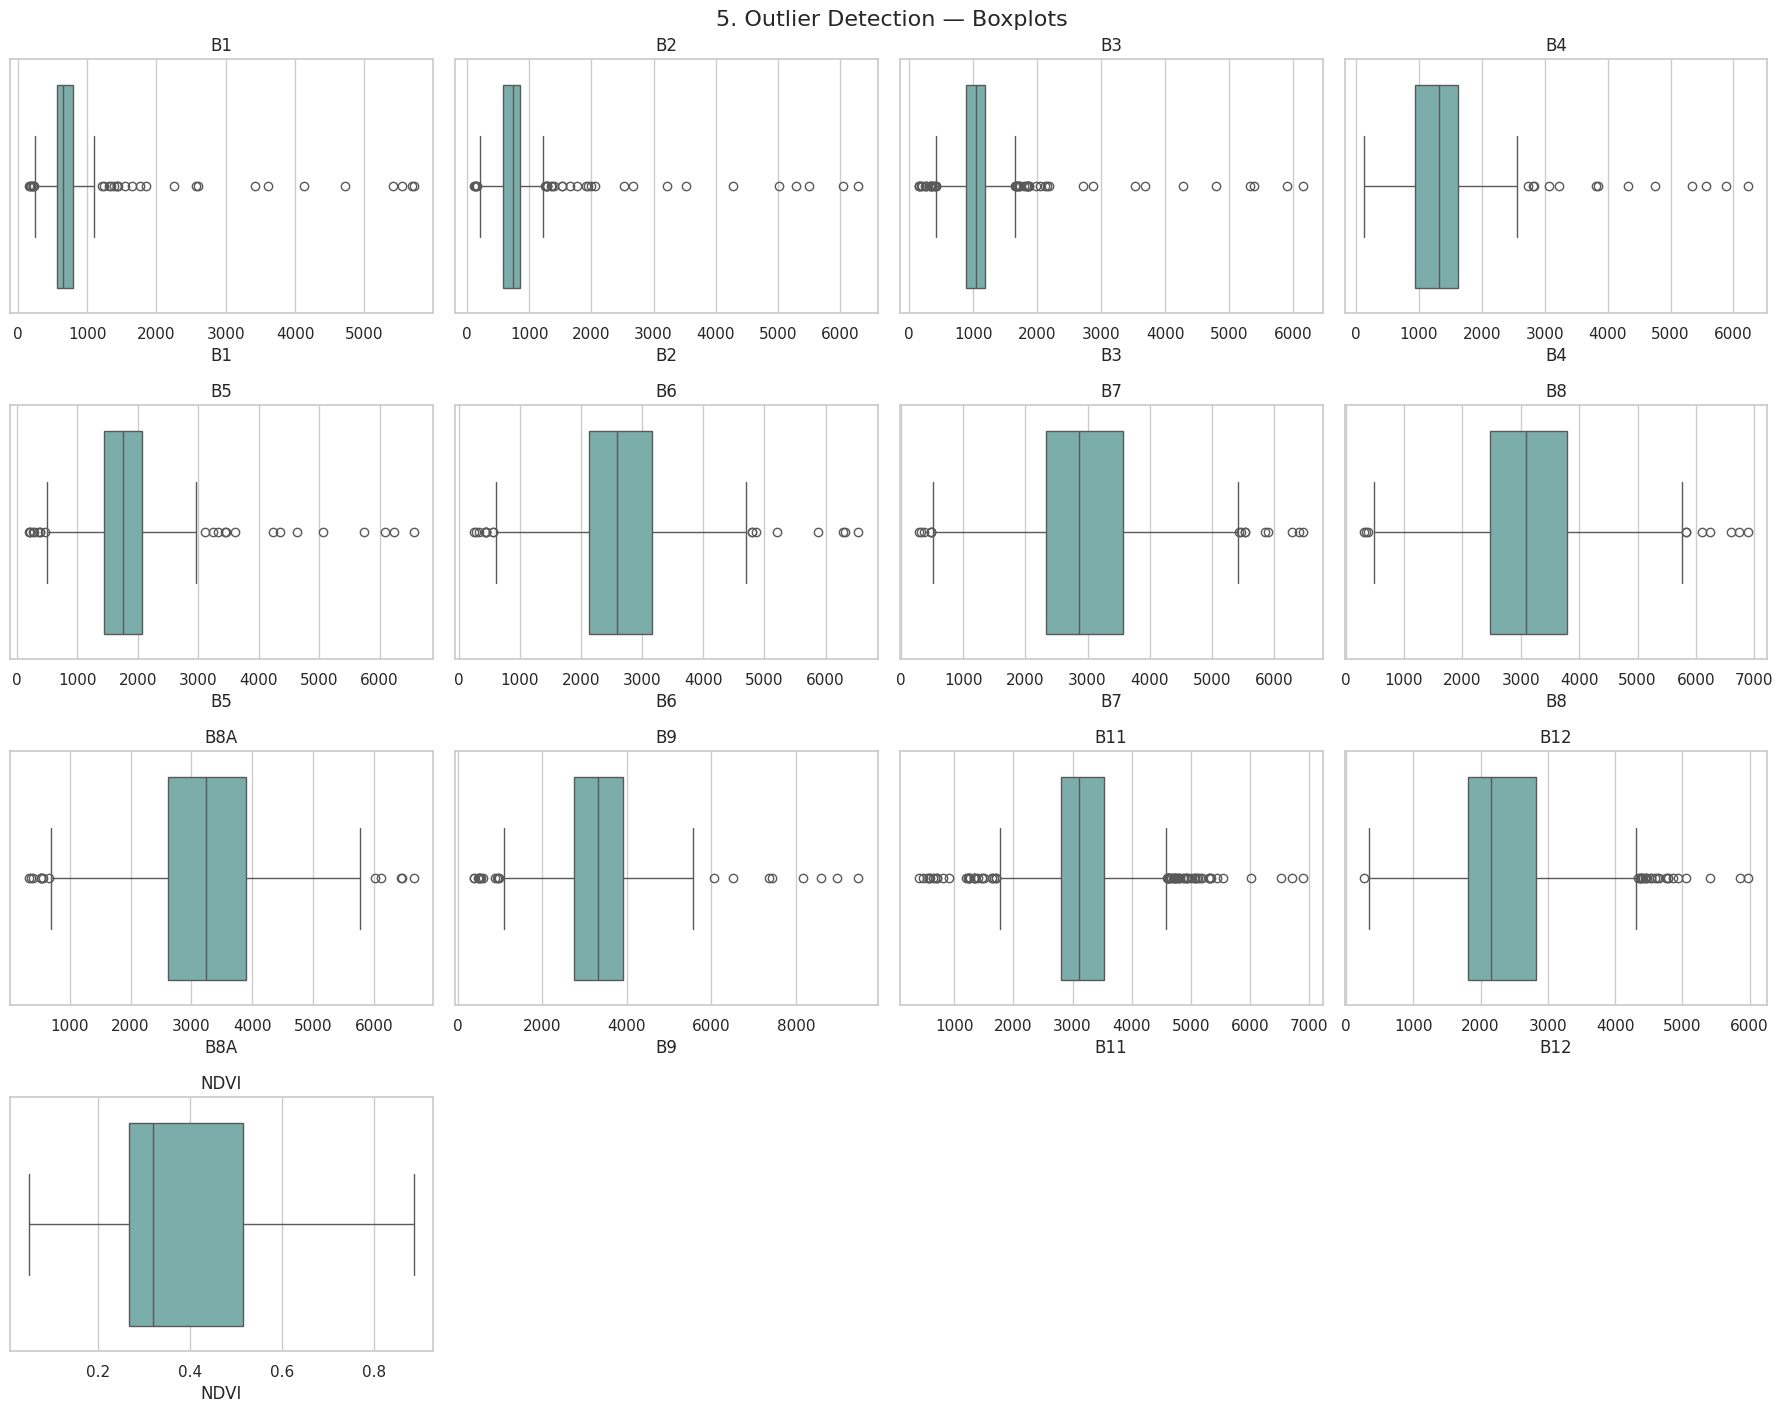

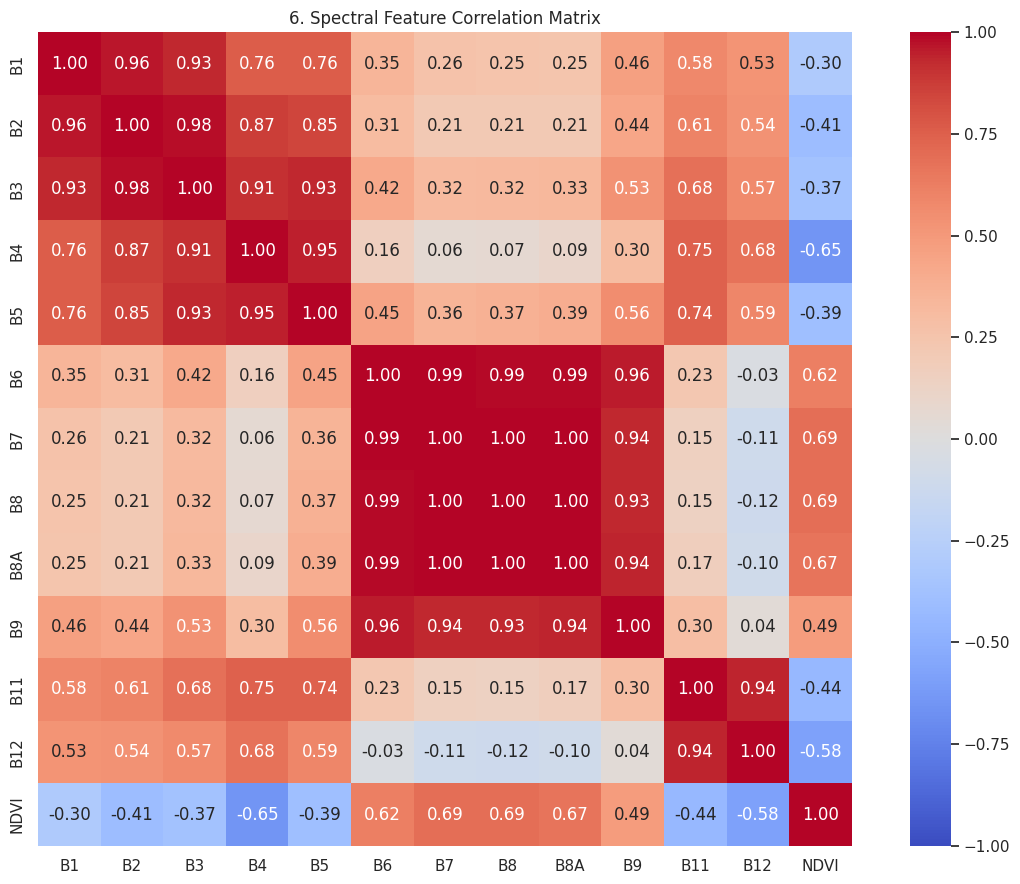

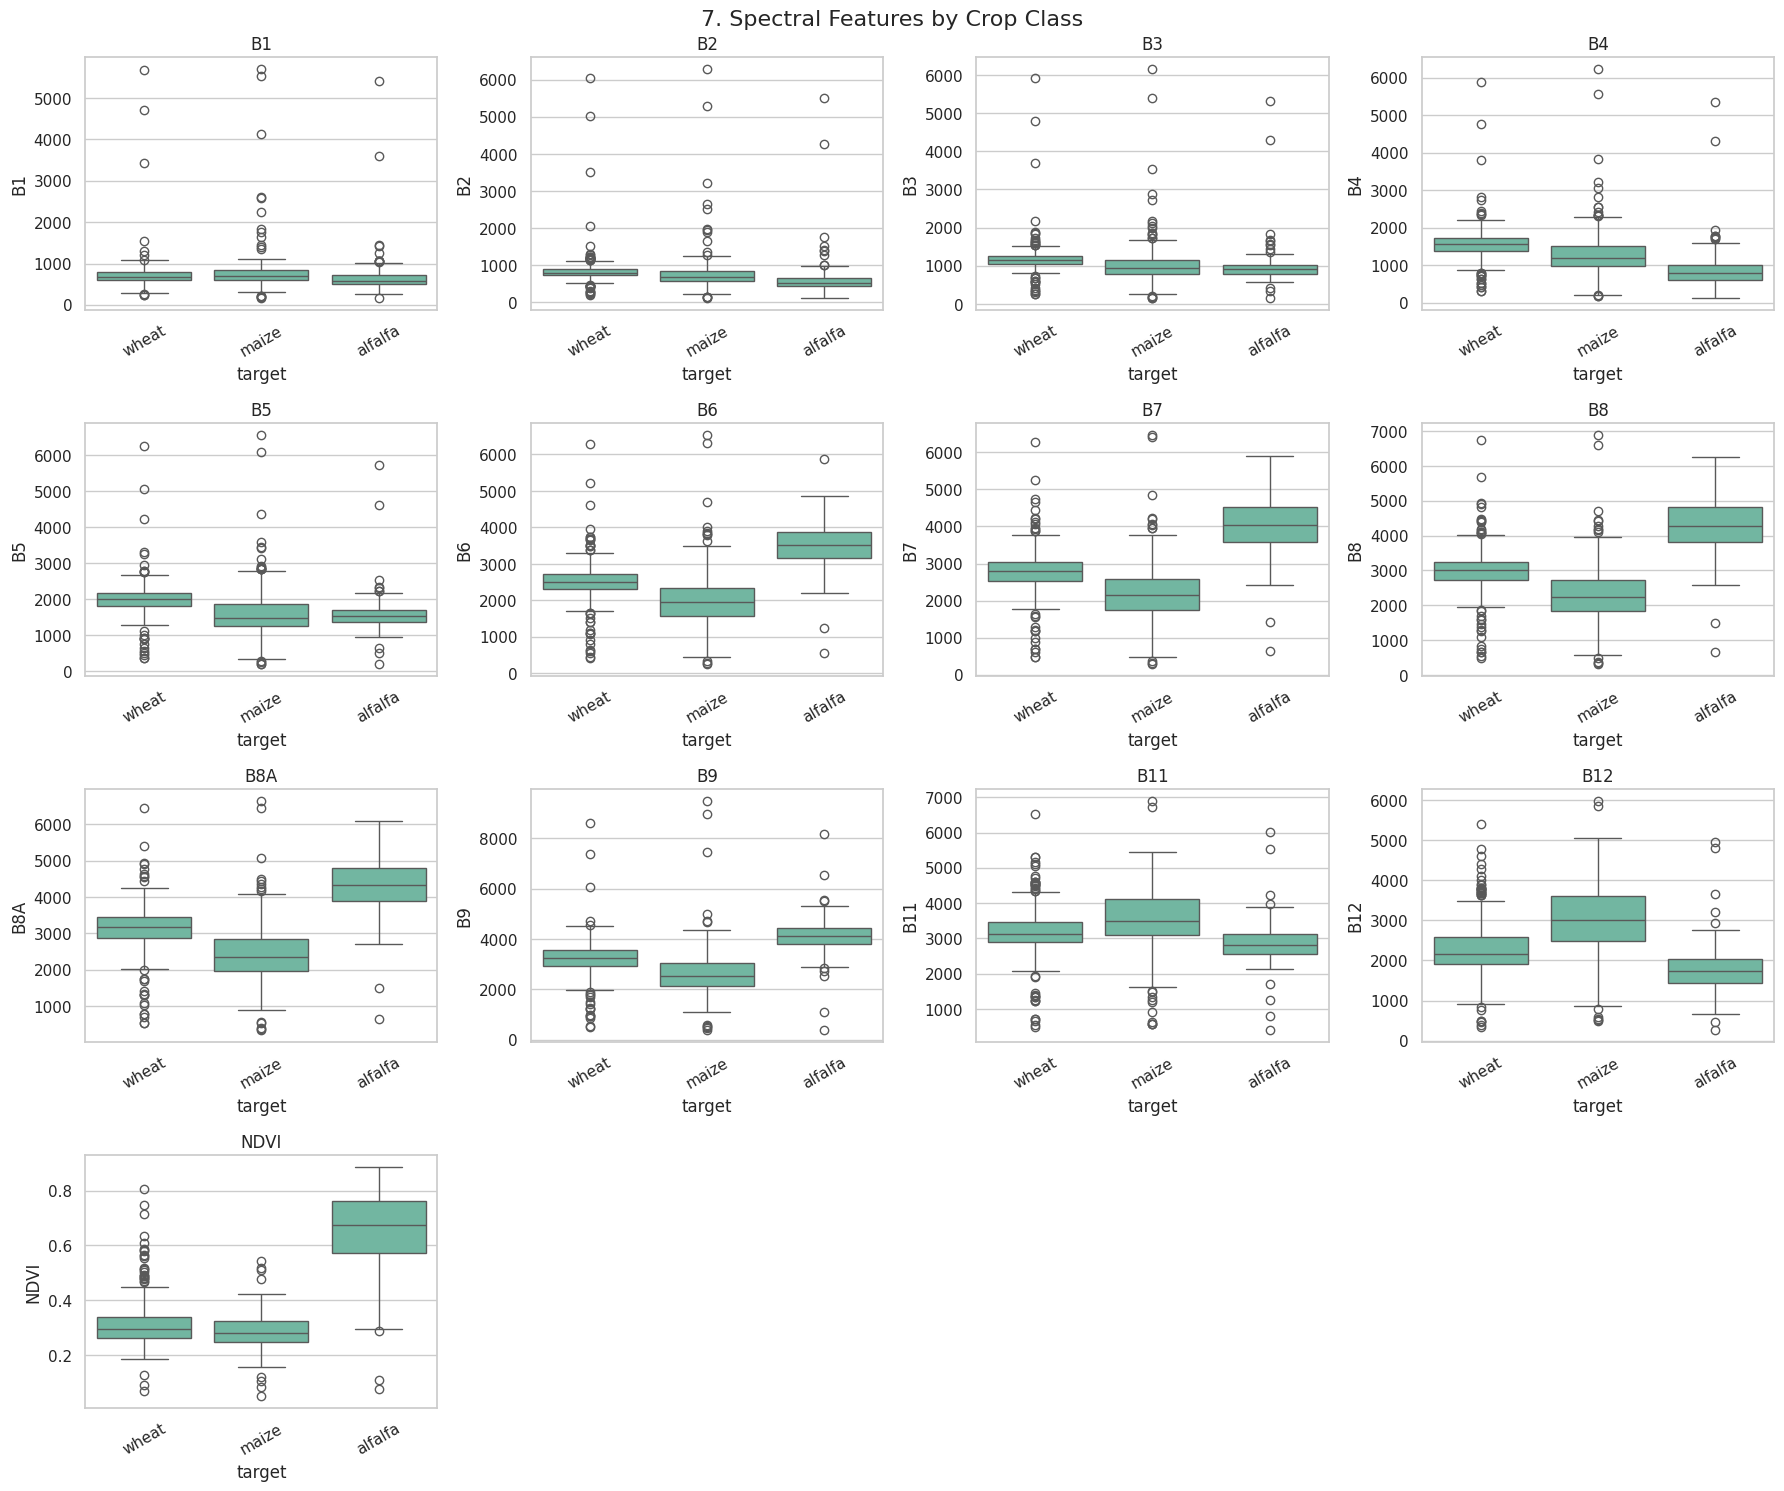

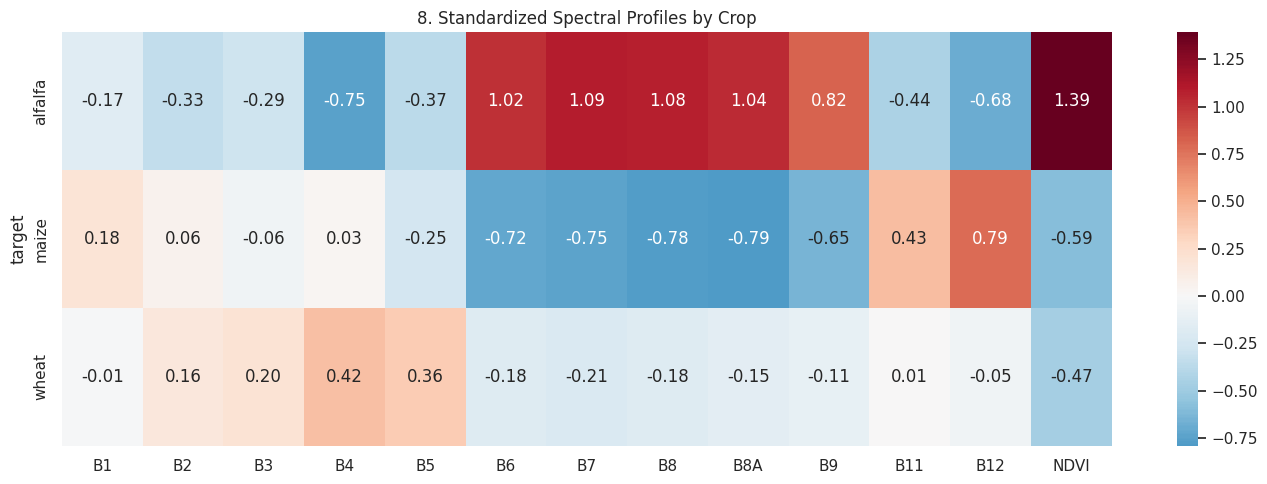

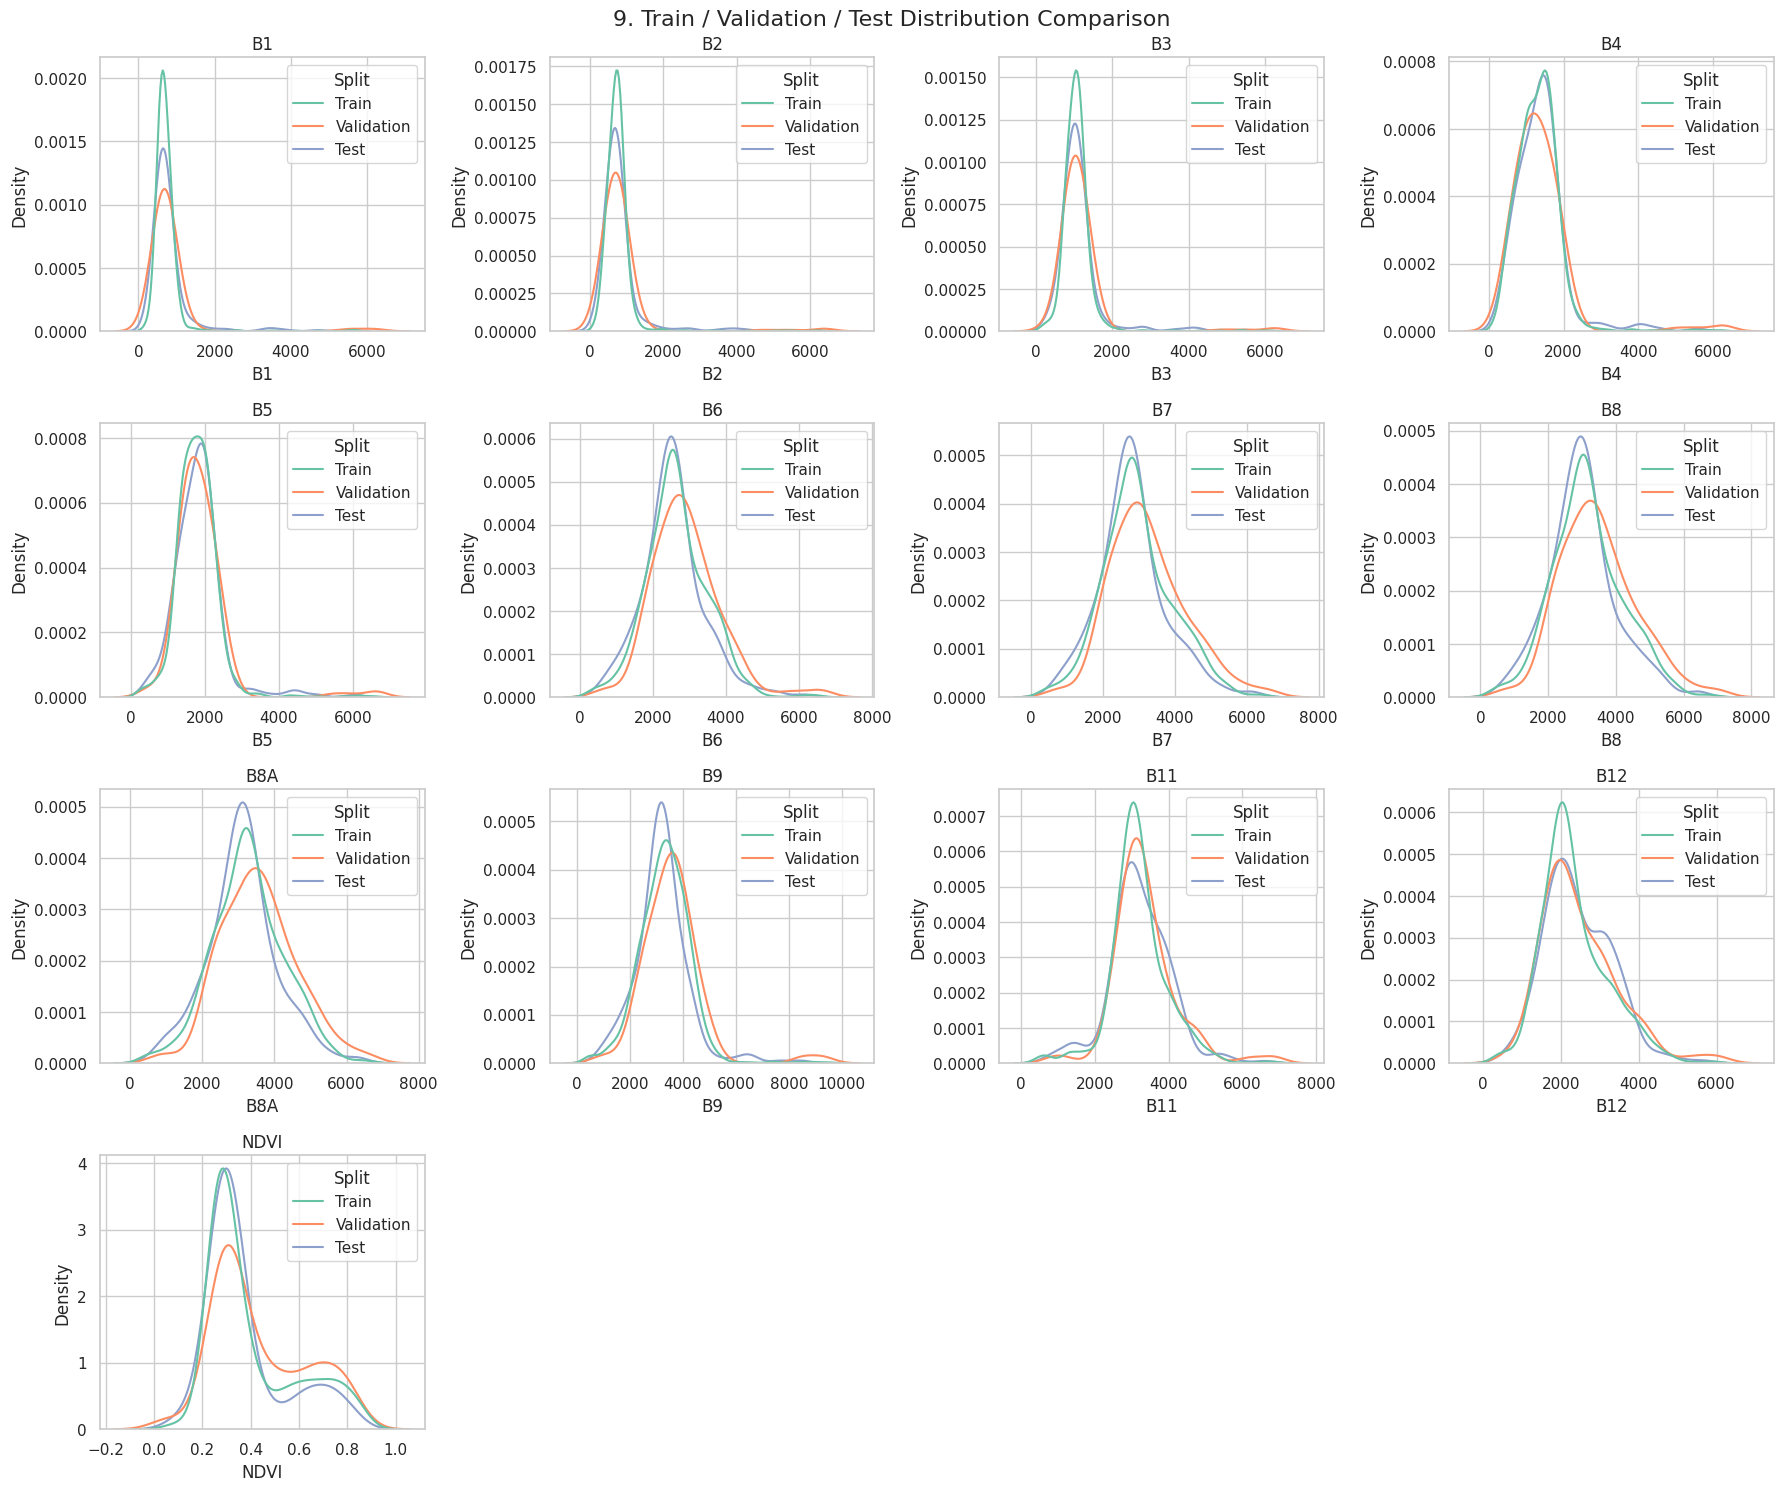

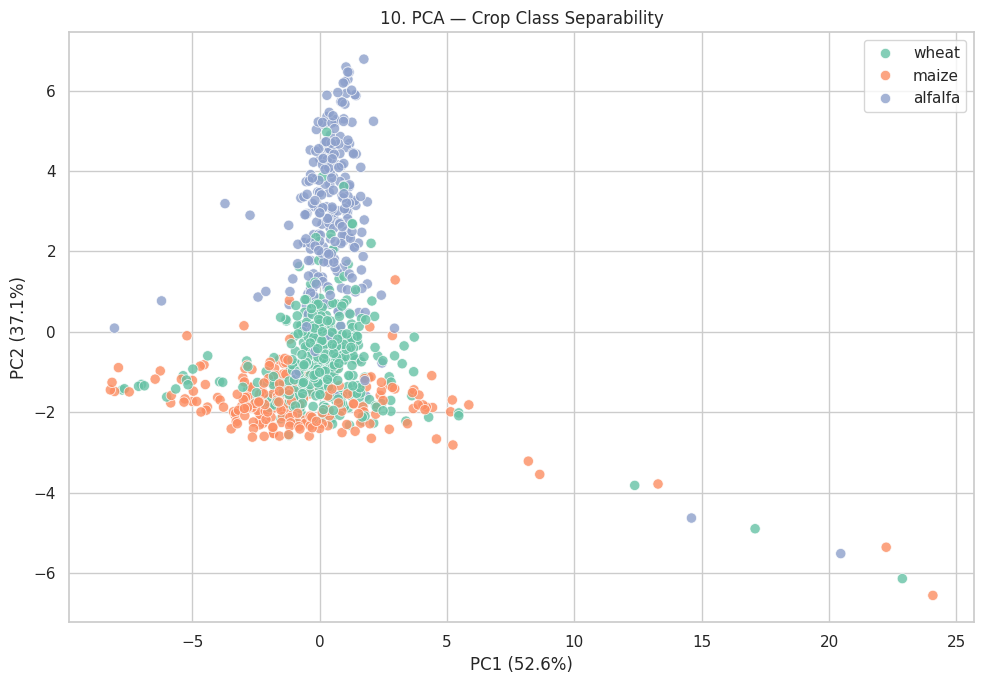

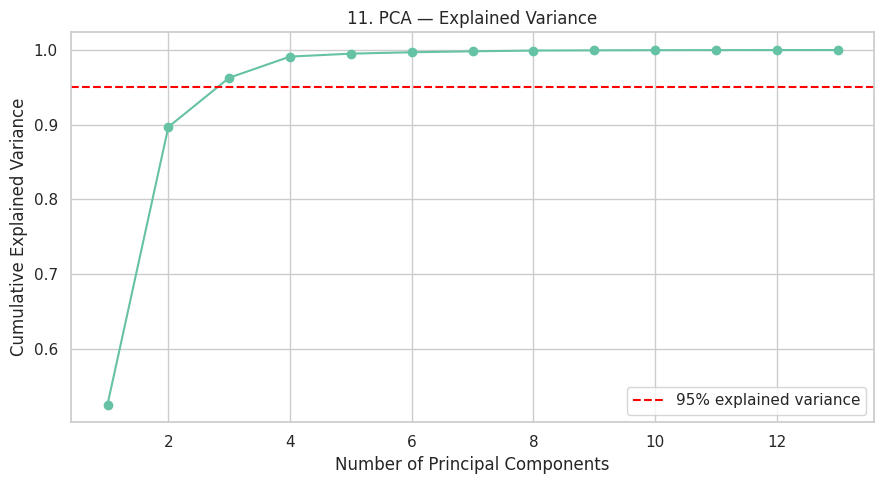

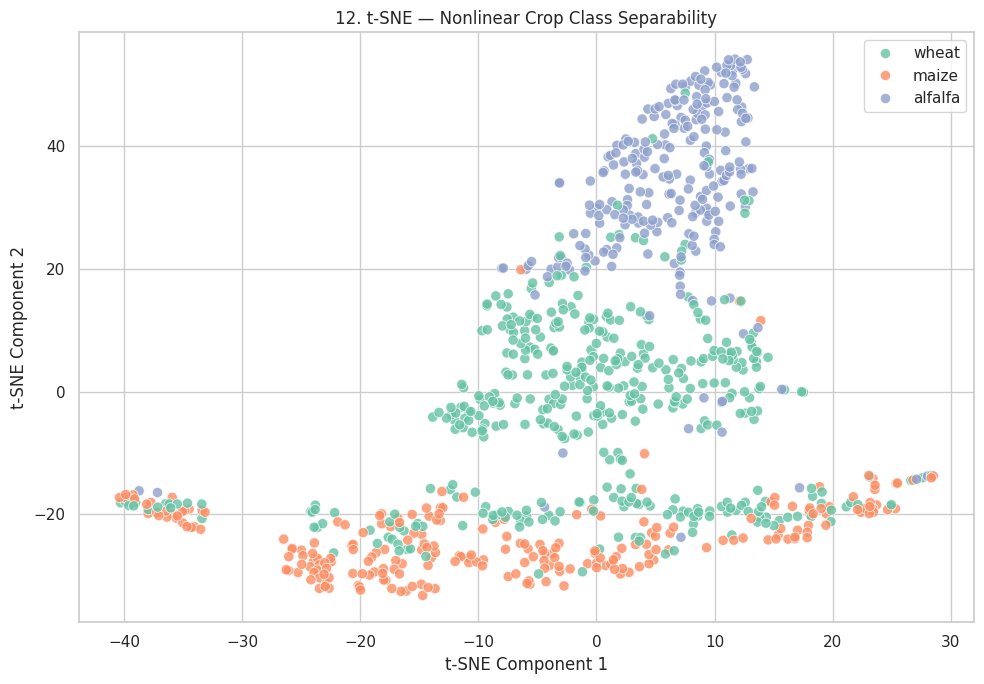

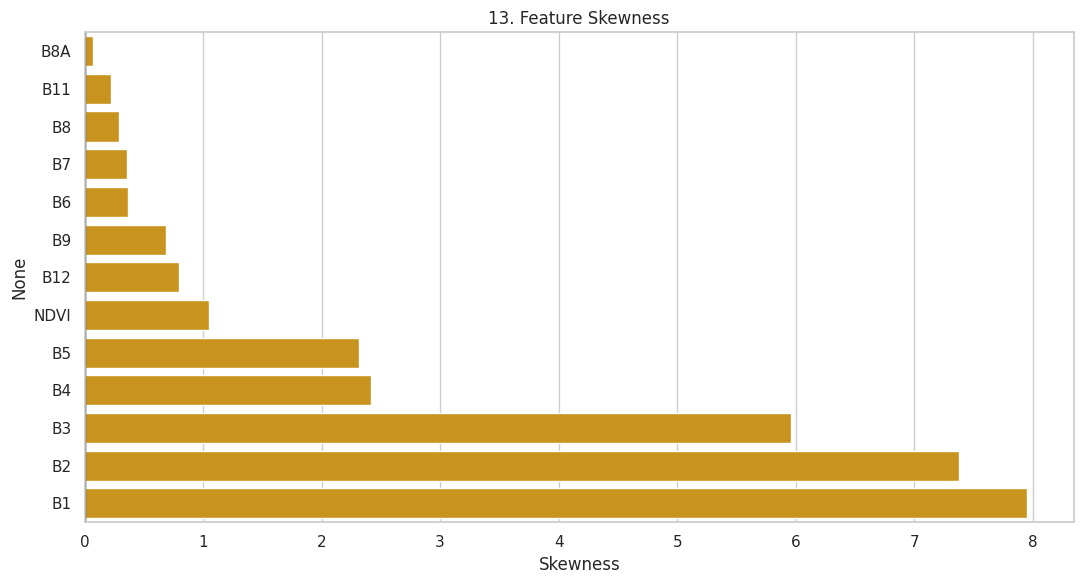


EDA VISUALIZATION COMPLETED!


In [27]:

# ============================================================
# COMPLETE EDA — MOROCCAN CROP CLASSIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="Set2")

# ------------------------------------------------------------
# 0. CONFIGURATION
# ------------------------------------------------------------

datasets = {
    "Train": train,
    "Validation": val,
    "Test": test
}

# Automatically identify target column
target_candidates = [
    "label", "class", "target", "crop", "crop_type",
    "culture", "Crop", "Label", "Class"
]

target = next(
    (c for c in target_candidates if c in train.columns),
    None
)

if target is None:
    extra = [c for c in train.columns if c not in test.columns]
    if len(extra) == 1:
        target = extra[0]
    else:
        raise ValueError(
            "Target column not identified. "
            f"Train-only columns: {extra}"
        )

# Input features shared across all splits
features = [
    c for c in train.select_dtypes(include=np.number).columns
    if c in val.columns
    and c in test.columns
    and c != target
]

if not features:
    raise ValueError("No common numeric input features found.")

print("Target:", target)
print("Features:", features)
print("Dataset sizes:", {
    k: v.shape for k, v in datasets.items()
})

# ------------------------------------------------------------
# 1. DATA QUALITY ASSESSMENT
# ------------------------------------------------------------

quality = []

for name, df in datasets.items():
    numeric = df.select_dtypes(include=np.number)

    quality.append({
        "Dataset": name,
        "Missing": int(df.isna().sum().sum()),
        "Duplicates": int(df.duplicated().sum()),
        "Infinite": int(
            np.isinf(numeric.to_numpy()).sum()
        )
    })

quality_df = pd.DataFrame(quality).set_index("Dataset")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, quality_df.columns):
    sns.barplot(
        x=quality_df.index,
        y=quality_df[col],
        ax=ax,
        color="#4C78A8"
    )
    ax.set_title(col)
    ax.set_ylabel("Count")

    for i, value in enumerate(quality_df[col]):
        ax.text(i, value + 0.02, str(value), ha="center")

    ax.set_ylim(
        0, max(1, quality_df[col].max() * 1.25)
    )

plt.suptitle("1. Data Quality Overview", fontsize=16)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. MISSING VALUES HEATMAP
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, df) in zip(axes, datasets.items()):
    sns.heatmap(
        df.isna(),
        cmap=["#DCEAF7", "#D62728"],
        cbar=False,
        yticklabels=False,
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Features")
    ax.set_ylabel("Observations")

plt.suptitle("2. Missing Values Heatmap", fontsize=16)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. CLASS DISTRIBUTION — TRAIN VS VALIDATION
# ------------------------------------------------------------

class_df = pd.concat([
    train[[target]].assign(Split="Train"),
    val[[target]].assign(Split="Validation")
], ignore_index=True)

plt.figure(figsize=(10, 5))

sns.countplot(
    data=class_df,
    x=target,
    hue="Split"
)

plt.title("3. Crop Class Distribution")
plt.xlabel("Crop Class")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

# Class percentages
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, df) in zip(
    axes, [("Train", train), ("Validation", val)]
):
    counts = df[target].value_counts()

    ax.pie(
        counts.values,
        labels=counts.index.astype(str),
        autopct="%1.1f%%",
        startangle=90
    )
    ax.set_title(f"{name} Class Proportions")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

cols = 4
rows = int(np.ceil(len(features) / cols))

fig, axes = plt.subplots(
    rows, cols,
    figsize=(18, 3.6 * rows)
)

axes = np.array(axes).flatten()

for i, feature in enumerate(features):
    values = train[feature].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    sns.histplot(
        values,
        kde=values.nunique() > 1,
        bins=30,
        ax=axes[i],
        color="#4C78A8"
    )
    axes[i].set_title(feature)

for ax in axes[len(features):]:
    ax.axis("off")

plt.suptitle("4. Spectral Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. OUTLIER DETECTION — BOXPLOTS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    rows, cols,
    figsize=(18, 3.6 * rows)
)

axes = np.array(axes).flatten()

for i, feature in enumerate(features):
    sns.boxplot(
        x=train[feature].replace(
            [np.inf, -np.inf], np.nan
        ),
        ax=axes[i],
        color="#72B7B2"
    )
    axes[i].set_title(feature)

for ax in axes[len(features):]:
    ax.axis("off")

plt.suptitle("5. Outlier Detection — Boxplots", fontsize=16)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. CORRELATION MATRIX
# ------------------------------------------------------------

corr = train[features].replace(
    [np.inf, -np.inf], np.nan
).corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("6. Spectral Feature Correlation Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. FEATURE DISTRIBUTIONS BY CROP CLASS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    rows, cols,
    figsize=(18, 3.8 * rows)
)

axes = np.array(axes).flatten()

for i, feature in enumerate(features):
    sns.boxplot(
        data=train.replace([np.inf, -np.inf], np.nan),
        x=target,
        y=feature,
        ax=axes[i]
    )
    axes[i].set_title(feature)
    axes[i].tick_params(axis="x", rotation=30)

for ax in axes[len(features):]:
    ax.axis("off")

plt.suptitle(
    "7. Spectral Features by Crop Class",
    fontsize=16
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. CLASS-CONDITIONAL FEATURE HEATMAP
# ------------------------------------------------------------

class_means = (
    train.replace([np.inf, -np.inf], np.nan)
    .groupby(target)[features]
    .mean()
)

# Standardize using training-set statistics
train_mean = train[features].replace(
    [np.inf, -np.inf], np.nan
).mean()

train_std = train[features].replace(
    [np.inf, -np.inf], np.nan
).std().replace(0, 1)

standardized_means = (
    class_means - train_mean
) / train_std

plt.figure(figsize=(14, 5))

sns.heatmap(
    standardized_means,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0
)

plt.title("8. Standardized Spectral Profiles by Crop")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. TRAIN / VALIDATION / TEST DISTRIBUTION SHIFT
# ------------------------------------------------------------

combined = pd.concat([
    train[features].assign(Split="Train"),
    val[features].assign(Split="Validation"),
    test[features].assign(Split="Test")
], ignore_index=True)

combined = combined.replace([np.inf, -np.inf], np.nan)

fig, axes = plt.subplots(
    rows, cols,
    figsize=(18, 3.8 * rows)
)

axes = np.array(axes).flatten()

for i, feature in enumerate(features):
    sns.kdeplot(
        data=combined,
        x=feature,
        hue="Split",
        common_norm=False,
        ax=axes[i],
        warn_singular=False
    )
    axes[i].set_title(feature)

for ax in axes[len(features):]:
    ax.axis("off")

plt.suptitle(
    "9. Train / Validation / Test Distribution Comparison",
    fontsize=16
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. PCA — CLASS SEPARABILITY
# ------------------------------------------------------------

X = train[features].replace(
    [np.inf, -np.inf], np.nan
)

# Fit preprocessing only on train
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

labels = train[target].astype(str).values

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=labels,
    alpha=0.8,
    s=55
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)
plt.title("10. PCA — Crop Class Separability")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. PCA EXPLAINED VARIANCE
# ------------------------------------------------------------

pca_full = PCA()
pca_full.fit(X_scaled)

cumulative = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative) + 1),
    cumulative,
    marker="o"
)

plt.axhline(
    0.95,
    linestyle="--",
    color="red",
    label="95% explained variance"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("11. PCA — Explained Variance")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. t-SNE — NONLINEAR CLASS SEPARABILITY
# ------------------------------------------------------------

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=labels,
    s=55,
    alpha=0.8
)

plt.title("12. t-SNE — Nonlinear Crop Class Separability")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. FEATURE SKEWNESS
# ------------------------------------------------------------

skewness = (
    X.skew()
    .sort_values()
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=skewness.values,
    y=skewness.index,
    color="#E69F00"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("13. Feature Skewness")
plt.xlabel("Skewness")
plt.tight_layout()
plt.show()

print("\nEDA VISUALIZATION COMPLETED!")



# Major Dataset Challenges — Diagnostic Dashboard

This analysis identifies the main data-related challenges affecting classical and quantum machine learning models.

**Key challenges investigated:**
1. Missing values, duplicates, and infinite values.
2. Class imbalance in the training dataset.
3. Outliers in spectral features.
4. Highly correlated and redundant features.
5. Distribution shifts across train, validation, and test sets.
6. Limited training sample size and feature dimensionality.

The objective is to identify potential risks before preprocessing, feature engineering, and model training.


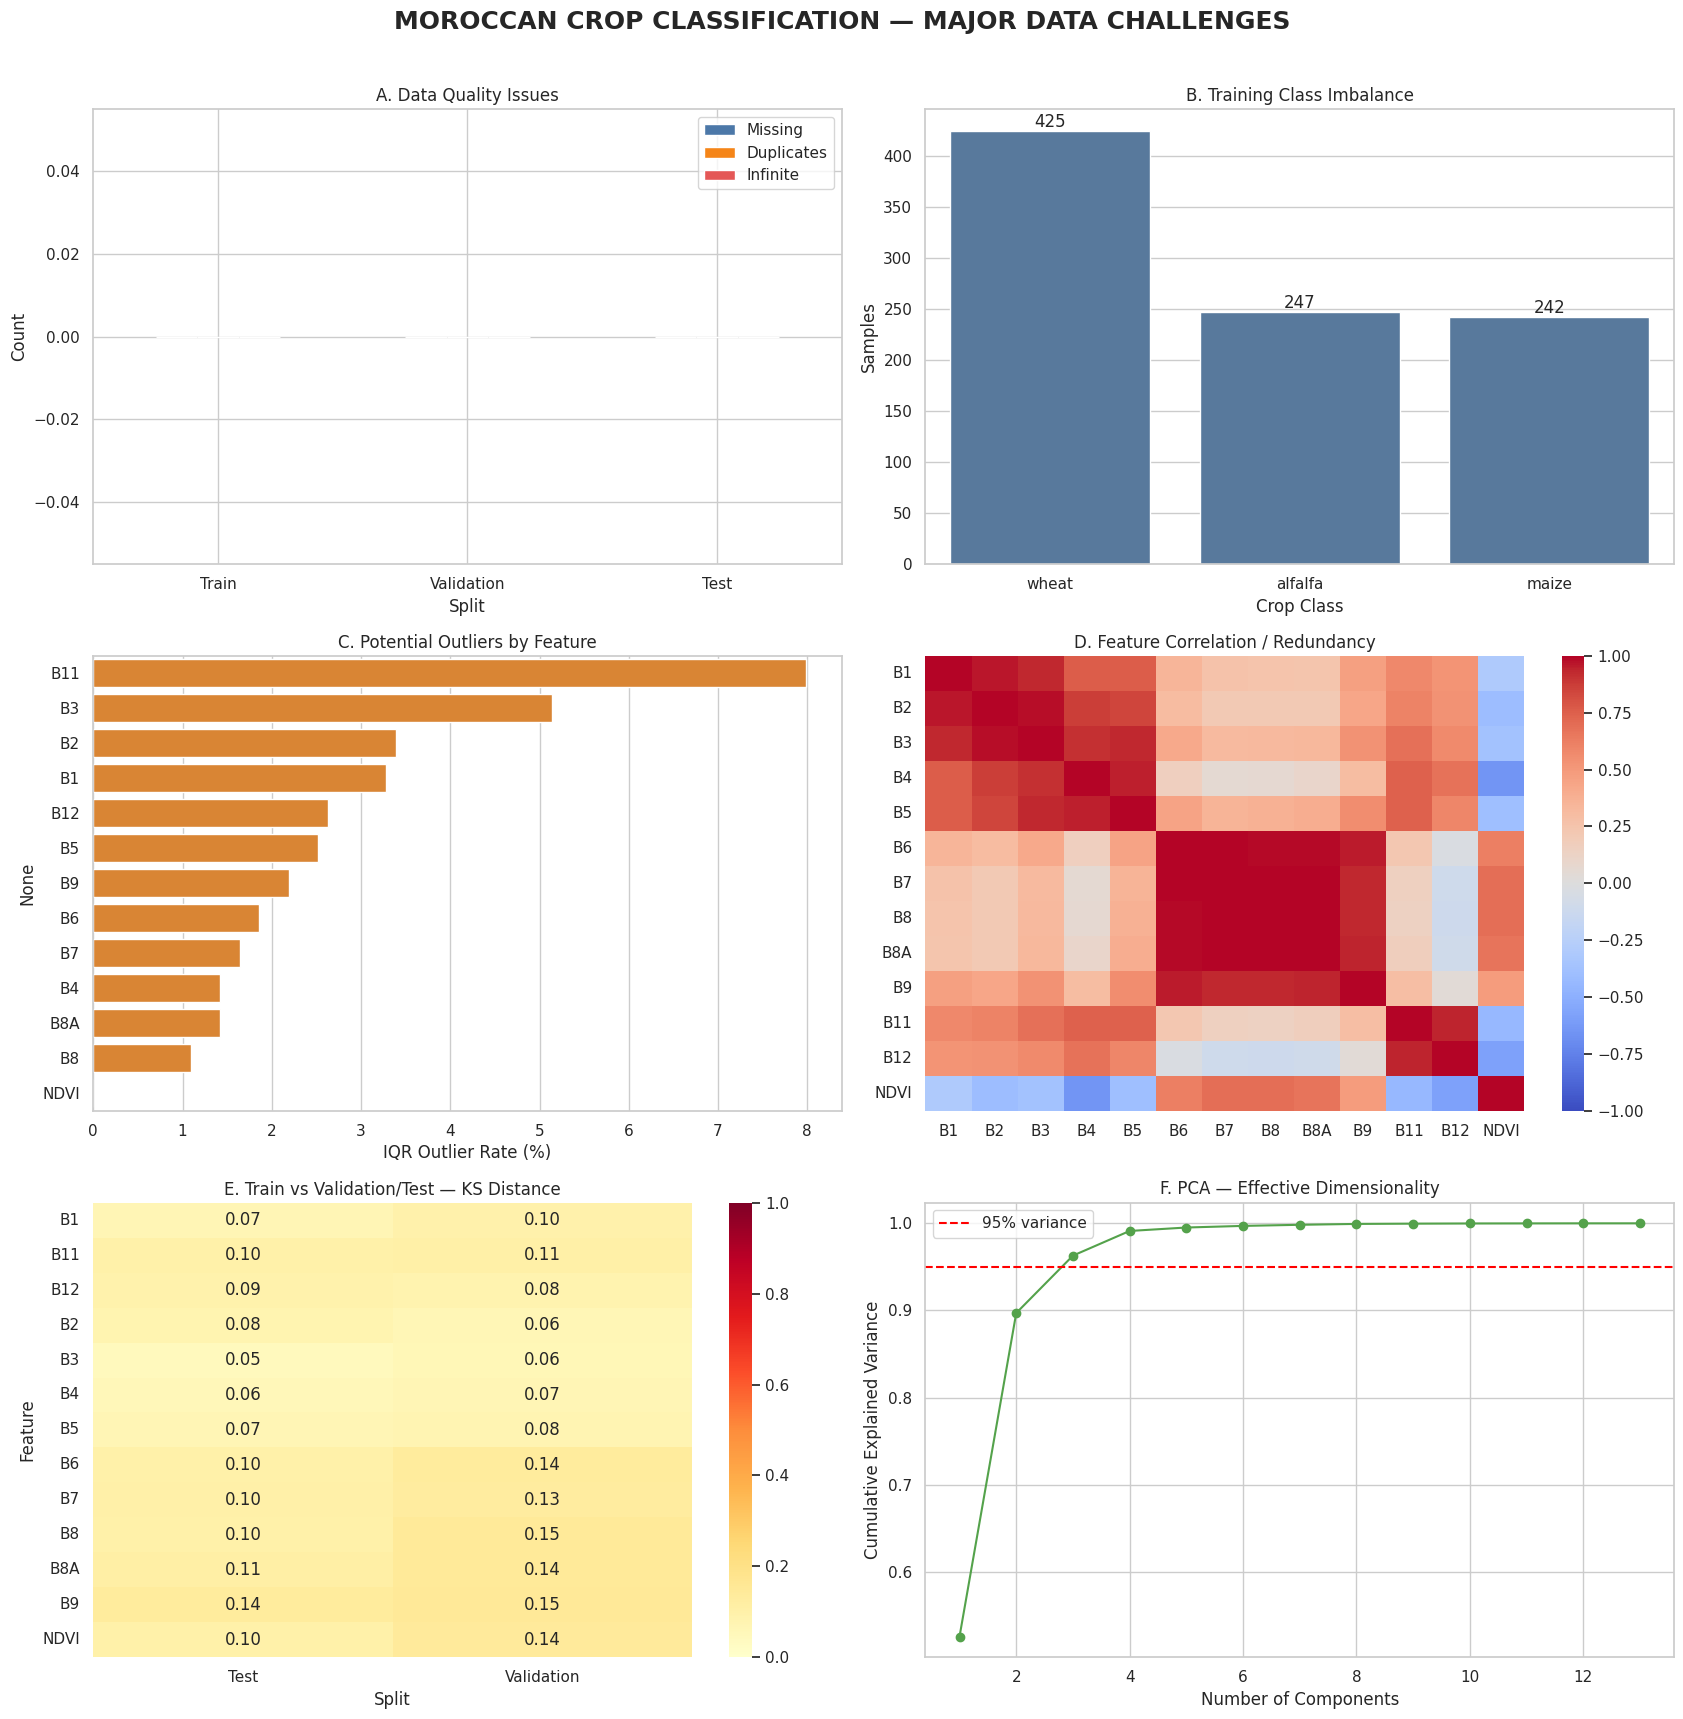


========== DATASET CHALLENGE SUMMARY ==========
Training samples: 914
Input features: 13
Class imbalance ratio: 1.76
Potential outlier features (>5%): 2
Highly correlated feature pairs (|r| >= 0.85): 18
PCA components for 95% variance: 3

Most correlated feature pairs:
B7  B8     0.997805
B8  B8A    0.996286
B7  B8A    0.995800
B6  B7     0.993603
    B8     0.991677
    B8A    0.990511
B2  B3     0.979968
B1  B2     0.963841
B6  B9     0.956186
B4  B5     0.946247
dtype: float64

Largest distribution shift indicators:
Feature      Split  KS Statistic
     B9 Validation      0.149336
     B8 Validation      0.148009
    B8A Validation      0.144654
   NDVI Validation      0.142553
     B9       Test      0.136252
     B6 Validation      0.135594
     B7 Validation      0.131393
    B8A       Test      0.112845
    B11 Validation      0.107863
     B7       Test      0.103280

Note: IQR outliers are not necessarily errors.
KS distances are descriptive, not proof of drift.
Do not use te

In [28]:

# ============================================================
# MAJOR DATASET CHALLENGES — DIAGNOSTIC DASHBOARD
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

# 1. Configuration
splits = {"Train": train, "Validation": val, "Test": test}

target_candidates = [
    "label", "class", "target", "crop", "crop_type",
    "culture", "Crop", "Label", "Class"
]

target = next(
    (c for c in target_candidates if c in train.columns),
    None
)

if target is None:
    extra = [c for c in train.columns if c not in test.columns]
    if len(extra) == 1:
        target = extra[0]
    else:
        raise ValueError(
            f"Cannot identify target. Train-only columns: {extra}"
        )

features = [
    c for c in train.select_dtypes(include=np.number).columns
    if c in val.columns and c in test.columns and c != target
]

if not features:
    raise ValueError("No common numeric features found.")

X_train = train[features].replace(
    [np.inf, -np.inf], np.nan
)

X_val = val[features].replace(
    [np.inf, -np.inf], np.nan
)

X_test = test[features].replace(
    [np.inf, -np.inf], np.nan
)

# 2. Quality indicators
quality = []

for name, df in splits.items():
    numeric = df.select_dtypes(include=np.number)

    quality.append({
        "Split": name,
        "Missing": int(df.isna().sum().sum()),
        "Duplicates": int(df.duplicated().sum()),
        "Infinite": int(np.isinf(numeric.to_numpy()).sum())
    })

quality_df = pd.DataFrame(quality).set_index("Split")

# 3. Class imbalance
class_counts = train[target].value_counts()

# 4. Outlier rate using training IQR thresholds
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_rate = (
    (X_train.lt(lower) | X_train.gt(upper))
    .mean() * 100
).sort_values(ascending=False)

# 5. Feature correlation
corr = X_train.corr()
corr_abs = corr.abs()

upper_triangle = corr_abs.where(
    np.triu(np.ones(corr_abs.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .loc[lambda x: x >= 0.85]
    .sort_values(ascending=False)
)

# 6. Distribution shift indicators
# KS statistic measures distance between feature distributions
shift_rows = []

for feature in features:
    a = X_train[feature].dropna()

    for split_name, X_other in [
        ("Validation", X_val),
        ("Test", X_test)
    ]:
        b = X_other[feature].dropna()

        statistic = (
            ks_2samp(a, b).statistic
            if len(a) and len(b)
            else np.nan
        )

        shift_rows.append({
            "Feature": feature,
            "Split": split_name,
            "KS Statistic": statistic
        })

shift_df = pd.DataFrame(shift_rows)

shift_pivot = shift_df.pivot(
    index="Feature",
    columns="Split",
    values="KS Statistic"
)

# 7. PCA dimensionality
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_train)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

pca = PCA()
pca.fit(X_scaled)

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

# ============================================================
# VISUAL DASHBOARD
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(17, 17))

# A. Data quality
quality_df.plot(
    kind="bar",
    ax=axes[0, 0],
    color=["#4C78A8", "#F58518", "#E45756"]
)
axes[0, 0].set_title("A. Data Quality Issues")
axes[0, 0].set_ylabel("Count")
axes[0, 0].tick_params(axis="x", rotation=0)

# B. Class imbalance
sns.barplot(
    x=class_counts.index.astype(str),
    y=class_counts.values,
    ax=axes[0, 1],
    color="#4C78A8"
)
axes[0, 1].set_title("B. Training Class Imbalance")
axes[0, 1].set_xlabel("Crop Class")
axes[0, 1].set_ylabel("Samples")

for i, count in enumerate(class_counts.values):
    axes[0, 1].text(
        i, count, str(count),
        ha="center", va="bottom"
    )

# C. Outlier rates
sns.barplot(
    x=outlier_rate.values,
    y=outlier_rate.index,
    ax=axes[1, 0],
    color="#F58518"
)
axes[1, 0].set_title("C. Potential Outliers by Feature")
axes[1, 0].set_xlabel("IQR Outlier Rate (%)")

# D. Feature correlation
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[1, 1]
)
axes[1, 1].set_title("D. Feature Correlation / Redundancy")

# E. Distribution shifts
sns.heatmap(
    shift_pivot,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    ax=axes[2, 0]
)
axes[2, 0].set_title(
    "E. Train vs Validation/Test — KS Distance"
)

# F. Dimensionality
axes[2, 1].plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    color="#54A24B"
)
axes[2, 1].axhline(
    0.95,
    color="red",
    linestyle="--",
    label="95% variance"
)
axes[2, 1].set_title(
    "F. PCA — Effective Dimensionality"
)
axes[2, 1].set_xlabel("Number of Components")
axes[2, 1].set_ylabel("Cumulative Explained Variance")
axes[2, 1].legend()

fig.suptitle(
    "MOROCCAN CROP CLASSIFICATION — MAJOR DATA CHALLENGES",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

# ============================================================
# CONCISE DIAGNOSTIC SUMMARY
# ============================================================

n95 = np.searchsorted(cumulative_variance, 0.95) + 1

print("\n========== DATASET CHALLENGE SUMMARY ==========")
print(f"Training samples: {len(train)}")
print(f"Input features: {len(features)}")
print(f"Class imbalance ratio: "
      f"{class_counts.max()/class_counts.min():.2f}")
print(f"Potential outlier features (>5%): "
      f"{(outlier_rate > 5).sum()}")
print(f"Highly correlated feature pairs (|r| >= 0.85): "
      f"{len(high_corr_pairs)}")
print(f"PCA components for 95% variance: {n95}")

print("\nMost correlated feature pairs:")
print(high_corr_pairs.head(10))

print("\nLargest distribution shift indicators:")
print(
    shift_df.sort_values(
        "KS Statistic", ascending=False
    ).head(10).to_string(index=False)
)

print("\nNote: IQR outliers are not necessarily errors.")
print("KS distances are descriptive, not proof of drift.")
print("Do not use test data to select preprocessing or models.")



## 1. Feature Redundancy — PCA vs Feature Selection

Compare original features, PCA, and Mutual Information using SVM with stratified 5-fold cross-validation. Evaluate Macro-F1 to identify the best feature representation.


,Method,Macro-F1 Mean,Macro-F1 Std,CV Scores
5,PCA (6),0.890624,0.027427,"[0.8486, 0.8841, 0.8822, 0.9078, 0.9304]"
7,PCA (8),0.889603,0.026857,"[0.8486, 0.8841, 0.8822, 0.9027, 0.9304]"
0,Original (13 features),0.888514,0.025242,"[0.8486, 0.8841, 0.8822, 0.9027, 0.925]"
3,PCA (4),0.877453,0.032121,"[0.8337, 0.8845, 0.8515, 0.892, 0.9255]"
1,PCA (3),0.841762,0.040365,"[0.7649, 0.8784, 0.8404, 0.859, 0.8661]"
8,Mutual Information (8),0.827977,0.033523,"[0.8488, 0.8184, 0.8669, 0.7688, 0.837]"
6,Mutual Information (6),0.797476,0.021061,"[0.7759, 0.8074, 0.8144, 0.7688, 0.8208]"
4,Mutual Information (4),0.785787,0.051325,"[0.7857, 0.8024, 0.8207, 0.6881, 0.8321]"
2,Mutual Information (3),0.772928,0.052118,"[0.7356, 0.7847, 0.8257, 0.6926, 0.8261]"


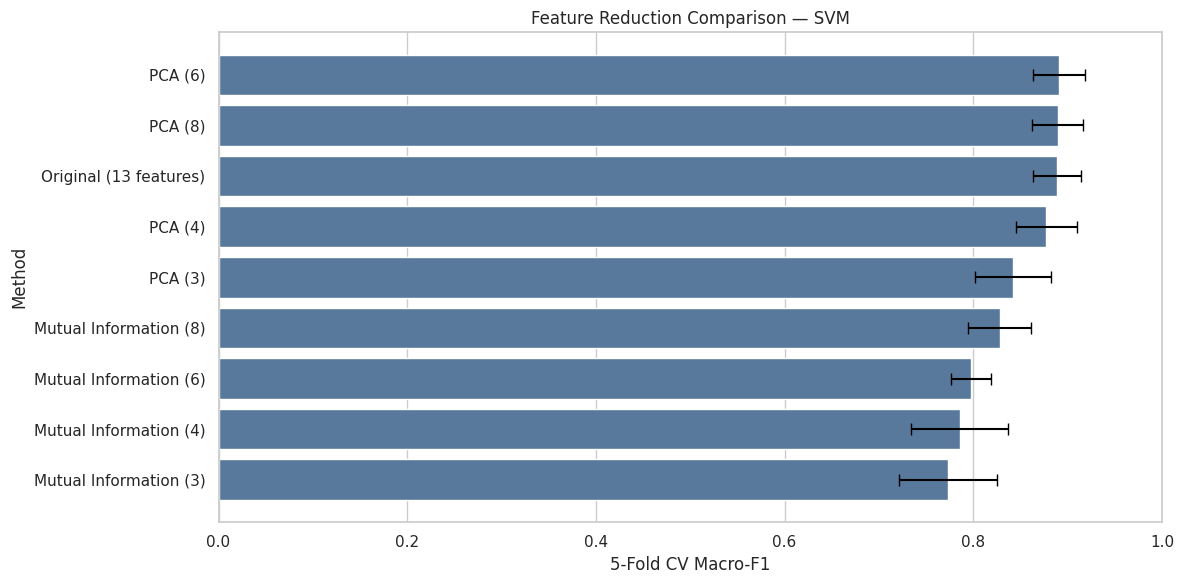

In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate
from functools import partial

# Features and target from previous EDA
X = train[features].replace([np.inf, -np.inf], np.nan)
y = train[target]

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

results = []

# Baseline + PCA + Mutual Information
experiments = {"Original (13 features)": None}

for k in [3, 4, 6, 8]:
    experiments[f"PCA ({k})"] = PCA(n_components=k)
    experiments[f"Mutual Information ({k})"] = SelectKBest(
        score_func=partial(mutual_info_classif, random_state=42),
        k=k
    )

for name, reducer in experiments.items():

    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]

    if reducer is not None:
        steps.append(("feature_selection", reducer))

    steps.append(("svm", SVC(kernel="rbf")))

    pipeline = Pipeline(steps)

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )["test_score"]

    results.append({
        "Method": name,
        "Macro-F1 Mean": scores.mean(),
        "Macro-F1 Std": scores.std(),
        "CV Scores": np.round(scores, 4).tolist()
    })

results_df = pd.DataFrame(results).sort_values(
    "Macro-F1 Mean", ascending=False
)

display(results_df)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Macro-F1 Mean",
    y="Method",
    color="#4C78A8"
)

plt.errorbar(
    x=results_df["Macro-F1 Mean"],
    y=np.arange(len(results_df)),
    xerr=results_df["Macro-F1 Std"],
    fmt="none",
    ecolor="black",
    capsize=4
)

plt.title("Feature Reduction Comparison — SVM")
plt.xlabel("5-Fold CV Macro-F1")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

results_df.to_csv(
    "/kaggle/working/feature_reduction_results.csv",
    index=False
)



### Feature Reduction — Results & Conclusions

- **Original:** 13 features → 13 (no reduction), Macro-F1 ≈ 0.89.
- **PCA (3):** 13 → 3 components (−10), Macro-F1 ≈ 0.84.
- **PCA (4):** 13 → 4 components (−9), Macro-F1 ≈ 0.88.
- **PCA (6):** 13 → 6 components (−7), Macro-F1 ≈ 0.89.
- **PCA (8):** 13 → 8 components (−5), Macro-F1 ≈ 0.89.
- **Mutual Information (3, 4, 6, 8):** 13 → 3, 4, 6, 8 selected features, respectively. Lower performance than PCA.

**Conclusion:**
- PCA (6) achieves the best balance between dimensionality reduction and predictive performance.
- PCA (4) is promising for quantum models requiring fewer qubits.
- PCA creates new components, while Mutual Information selects existing features.
- We will retain PCA (4), PCA (6), and Original (13) for further experiments.



## 2. Limited Training Data — Regularization Analysis

Evaluate the impact of SVM regularization on a small dataset (914 samples). Compare different C values using PCA (6) and Stratified 5-Fold Cross-Validation to identify overfitting and improve generalization.


,C,Train F1,Validation F1,Std,Overfitting Gap
0,0.01,0.5149,0.5125,0.0296,0.0024
1,0.10,0.8570,0.8560,0.0312,0.0010
2,1.00,0.9045,0.8906,0.0274,0.0138
3,10.00,0.9388,0.9095,0.0303,0.0293
4,100.00,0.9567,0.9174,0.0207,0.0393
5,1000.00,0.9723,0.8988,0.0194,0.0734


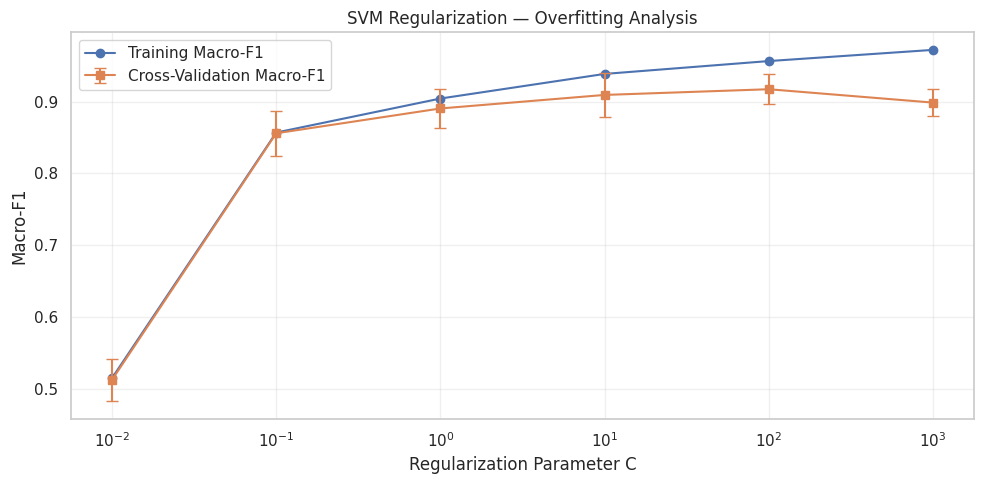

Best C: 100.0


In [30]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

X = train[features].replace([np.inf, -np.inf], np.nan)
y = train[target]

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

C_values = [0.01, 0.1, 1, 10, 100, 1000]
results = []

for C in C_values:

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=6)),
        ("svm", SVC(kernel="rbf", C=C, gamma="scale"))
    ])

    scores = cross_validate(
        pipeline,
        X, y,
        cv=cv,
        scoring="f1_macro",
        return_train_score=True,
        n_jobs=-1
    )

    results.append({
        "C": C,
        "Train F1": scores["train_score"].mean(),
        "Validation F1": scores["test_score"].mean(),
        "Std": scores["test_score"].std(),
        "Overfitting Gap": (
            scores["train_score"].mean()
            - scores["test_score"].mean()
        )
    })

reg_results = pd.DataFrame(results)

display(reg_results.round(4))

# Visualization
plt.figure(figsize=(10, 5))

plt.plot(
    reg_results["C"],
    reg_results["Train F1"],
    marker="o",
    label="Training Macro-F1"
)

plt.errorbar(
    reg_results["C"],
    reg_results["Validation F1"],
    yerr=reg_results["Std"],
    marker="s",
    capsize=4,
    label="Cross-Validation Macro-F1"
)

plt.xscale("log")
plt.xlabel("Regularization Parameter C")
plt.ylabel("Macro-F1")
plt.title("SVM Regularization — Overfitting Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Best C:",
    reg_results.loc[
        reg_results["Validation F1"].idxmax(), "C"
    ]
)



### Regularization Analysis — Results

- **Best C = 100:** Highest CV Macro-F1 = 0.9174 (91.74%).
- **C = 0.01:** Underfitting (Macro-F1 = 0.5125).
- **C = 1:** Good generalization (Macro-F1 = 0.8906).
- **C = 100:** Best performance with a moderate overfitting gap (0.0393).
- **C = 1000:** Overfitting increases (gap = 0.0734), while CV performance drops to 0.8988.

**Conclusion:**
- PCA (6) + SVM (C=100) is our best configuration so far.
- Cross-validation Macro-F1 improved from approximately 0.89 to **0.9174**.
- We will retain C=100 for further evaluation.
µ


## 3.2 Class Imbalance — Advanced Resampling Experiments

Compare multiple imbalance-handling strategies: Random Oversampling, SMOTE, Borderline-SMOTE, ADASYN, Random Undersampling, SMOTE-Tomek, SMOTE-ENN, and Class Weights.

All resampling is applied only to training folds to prevent data leakage. Performance is evaluated using Stratified 5-Fold CV and Macro-F1.


,Method,CV Macro-F1,CV Std,Train Macro-F1,Overfitting Gap,Fit Time (s)
0,Baseline,0.9174,0.0207,0.9567,0.0393,0.0414
1,Random Oversampling,0.9097,0.0278,0.9544,0.0448,0.0384
2,SMOTE,0.9089,0.0221,0.9528,0.0438,0.0411
3,Class Weights,0.9070,0.0306,0.9515,0.0445,0.0262
4,Random Undersampling,0.9058,0.0295,0.9398,0.0340,0.0230
5,SMOTE-Tomek,0.9034,0.0236,0.9494,0.0460,0.0493
6,Borderline-SMOTE,0.9010,0.0245,0.9440,0.0430,0.0495
7,ADASYN,0.8958,0.0351,0.9430,0.0472,0.0495
8,SMOTE-ENN,0.8893,0.0270,0.9063,0.0170,0.0358


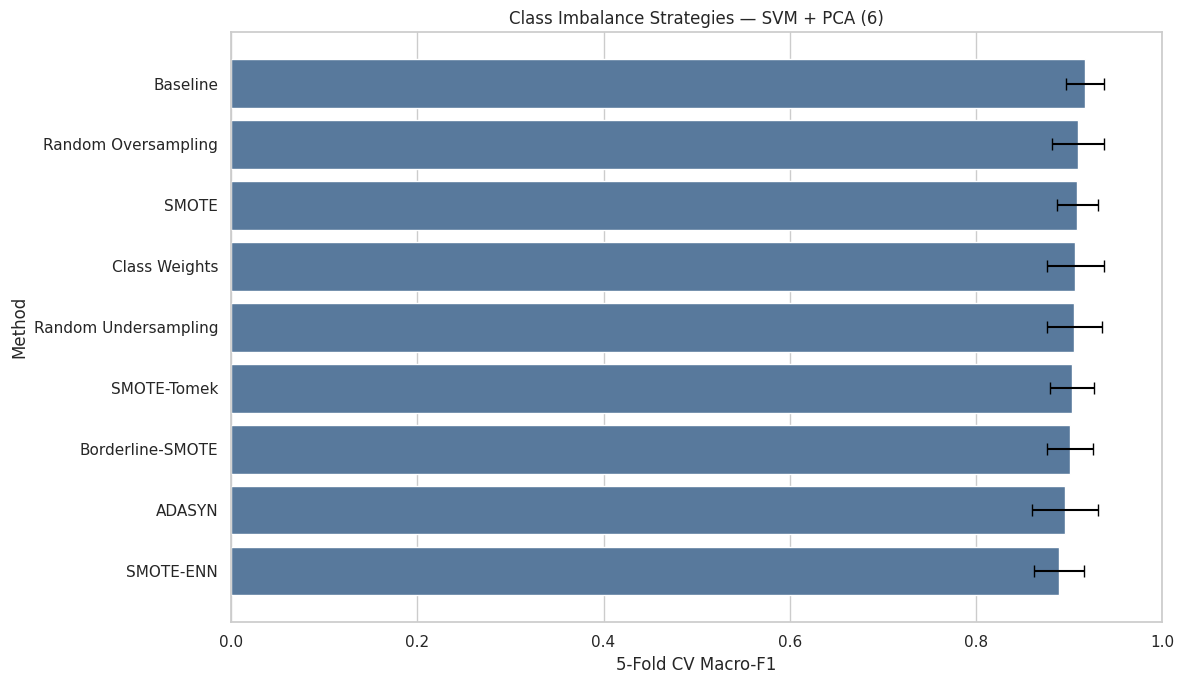

Best strategy: Baseline
Best CV Macro-F1: 0.9174


In [31]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import (
    RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN
)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek, SMOTEENN

# Data
X = train[features].replace([np.inf, -np.inf], np.nan)
y = train[target]

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

# Sampling strategies
strategies = {
    "Baseline": None,
    "Class Weights": None,
    "Random Oversampling": RandomOverSampler(random_state=42),
    "SMOTE": SMOTE(random_state=42),
    "Borderline-SMOTE": BorderlineSMOTE(random_state=42),
    "ADASYN": ADASYN(random_state=42),
    "Random Undersampling": RandomUnderSampler(random_state=42),
    "SMOTE-Tomek": SMOTETomek(random_state=42),
    "SMOTE-ENN": SMOTEENN(random_state=42)
}

results = []

for name, sampler in strategies.items():

    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=6))
    ]

    if sampler is not None:
        steps.append(("sampler", sampler))

    steps.append((
        "svm",
        SVC(
            kernel="rbf",
            C=100,
            gamma="scale",
            class_weight="balanced" if name == "Class Weights" else None
        )
    ))

    model = Pipeline(steps)

    try:
        scores = cross_validate(
            model,
            X, y,
            cv=cv,
            scoring="f1_macro",
            return_train_score=True,
            n_jobs=-1,
            error_score="raise"
        )

        results.append({
            "Method": name,
            "CV Macro-F1": scores["test_score"].mean(),
            "CV Std": scores["test_score"].std(),
            "Train Macro-F1": scores["train_score"].mean(),
            "Overfitting Gap": (
                scores["train_score"].mean()
                - scores["test_score"].mean()
            ),
            "Fit Time (s)": scores["fit_time"].mean()
        })

    except Exception as e:
        print(f"{name} failed: {e}")

results_df = pd.DataFrame(results).sort_values(
    "CV Macro-F1", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

# Visualization
plt.figure(figsize=(12, 7))

sns.barplot(
    data=results_df,
    x="CV Macro-F1",
    y="Method",
    color="#4C78A8"
)

plt.errorbar(
    x=results_df["CV Macro-F1"],
    y=np.arange(len(results_df)),
    xerr=results_df["CV Std"],
    fmt="none",
    ecolor="black",
    capsize=4
)

plt.xlim(0, 1)
plt.title("Class Imbalance Strategies — SVM + PCA (6)")
plt.xlabel("5-Fold CV Macro-F1")
plt.tight_layout()
plt.show()

print(
    "Best strategy:",
    results_df.iloc[0]["Method"]
)
print(
    "Best CV Macro-F1:",
    round(results_df.iloc[0]["CV Macro-F1"], 4)
)

results_df.to_csv(
    "/kaggle/working/imbalance_comparison_results.csv",
    index=False
)



### Class Imbalance — Experimental Results

- **Best Method:** Baseline (No Resampling).
- **Best Macro-F1:** 0.9174 (91.74%).
- Random Oversampling and SMOTE achieved competitive results but did not outperform the baseline.
- Class Weights, Undersampling, ADASYN, and SMOTE variants provided no improvement.

**Conclusion:**
- Class imbalance does not require correction for our current SVM configuration.
- Resampling methods may introduce noise or remove useful information.
- **Selected Model: SVM + PCA (6) + C=100, without resampling.**
- Next: Compare different classical ML algorithms.



## 4. Classical Machine Learning — Model Comparison

Compare SVM, Random Forest, ExtraTrees, XGBoost, LightGBM, CatBoost, Logistic Regression, and MLP using Stratified 5-Fold Cross-Validation.

Evaluate Macro-F1, overfitting, and training time. Compare PCA (6) against original features to identify the strongest classical baseline.


SVM (C=100) | Original | F1=0.9193
Random Forest | Original | F1=0.8816
ExtraTrees | Original | F1=0.8839
XGBoost | Original | F1=0.8877


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

LightGBM | Original | F1=0.8995
CatBoost | Original | F1=0.8837
Logistic Regression | Original | F1=0.8986
MLP | Original | F1=0.8763
SVM (C=100) | PCA (6) | F1=0.9174
Random Forest | PCA (6) | F1=0.9134
ExtraTrees | PCA (6) | F1=0.9171
XGBoost | PCA (6) | F1=0.9060


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

LightGBM | PCA (6) | F1=0.9105


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


CatBoost | PCA (6) | F1=0.9147
Logistic Regression | PCA (6) | F1=0.8714
MLP | PCA (6) | F1=0.8684


,Model,Features,CV Macro-F1,CV Std,Train Macro-F1,Overfitting Gap,Total Time (s)
0,SVM (C=100),Original,0.9193,0.0243,0.9686,0.0493,0.0989
1,SVM (C=100),PCA (6),0.9174,0.0207,0.9567,0.0393,0.0987
2,ExtraTrees,PCA (6),0.9171,0.0328,1.0000,0.0829,1.2991
3,CatBoost,PCA (6),0.9147,0.0320,0.9612,0.0465,4.4112
4,Random Forest,PCA (6),0.9134,0.0258,1.0000,0.0866,2.0077
5,LightGBM,PCA (6),0.9105,0.0232,1.0000,0.0895,3.8584
6,XGBoost,PCA (6),0.9060,0.0232,1.0000,0.0940,1.9433
7,LightGBM,Original,0.8995,0.0195,0.9986,0.0991,9.8256
8,Logistic Regression,Original,0.8986,0.0411,0.9011,0.0025,0.0978
9,XGBoost,Original,0.8877,0.0231,0.9982,0.1105,2.6485


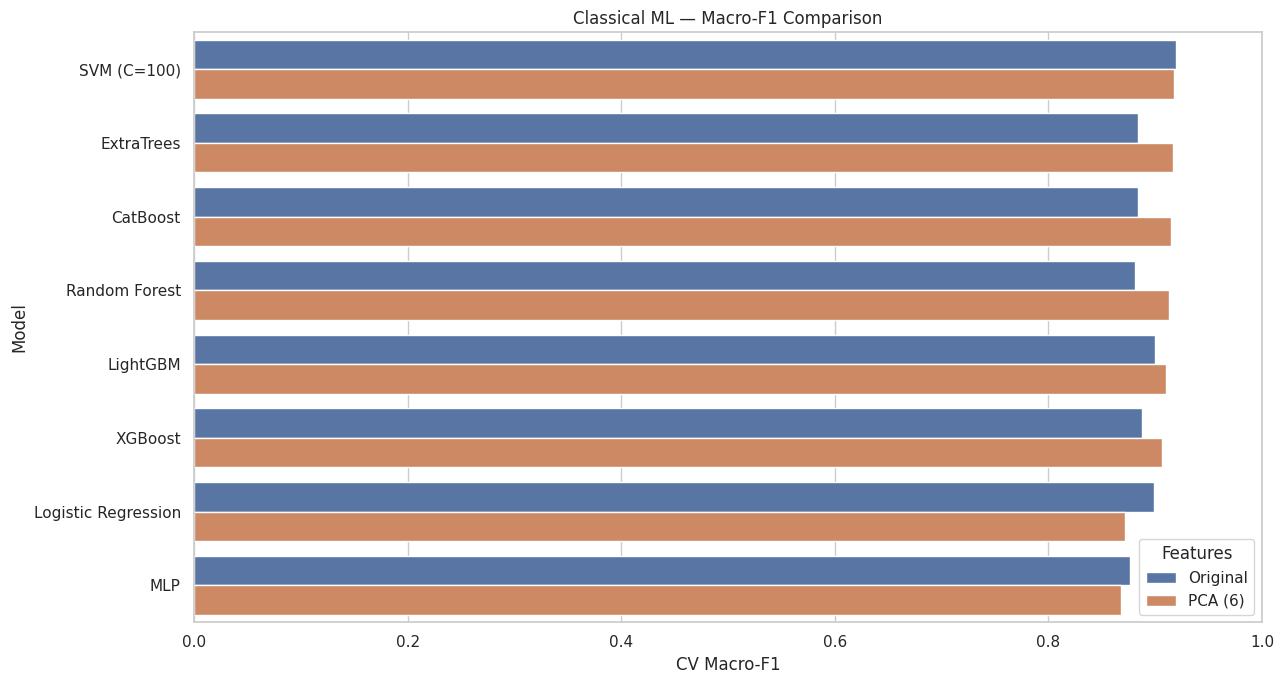

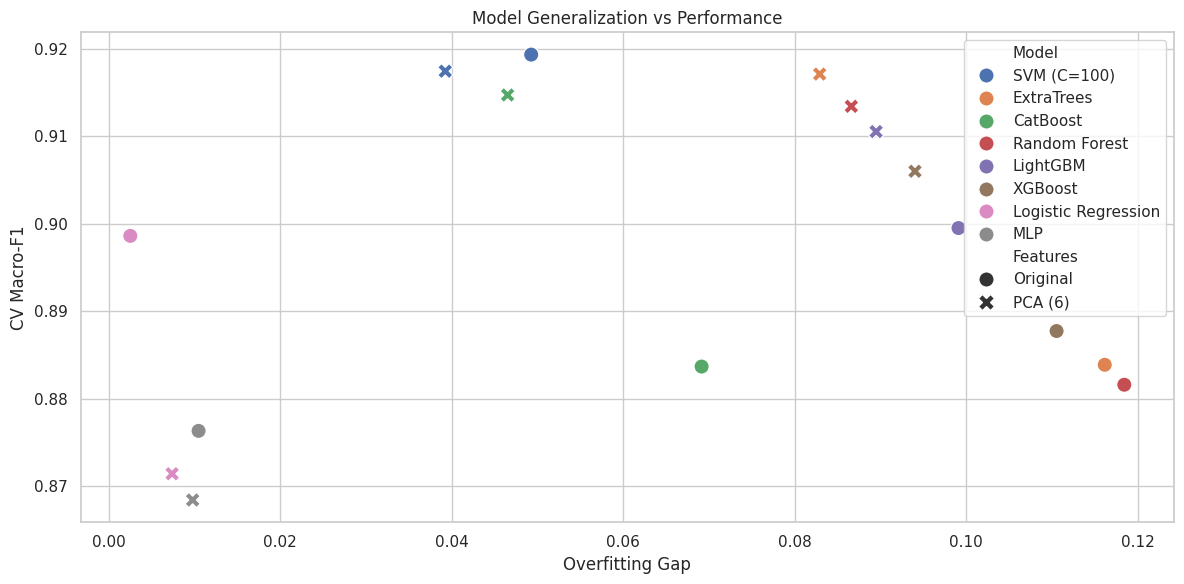


BEST CLASSICAL CONFIGURATION:
Model              SVM (C=100)
Features              Original
CV Macro-F1            0.91932
CV Std                0.024299
Train Macro-F1        0.968588
Overfitting Gap       0.049268
Total Time (s)        0.098884


In [32]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import LabelEncoder

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Dataset
X = train[features].replace([np.inf, -np.inf], np.nan)

encoder = LabelEncoder()
y = encoder.fit_transform(train[target])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "SVM (C=100)": SVC(C=100, kernel="rbf"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=42, n_jobs=1
    ),
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=300, random_state=42, n_jobs=1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4,
        learning_rate=0.05, random_state=42,
        n_jobs=1, eval_metric="mlogloss"
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300, learning_rate=0.05,
        verbosity=-1, random_state=42,
        n_jobs=1
    ),
    "CatBoost": CatBoostClassifier(
        iterations=300, depth=5,
        learning_rate=0.05, verbose=False,
        random_seed=42, thread_count=1
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=500, early_stopping=True,
        random_state=42
    )
}

results = []

for feature_method in ["Original", "PCA (6)"]:
    for name, model in models.items():

        steps = [
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]

        if feature_method == "PCA (6)":
            steps.append(("pca", PCA(n_components=6)))

        steps.append(("model", model))
        pipeline = Pipeline(steps)

        start = time.perf_counter()

        scores = cross_validate(
            pipeline,
            X, y,
            cv=cv,
            scoring="f1_macro",
            return_train_score=True,
            n_jobs=-1,
            error_score="raise"
        )

        elapsed = time.perf_counter() - start

        results.append({
            "Model": name,
            "Features": feature_method,
            "CV Macro-F1": scores["test_score"].mean(),
            "CV Std": scores["test_score"].std(),
            "Train Macro-F1": scores["train_score"].mean(),
            "Overfitting Gap": (
                scores["train_score"].mean()
                - scores["test_score"].mean()
            ),
            "Total Time (s)": elapsed
        })

        print(
            f"{name} | {feature_method} | "
            f"F1={scores['test_score'].mean():.4f}"
        )

results_df = pd.DataFrame(results).sort_values(
    "CV Macro-F1", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

# Performance comparison
plt.figure(figsize=(13, 7))

sns.barplot(
    data=results_df,
    x="CV Macro-F1",
    y="Model",
    hue="Features"
)

plt.xlim(0, 1)
plt.title("Classical ML — Macro-F1 Comparison")
plt.tight_layout()
plt.show()

# Overfitting analysis
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=results_df,
    x="Overfitting Gap",
    y="CV Macro-F1",
    hue="Model",
    style="Features",
    s=120
)

plt.title("Model Generalization vs Performance")
plt.tight_layout()
plt.show()

# Save results
results_df.to_csv(
    "/kaggle/working/classical_models_comparison.csv",
    index=False
)

print("\nBEST CLASSICAL CONFIGURATION:")
print(results_df.iloc[0].to_string())



### Classical ML — Results & Conclusions

- **SVM (C=100):** Best overall performance, Macro-F1 ≈ 0.917.
- **ExtraTrees, CatBoost, Random Forest:** Strong alternatives with competitive results.
- **LightGBM and XGBoost:** Good performance, but no clear improvement over SVM.
- **Logistic Regression and MLP:** Slightly lower performance.
- **PCA (6):** Improves several tree-based models, especially CatBoost, ExtraTrees, and Random Forest.
- **Original Features:** Competitive for SVM and Logistic Regression.

**Conclusion:**
- SVM remains our strongest classical baseline.
- PCA (6) is an effective feature representation for several models.
- Next: Hyperparameter optimization of the strongest classical models.



## 5. Hyperparameter Optimization — Classical ML

Optimize SVM, CatBoost, ExtraTrees, and XGBoost using Optuna and Stratified 5-Fold Cross-Validation.

Compare original features and PCA (6), maximizing Macro-F1 while monitoring overfitting and training time.



Optimizing SVM ...


  0%|          | 0/30 [00:00<?, ?it/s]


Optimizing ExtraTrees ...


  0%|          | 0/30 [00:00<?, ?it/s]


Optimizing XGBoost ...


  0%|          | 0/30 [00:00<?, ?it/s]


Optimizing CatBoost ...


  0%|          | 0/30 [00:00<?, ?it/s]

,Model,Best CV Macro-F1,CV Std,Best Params,Optimization Time (s)
0,XGBoost,0.926406,0.017170,"{'features': 'PCA (6)', 'n_estimators': 456, '...",54.172161
1,CatBoost,0.923014,0.026015,"{'features': 'PCA (6)', 'iterations': 376, 'de...",382.712903
2,SVM,0.921637,0.019710,"{'features': 'Original', 'C': 270.457896355073...",3.578326
3,ExtraTrees,0.920550,0.028971,"{'features': 'PCA (6)', 'n_estimators': 199, '...",56.656276


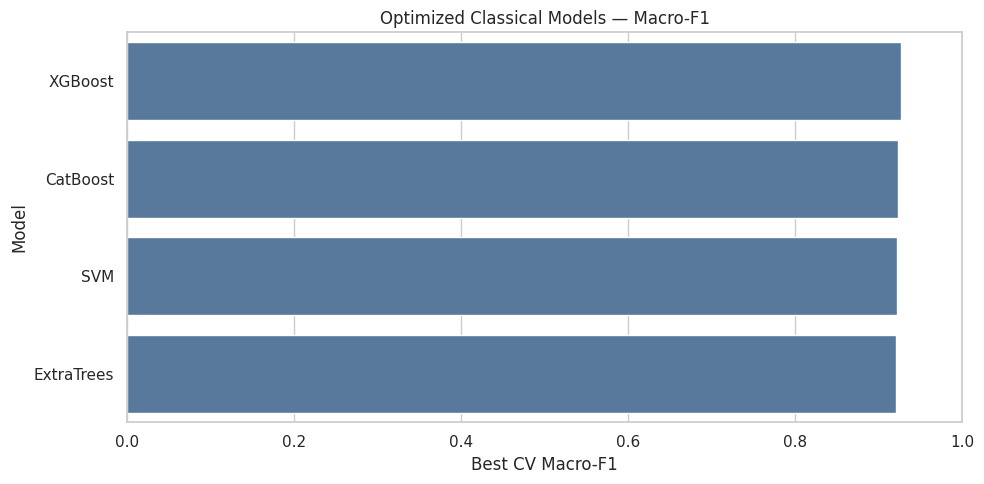


XGBoost
CV Macro-F1: 0.9264
Best Parameters: {'features': 'PCA (6)', 'n_estimators': 456, 'max_depth': 5, 'learning_rate': 0.11237829284418087, 'subsample': 0.6158933981424466, 'colsample_bytree': 0.6770961861723724}

CatBoost
CV Macro-F1: 0.923
Best Parameters: {'features': 'PCA (6)', 'iterations': 376, 'depth': 6, 'learning_rate': 0.06439034179689859, 'l2_leaf_reg': 1.4341447148178947}

SVM
CV Macro-F1: 0.9216
Best Parameters: {'features': 'Original', 'C': 270.4578963550736, 'gamma': 0.027548394540701737}

ExtraTrees
CV Macro-F1: 0.9205
Best Parameters: {'features': 'PCA (6)', 'n_estimators': 199, 'max_depth': 25, 'min_samples_leaf': 1, 'max_features': 'sqrt'}


In [33]:

import optuna
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

# --------------------------------------------------
# 1. Dataset
# --------------------------------------------------

X = train[features].replace([np.inf, -np.inf], np.nan)

encoder = LabelEncoder()
y = encoder.fit_transform(train[target])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# --------------------------------------------------
# 2. Hyperparameter Search
# --------------------------------------------------

models_to_tune = ["SVM", "ExtraTrees", "XGBoost", "CatBoost"]
N_TRIALS = 30

optimization_results = []
best_models = {}

def objective(trial, model_name):

    feature_method = trial.suggest_categorical(
        "features", ["Original", "PCA (6)"]
    )

    if model_name == "SVM":
        model = SVC(
            C=trial.suggest_float("C", 0.1, 1000, log=True),
            gamma=trial.suggest_float(
                "gamma", 0.0001, 1, log=True
            ),
            kernel="rbf"
        )

    elif model_name == "ExtraTrees":
        model = ExtraTreesClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 150, 500
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 30
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf", 1, 5
            ),
            max_features=trial.suggest_categorical(
                "max_features", ["sqrt", "log2", None]
            ),
            random_state=42,
            n_jobs=1
        )

    elif model_name == "XGBoost":
        model = XGBClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 100, 500
            ),
            max_depth=trial.suggest_int(
                "max_depth", 2, 8
            ),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.01, 0.2, log=True
            ),
            subsample=trial.suggest_float(
                "subsample", 0.6, 1.0
            ),
            colsample_bytree=trial.suggest_float(
                "colsample_bytree", 0.6, 1.0
            ),
            random_state=42,
            n_jobs=1,
            eval_metric="mlogloss"
        )

    else:
        model = CatBoostClassifier(
            iterations=trial.suggest_int(
                "iterations", 150, 600
            ),
            depth=trial.suggest_int("depth", 3, 8),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.01, 0.2, log=True
            ),
            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg", 1, 10
            ),
            verbose=False,
            random_seed=42,
            thread_count=1
        )

    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]

    if feature_method == "PCA (6)":
        steps.append(("pca", PCA(n_components=6)))

    steps.append(("model", model))
    pipeline = Pipeline(steps)

    scores = cross_val_score(
        pipeline,
        X, y,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1
    )

    trial.set_user_attr("cv_std", float(scores.std()))

    return float(scores.mean())

# --------------------------------------------------
# 3. Run Optimization
# --------------------------------------------------

for model_name in models_to_tune:

    print(f"\nOptimizing {model_name} ...")
    start = time.perf_counter()

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42)
    )

    study.optimize(
        lambda trial: objective(trial, model_name),
        n_trials=N_TRIALS,
        show_progress_bar=True
    )

    elapsed = time.perf_counter() - start

    best_models[model_name] = study

    optimization_results.append({
        "Model": model_name,
        "Best CV Macro-F1": study.best_value,
        "CV Std": study.best_trial.user_attrs["cv_std"],
        "Best Params": study.best_params,
        "Optimization Time (s)": elapsed
    })

# --------------------------------------------------
# 4. Results
# --------------------------------------------------

tuning_results = pd.DataFrame(
    optimization_results
).sort_values(
    "Best CV Macro-F1", ascending=False
).reset_index(drop=True)

display(tuning_results)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=tuning_results,
    x="Best CV Macro-F1",
    y="Model",
    color="#4C78A8"
)

plt.xlim(0, 1)
plt.title("Optimized Classical Models — Macro-F1")
plt.tight_layout()
plt.show()

for _, row in tuning_results.iterrows():
    print(f"\n{row['Model']}")
    print("CV Macro-F1:", round(row["Best CV Macro-F1"], 4))
    print("Best Parameters:", row["Best Params"])

tuning_results.to_csv(
    "/kaggle/working/optuna_classical_results.csv",
    index=False
)



### Classical ML Optimization — Results

- **XGBoost:** Best CV Macro-F1 = 0.9264 (92.64%), using PCA (6).
- **CatBoost:** Macro-F1 = 0.9230, using PCA (6).
- **SVM:** Macro-F1 = 0.9216, using original features.
- **ExtraTrees:** Macro-F1 = 0.9205, using PCA (6).

**Conclusion:**
- XGBoost is our best classical model so far.
- Hyperparameter tuning improved performance over the previous SVM baseline (0.9174 → 0.9264).
- PCA (6) performs well with three of the four optimized models.
- The differences between models are small and require further validation.
- **Next:** Evaluate the selected models on the official validation set and analyze their classification errors.



## 6. Official Validation — Best Classical Models

Evaluate the four optimized models on the official validation set (150 samples). Compare Macro-F1, accuracy, per-class performance, confusion matrices, and inference time.



===== XGBoost =====
              precision    recall  f1-score   support

     alfalfa       0.87      0.92      0.89        50
       maize       0.89      0.82      0.85        50
       wheat       0.78      0.80      0.79        50

    accuracy                           0.85       150
   macro avg       0.85      0.85      0.85       150
weighted avg       0.85      0.85      0.85       150


===== CatBoost =====
              precision    recall  f1-score   support

     alfalfa       0.92      0.94      0.93        50
       maize       0.89      0.82      0.85        50
       wheat       0.79      0.84      0.82        50

    accuracy                           0.87       150
   macro avg       0.87      0.87      0.87       150
weighted avg       0.87      0.87      0.87       150


===== SVM =====
              precision    recall  f1-score   support

     alfalfa       0.90      0.94      0.92        50
       maize       0.90      0.90      0.90        50
       wheat   

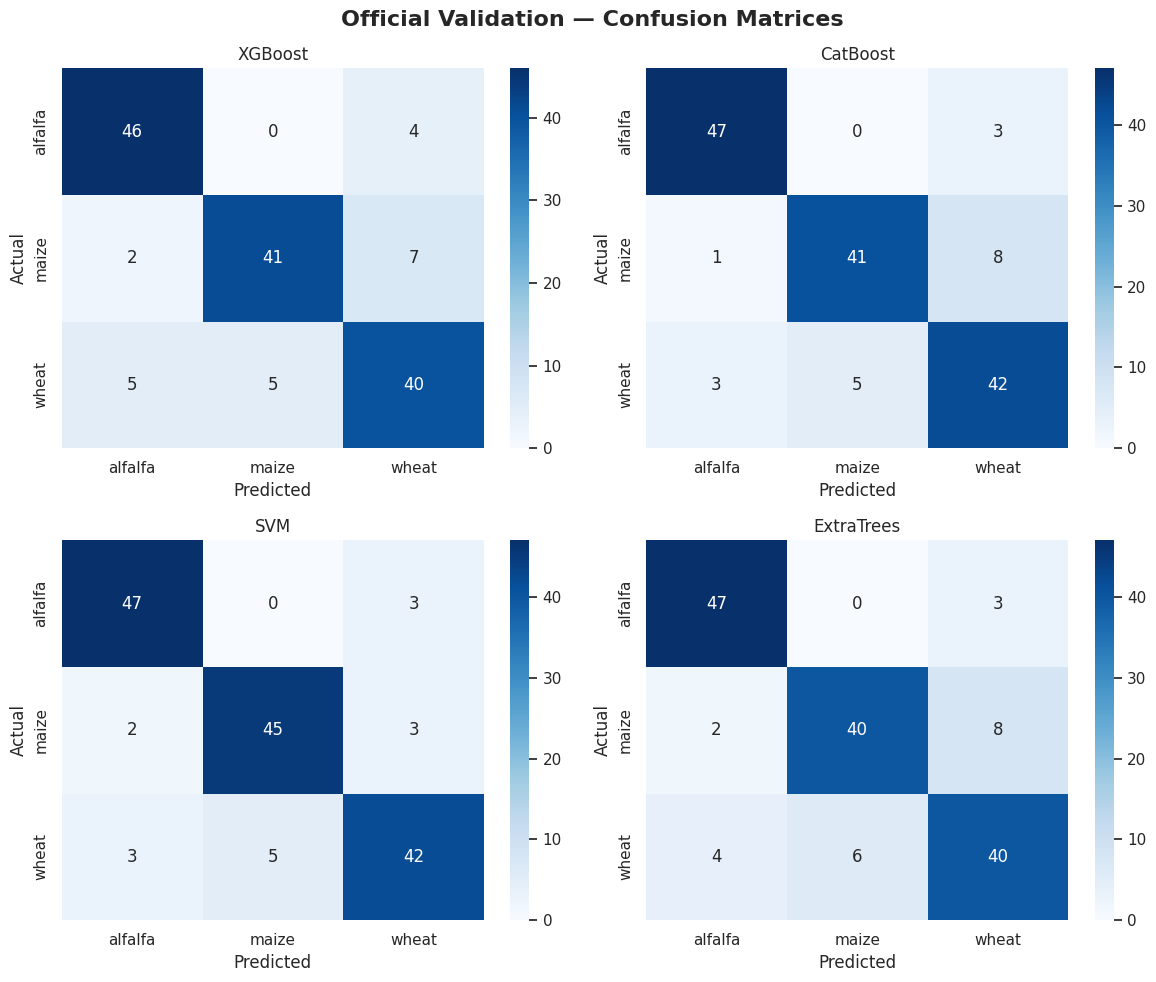

,Model,Macro-F1,Accuracy,Training Time (s),Inference Time (s)
0,SVM,0.8929,0.8933,0.0249,0.0031
1,CatBoost,0.8668,0.8667,1.4625,0.0041
2,XGBoost,0.8465,0.8467,0.4432,0.0059
3,ExtraTrees,0.8460,0.8467,0.3008,0.0169


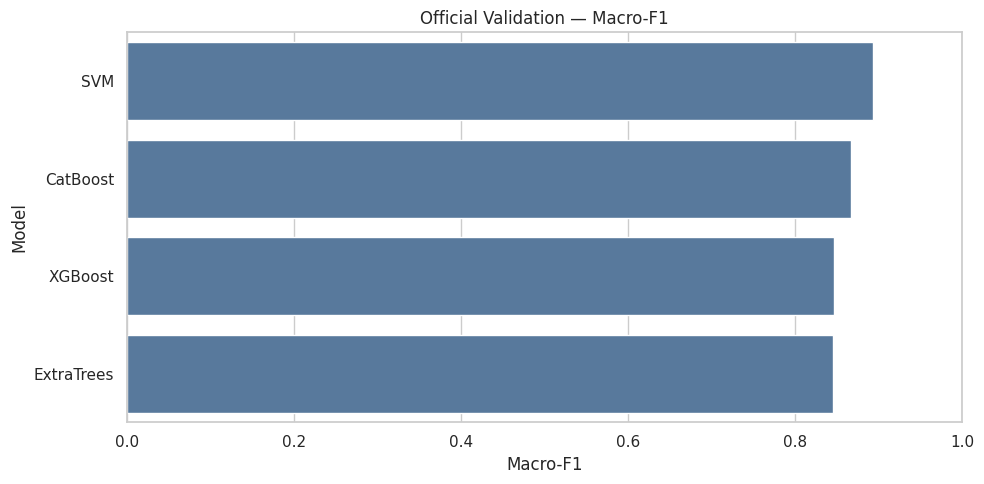


BEST MODEL:
Model                      SVM
Macro-F1              0.892904
Accuracy              0.893333
Training Time (s)     0.024862
Inference Time (s)    0.003053


In [34]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report,
    confusion_matrix
)
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# Data
X_train = train[features].replace([np.inf, -np.inf], np.nan)
X_val = val[features].replace([np.inf, -np.inf], np.nan)

encoder = LabelEncoder()
y_train = encoder.fit_transform(train[target])
y_val = encoder.transform(val[target])

# Optimized configurations
models = {
    "XGBoost": (
        XGBClassifier(
            n_estimators=456,
            max_depth=5,
            learning_rate=0.11237829284418087,
            subsample=0.6158933981424466,
            colsample_bytree=0.6770961861723724,
            random_state=42,
            n_jobs=1,
            eval_metric="mlogloss"
        ),
        True
    ),
    "CatBoost": (
        CatBoostClassifier(
            iterations=376,
            depth=6,
            learning_rate=0.06439034179689859,
            l2_leaf_reg=1.4341447148178947,
            verbose=False,
            random_seed=42,
            thread_count=1
        ),
        True
    ),
    "SVM": (
        SVC(
            kernel="rbf",
            C=270.4578963550736,
            gamma=0.027548394540701737
        ),
        False
    ),
    "ExtraTrees": (
        ExtraTreesClassifier(
            n_estimators=199,
            max_depth=25,
            min_samples_leaf=1,
            max_features="sqrt",
            random_state=42,
            n_jobs=1
        ),
        True
    )
}

results = []
predictions = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, (model, use_pca)) in zip(
    axes.flatten(), models.items()
):
    steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]

    if use_pca:
        steps.append(("pca", PCA(n_components=6)))

    steps.append(("model", model))
    pipeline = Pipeline(steps)

    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    y_pred = pipeline.predict(X_val)
    inference_time = time.perf_counter() - start

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Macro-F1": f1_score(
            y_val, y_pred, average="macro"
        ),
        "Accuracy": accuracy_score(y_val, y_pred),
        "Training Time (s)": fit_time,
        "Inference Time (s)": inference_time
    })

    cm = confusion_matrix(
        y_val, y_pred,
        labels=np.arange(len(encoder.classes_))
    )

    sns.heatmap(
        cm, annot=True, fmt="d",
        cmap="Blues", ax=ax,
        xticklabels=encoder.classes_,
        yticklabels=encoder.classes_
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    print(f"\n===== {name} =====")
    print(classification_report(
        y_val, y_pred,
        target_names=[str(c) for c in encoder.classes_],
        zero_division=0
    ))

plt.suptitle(
    "Official Validation — Confusion Matrices",
    fontsize=16, fontweight="bold"
)
plt.tight_layout()
plt.show()

validation_results = pd.DataFrame(results).sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)

display(validation_results.round(4))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=validation_results,
    x="Macro-F1",
    y="Model",
    color="#4C78A8"
)

plt.xlim(0, 1)
plt.title("Official Validation — Macro-F1")
plt.tight_layout()
plt.show()

validation_results.to_csv(
    "/kaggle/working/official_validation_results.csv",
    index=False
)

print("\nBEST MODEL:")
print(validation_results.iloc[0].to_string())



### Official Validation — Results & Conclusions

- **Best Model: SVM**
- **Macro-F1:** 0.8929 (89.29%).
- **Accuracy:** 89.33%.
- **Training Time:** 0.0249 seconds.
- **Inference Time:** 0.0031 seconds.
- CatBoost, XGBoost, and ExtraTrees achieved slightly lower validation scores.
- XGBoost was best in cross-validation (0.9264), but SVM generalized better on the official validation set.

**Conclusion:**
- SVM is currently our strongest model on official validation.
- Cross-validation performance does not guarantee better performance on unseen data.
- Next: Investigate class-specific errors and begin Quantum ML experiments.



## 7. Error Analysis — Best Classical Model (SVM)

Analyze the SVM's classification errors using per-class precision, recall, F1-score, confusion matrix, and misclassified samples to identify the most challenging crop classes.


,precision,recall,f1-score,support
alfalfa,0.9038,0.9400,0.9216,50.0000
maize,0.9000,0.9000,0.9000,50.0000
wheat,0.8750,0.8400,0.8571,50.0000
accuracy,0.8933,0.8933,0.8933,0.8933
macro avg,0.8929,0.8933,0.8929,150.0000
weighted avg,0.8929,0.8933,0.8929,150.0000


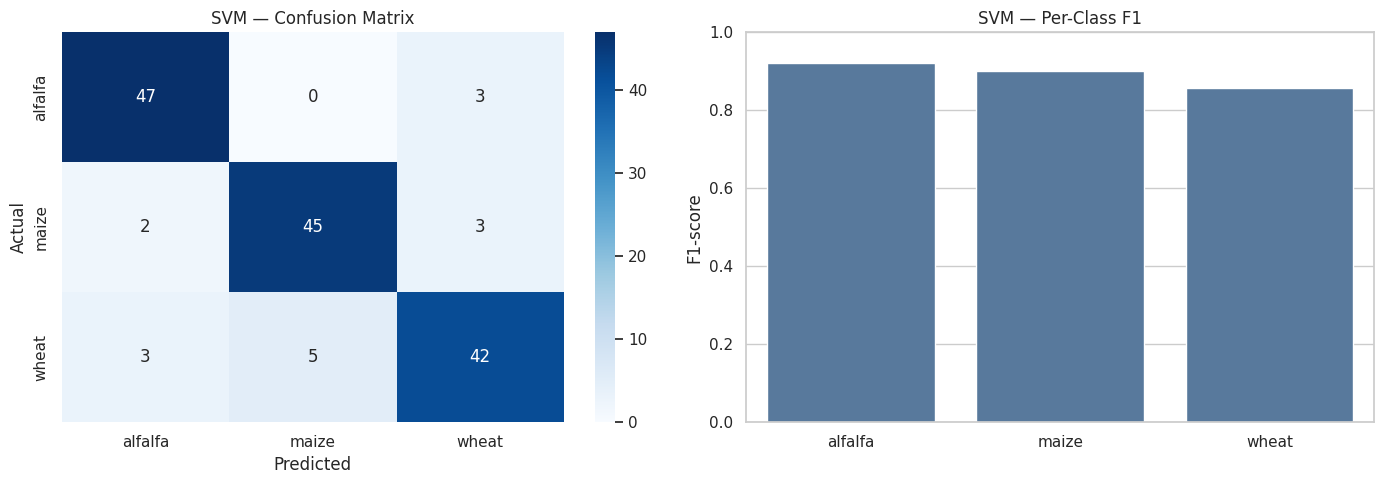

Total misclassified samples: 16


,B1,B2,B3,B4,B5,B6,B7,B8,B8A,B9,B11,B12,NDVI,Actual,Predicted
15,653.500597,657.778723,967.053118,1257.074903,1715.223665,2163.790510,2361.802447,2464.087735,2621.990600,2663.960310,3442.670397,2923.274097,0.325353,maize,wheat
18,990.004511,990.415039,1221.273572,1533.801926,1862.041989,2309.784561,2499.239757,2678.512414,2740.559320,2816.111654,3583.157306,2979.797755,0.283896,maize,wheat
22,310.720987,237.869498,305.908501,333.900973,461.606411,628.691539,720.500376,760.315207,814.791059,843.445014,789.564657,579.176338,0.386978,wheat,maize
31,954.739729,1255.043641,1479.220759,1759.925693,2198.176659,2812.584038,3072.723019,3473.289955,3399.173056,3796.920058,3311.442435,2375.793723,0.329241,wheat,alfalfa
35,498.127511,508.501044,709.808114,759.777068,1109.434320,1796.448930,2041.022045,2257.565093,2256.545395,1838.973976,2037.685038,1326.935233,0.499735,wheat,maize
37,782.403699,802.937023,1186.163241,1800.896947,2255.815326,2604.850558,2812.364210,3004.113329,3100.593952,3138.851439,4248.333969,3721.159718,0.251841,maize,wheat
47,945.055176,1068.179456,1510.357573,2190.928351,2603.301326,2975.913620,3237.503013,3534.881479,3633.340565,3573.512790,5173.693719,4604.545868,0.235449,wheat,maize
49,867.515124,1009.741348,1413.344014,1921.604717,2337.280825,2876.815432,3129.162266,3380.039477,3495.926045,3541.642912,4691.434376,3985.630095,0.277658,wheat,maize
55,6152.851237,6425.708276,6284.554435,6292.237325,6640.290636,6591.340683,6544.662436,6938.424603,6547.328353,9234.351781,6857.863350,6024.808733,0.049446,wheat,maize
76,663.962208,787.490795,1116.791540,1396.241824,1935.949002,2472.008079,2701.271965,2938.127165,3066.395518,3095.704148,3454.855045,2390.554455,0.356796,alfalfa,wheat


,Actual,Predicted,Count
0,alfalfa,wheat,3
1,maize,alfalfa,2
2,maize,wheat,3
3,wheat,alfalfa,3
4,wheat,maize,5


In [35]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

# Retrieve predictions from previous experiment
y_pred = predictions["SVM"]
class_names = [str(c) for c in encoder.classes_]

# 1. Classification report
report = classification_report(
    y_val, y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
display(report_df.round(4))

# 2. Confusion matrix
cm = confusion_matrix(y_val, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm, annot=True, fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)
axes[0].set_title("SVM — Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# 3. Per-class F1
class_f1 = f1_score(
    y_val, y_pred,
    average=None,
    labels=np.arange(len(class_names))
)

sns.barplot(
    x=class_names,
    y=class_f1,
    color="#4C78A8",
    ax=axes[1]
)

axes[1].set_title("SVM — Per-Class F1")
axes[1].set_ylabel("F1-score")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

# 4. Misclassified samples
errors = X_val.copy()
errors["Actual"] = encoder.inverse_transform(y_val)
errors["Predicted"] = encoder.inverse_transform(y_pred)

errors = errors[errors["Actual"] != errors["Predicted"]]

print(f"Total misclassified samples: {len(errors)}")
display(errors.head(20))

# 5. Error distribution
error_counts = (
    errors.groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
)

display(error_counts)

# Save results
report_df.to_csv(
    "/kaggle/working/svm_classification_report.csv"
)

errors.to_csv(
    "/kaggle/working/svm_misclassified_samples.csv",
    index=False
)



### Error Analysis — Results & Conclusions

- **Macro-F1:** 0.8929 (89.29%).
- **Accuracy:** 89.33%.
- **Correct predictions:** 134/150.
- **Misclassified samples:** 16/150 (10.67%).

**Per-Class F1:**
- Alfalfa: 0.9216 — Best classified crop.
- Maize: 0.9000 — Good performance.
- Wheat: 0.8571 — Most challenging crop.

**Main Challenges:**
- Wheat is frequently confused with Maize (5 samples).
- Alfalfa and Wheat are confused in 6 cases.
- Wheat has the lowest recall (84%).

**Conclusion:**
- Wheat classification is the main weakness of our SVM.
- Future experiments should focus on improving Wheat recognition without reducing performance on other classes.
- Next: Begin Quantum Machine Learning experiments using Qiskit.



## 8. Quantum Machine Learning — First VQC Model

Train a 4-qubit Variational Quantum Classifier (VQC) using Qiskit, PCA (4), ZZFeatureMap, and COBYLA. Evaluate Macro-F1, accuracy, and training time as our first quantum benchmark.


In [38]:
!pip install -q qiskit qiskit-machine-learning qiskit-aer

========== QUANTUM VQC RESULTS ==========
Qubits: 4
Macro-F1: 0.2953
Accuracy: 0.3733
Training Time (s): 124.44
Inference Time (s): 0.33


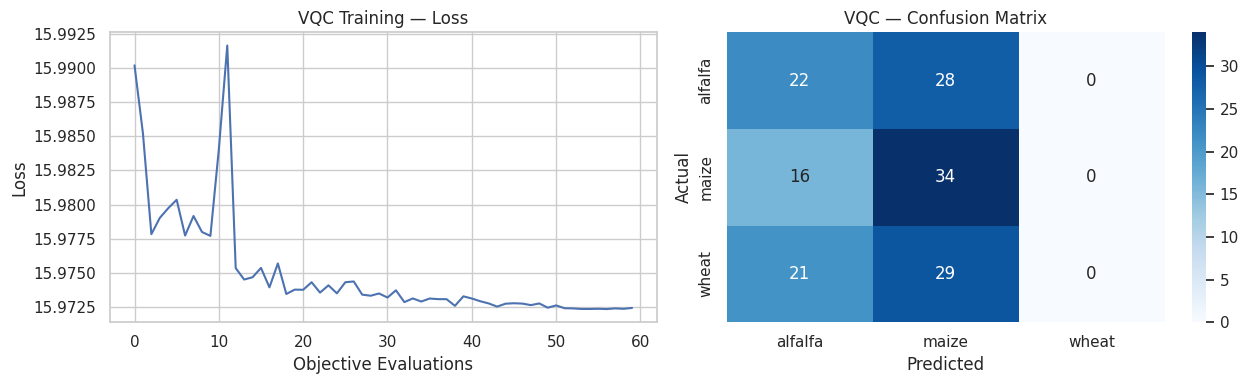

In [39]:

import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit_machine_learning.algorithms.classifiers import VQC
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_aer.primitives import SamplerV2

# Reproducibility
SEED = 0
np.random.seed(SEED)

# 1. Data preparation
X_train = train[features].replace([np.inf, -np.inf], np.nan)
X_val = val[features].replace([np.inf, -np.inf], np.nan)

encoder = LabelEncoder()
y_train = encoder.fit_transform(train[target])
y_val = encoder.transform(val[target])

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
pca = PCA(n_components=4)
angle_scaler = MinMaxScaler(feature_range=(0, np.pi))

X_train_q = angle_scaler.fit_transform(
    pca.fit_transform(
        scaler.fit_transform(
            imputer.fit_transform(X_train)
        )
    )
)

X_val_q = angle_scaler.transform(
    pca.transform(
        scaler.transform(
            imputer.transform(X_val)
        )
    )
)

# 2. Quantum circuit (4 qubits)
feature_map = zz_feature_map(
    feature_dimension=4,
    reps=1
)

ansatz = real_amplitudes(
    num_qubits=4,
    reps=1,
    entanglement="linear"
)

sampler = SamplerV2(
    default_shots=1024,
    seed=SEED
)

loss_history = []

def callback(weights, objective):
    loss_history.append(objective)

# 3. VQC
vqc = VQC(
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=COBYLA(maxiter=60),
    sampler=sampler,
    callback=callback
)

# 4. Training
start = time.perf_counter()
vqc.fit(X_train_q, y_train)
training_time = time.perf_counter() - start

# 5. Validation
start = time.perf_counter()
y_pred = np.asarray(vqc.predict(X_val_q)).ravel().astype(int)
inference_time = time.perf_counter() - start

macro_f1 = f1_score(y_val, y_pred, average="macro")
accuracy = accuracy_score(y_val, y_pred)

print("========== QUANTUM VQC RESULTS ==========")
print("Qubits: 4")
print("Macro-F1:", round(macro_f1, 4))
print("Accuracy:", round(accuracy, 4))
print("Training Time (s):", round(training_time, 2))
print("Inference Time (s):", round(inference_time, 2))

# 6. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(loss_history)
axes[0].set_title("VQC Training — Loss")
axes[0].set_xlabel("Objective Evaluations")
axes[0].set_ylabel("Loss")

cm = confusion_matrix(
    y_val, y_pred,
    labels=np.arange(len(encoder.classes_))
)

import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_,
    ax=axes[1]
)

axes[1].set_title("VQC — Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()



### Initial VQC — Results & Limitations

- **Macro-F1:** 0.2953
- **Accuracy:** 37.33%
- **Training time:** 124.44 seconds
- **Major issue:** The model never predicts the Wheat class.
- **Training loss:** Almost constant, indicating ineffective optimization.

**Conclusion:**
The initial VQC performs significantly worse than classical models. We must investigate output encoding, circuit architecture, optimization, and feature scaling before further training.



## 8.1 VQC — Fix Multiclass Output Encoding

Correct the quantum measurement mapping to explicitly support three crop classes. Retrain the VQC and evaluate Macro-F1, accuracy, and class predictions.



========== FIXED VQC RESULTS ==========
Macro-F1: 0.4705
Accuracy: 0.46
Training time: 198.41 s

Predicted classes:
(array([0, 1, 2]), array([65, 32, 53]))


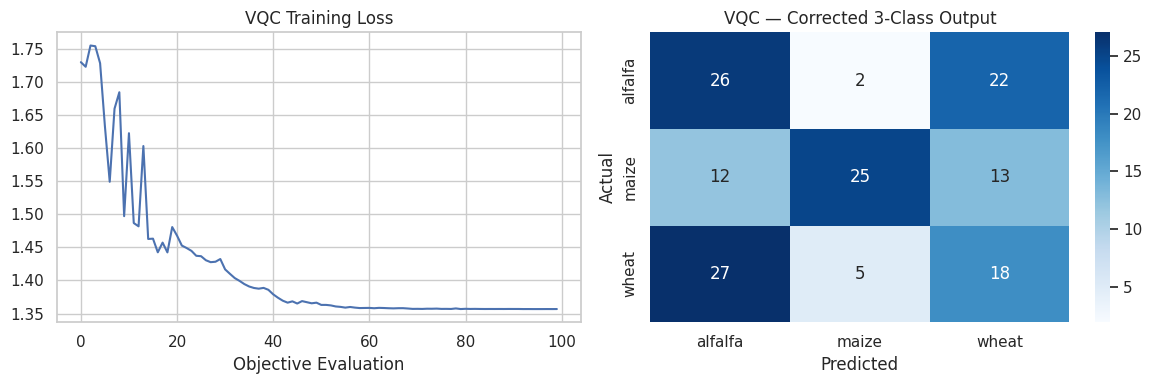

In [40]:

import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
import inspect

from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit_machine_learning.algorithms.classifiers import VQC
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_aer.primitives import SamplerV2
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

SEED = 0
np.random.seed(SEED)

# Map 16 quantum outcomes into 3 crop classes
def interpret(bitstring):
    return int(bitstring) % 3

feature_map = zz_feature_map(
    feature_dimension=4,
    reps=1
)

ansatz = real_amplitudes(
    num_qubits=4,
    reps=1,
    entanglement="linear"
)

sampler = SamplerV2(
    default_shots=1024,
    seed=SEED
)

loss_history = []

def callback(weights, loss):
    loss_history.append(loss)

# Check multiclass support before training
if not {
    "interpret", "output_shape"
}.issubset(inspect.signature(VQC).parameters):
    raise RuntimeError(
        "Your Qiskit Machine Learning version does not "
        "support explicit multiclass VQC outputs."
    )

vqc_fixed = VQC(
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=COBYLA(maxiter=100),
    sampler=sampler,
    interpret=interpret,
    output_shape=3,
    callback=callback
)

start = time.perf_counter()
vqc_fixed.fit(X_train_q, y_train)
training_time = time.perf_counter() - start

y_pred = np.asarray(
    vqc_fixed.predict(X_val_q)
).ravel().astype(int)

print("========== FIXED VQC RESULTS ==========")
print("Macro-F1:", round(
    f1_score(y_val, y_pred, average="macro"), 4
))
print("Accuracy:", round(
    accuracy_score(y_val, y_pred), 4
))
print("Training time:", round(training_time, 2), "s")

print("\nPredicted classes:")
print(np.unique(y_pred, return_counts=True))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(loss_history)
axes[0].set_title("VQC Training Loss")
axes[0].set_xlabel("Objective Evaluation")

sns.heatmap(
    confusion_matrix(y_val, y_pred, labels=[0, 1, 2]),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_,
    ax=axes[1]
)

axes[1].set_title("VQC — Corrected 3-Class Output")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()



### VQC Multiclass Correction — Results

- **Initial VQC Macro-F1:** 0.2953
- **Corrected VQC Macro-F1:** 0.4705
- **Accuracy:** 46%
- **Training time:** 198.41 seconds
- **Predicted classes:** All three classes are now represented.
- **Training loss:** Decreased from approximately 1.75 to 1.36.

**Conclusion:**
- Explicit multiclass encoding improved Macro-F1 by 17.52 percentage points.
- The VQC is now learning, but performance remains far below the classical SVM (0.8929).
- Wheat remains the most difficult class (18/50 correctly classified).
- Next: Improve quantum feature encoding and circuit architecture.



## 8.2 Reproducing the Official Quantum QNN

Reproduce the official 4-qubit QNN using RY encoding, PCA (4), 8 trainable parameters, and COBYLA (100 evaluations).

**Goal:** Verify the official quantum baseline (Macro-F1 ≈ 0.8557) before testing improvements.


===== OFFICIAL QNN REPRODUCTION =====
Macro-F1: 0.8473
Accuracy: 0.8467
Training time: 181.31 s
Resources: {'qubits': 4, 'trainable': 8, 'frozen_quantum': 0, 'depth': 6, 'two_qubit_gates': 3, 'objective_evaluations': 100, 'readout_group_sizes': [6, 5, 5], 'encoding': 'ry', 'compilation': 'logical decomposed H/P/RY/CX; no backend routing'}


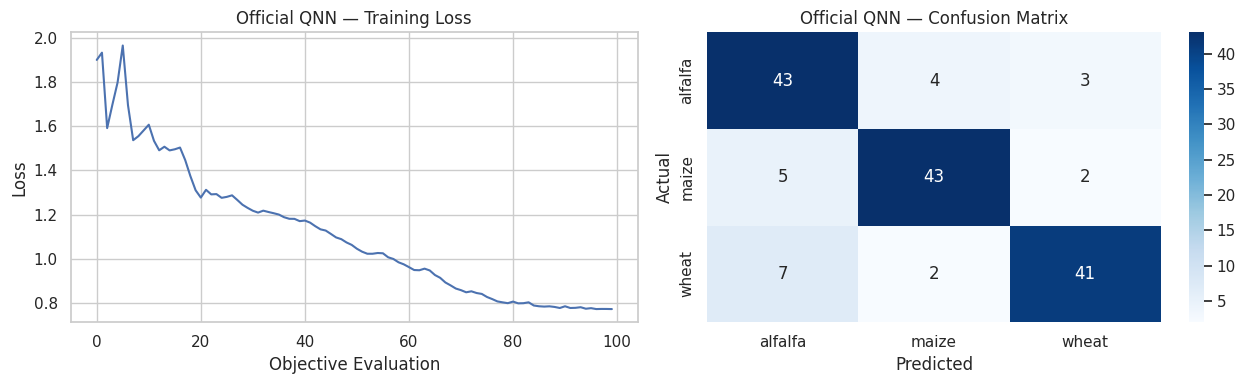

In [41]:

import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    f1_score, accuracy_score, confusion_matrix
)

# Official repository
ROOT = Path(
    "/kaggle/working/QiskitFallFest_EMSI_QuantumAfrica"
)
sys.path.insert(0, str(ROOT))

from challenge.data import load_data
from challenge.models import QuantumClassifier

# Load official data and verify integrity
tables, view, manifest, _ = load_data()

official_features = manifest["features"]
labels = ["alfalfa", "maize", "wheat"]

# Exact official preprocessing
prep = make_pipeline(
    StandardScaler(),
    PCA(n_components=4, svd_solver="full"),
    StandardScaler()
)

X_train = prep.fit_transform(
    tables["train"][official_features].to_numpy()
)

X_val = prep.transform(
    tables["validation"][official_features].to_numpy()
)

y_train = tables["train"]["target"].to_numpy()
y_val = tables["validation"]["target"].to_numpy()

# Official QNN
qnn_official = QuantumClassifier(
    labels=labels,
    encoding="ry",
    max_evals=100
)

# Train using seed 0
start = time.perf_counter()

qnn_official.fit(X_train, y_train, seed=0)

training_time = time.perf_counter() - start

# Predict
y_pred = qnn_official.predict(X_val)

f1 = f1_score(y_val, y_pred, average="macro")
accuracy = accuracy_score(y_val, y_pred)

print("===== OFFICIAL QNN REPRODUCTION =====")
print("Macro-F1:", round(f1, 4))
print("Accuracy:", round(accuracy, 4))
print("Training time:", round(training_time, 2), "s")
print("Resources:", qnn_official.resources())

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

loss = [h["objective"] for h in qnn_official.history]

axes[0].plot(loss)
axes[0].set_title("Official QNN — Training Loss")
axes[0].set_xlabel("Objective Evaluation")
axes[0].set_ylabel("Loss")

cm = confusion_matrix(y_val, y_pred, labels=labels)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[1]
)

axes[1].set_title("Official QNN — Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()



## 8.3 Quantum Encoding Comparison — RY vs ZZ

Compare two quantum feature encodings (RY and ZZ) using the official 4-qubit QNN architecture.

- Same PCA (4), optimizer (COBYLA), seed (0), and 100 evaluations.
- Evaluate Macro-F1, accuracy, training time, and loss convergence.
- **Goal:** Identify the most effective quantum encoding.



Training QNN with RY encoding...

Training QNN with ZZ encoding...


,Encoding,Macro-F1,Accuracy,Training Time (s),Inference Time (s),Circuit Depth,Two-Qubit Gates
0,RY,0.8473,0.8467,183.2004,0.2976,6,3
1,ZZ,0.4298,0.4467,228.6956,0.3814,15,9


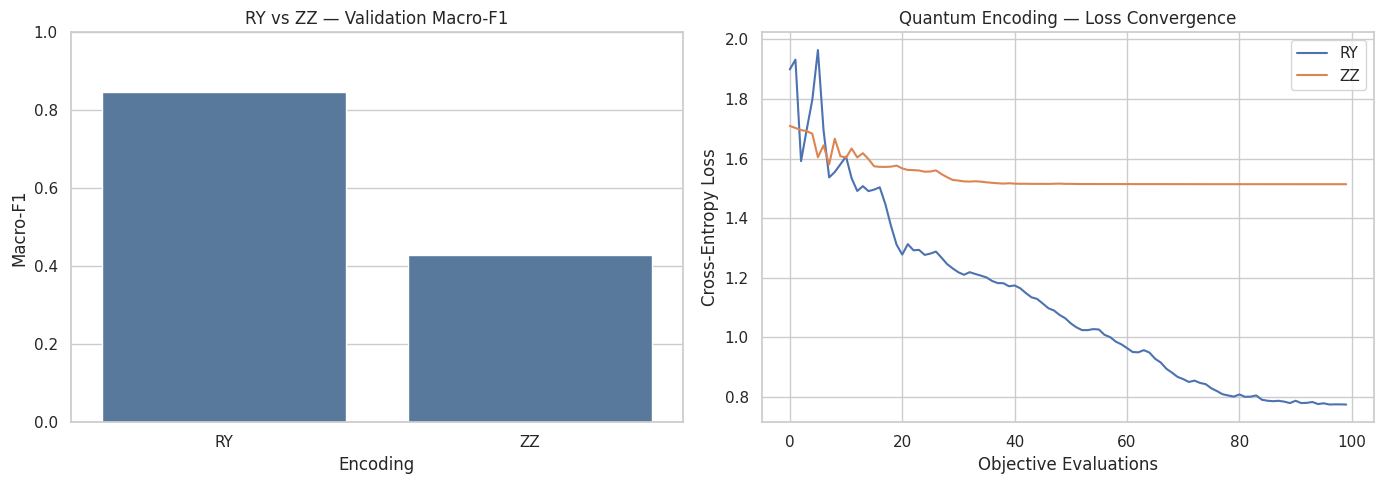


BEST ENCODING:
Encoding                      RY
Macro-F1                  0.8473
Accuracy                0.846667
Training Time (s)     183.200418
Inference Time (s)      0.297621
Circuit Depth                  6
Two-Qubit Gates                3


In [42]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    f1_score, accuracy_score, confusion_matrix
)

from challenge.data import load_data
from challenge.models import QuantumClassifier

# Official dataset
tables, view, manifest, _ = load_data()

features_q = manifest["features"]
labels = ["alfalfa", "maize", "wheat"]

# Same preprocessing for both encodings
prep = make_pipeline(
    StandardScaler(),
    PCA(n_components=4, svd_solver="full"),
    StandardScaler()
)

X_train_q = prep.fit_transform(
    tables["train"][features_q].to_numpy()
)

X_val_q = prep.transform(
    tables["validation"][features_q].to_numpy()
)

y_train_q = tables["train"]["target"].to_numpy()
y_val_q = tables["validation"]["target"].to_numpy()

results = []
histories = {}
quantum_models = {}

# Compare RY and ZZ
for encoding in ["ry", "zz"]:

    print(f"\nTraining QNN with {encoding.upper()} encoding...")

    model = QuantumClassifier(
        labels=labels,
        encoding=encoding,
        max_evals=100
    )

    start = time.perf_counter()

    model.fit(X_train_q, y_train_q, seed=0)

    training_time = time.perf_counter() - start

    start = time.perf_counter()
    y_pred = model.predict(X_val_q)
    inference_time = time.perf_counter() - start

    macro_f1 = f1_score(
        y_val_q, y_pred, average="macro"
    )

    accuracy = accuracy_score(y_val_q, y_pred)

    results.append({
        "Encoding": encoding.upper(),
        "Macro-F1": macro_f1,
        "Accuracy": accuracy,
        "Training Time (s)": training_time,
        "Inference Time (s)": inference_time,
        "Circuit Depth": model.resources()["depth"],
        "Two-Qubit Gates": model.resources()["two_qubit_gates"]
    })

    histories[encoding] = [
        h["objective"] for h in model.history
    ]

    quantum_models[encoding] = model

# Results table
encoding_results = pd.DataFrame(results).sort_values(
    "Macro-F1", ascending=False
)

display(encoding_results.round(4))

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=encoding_results,
    x="Encoding",
    y="Macro-F1",
    color="#4C78A8",
    ax=axes[0]
)

axes[0].set_ylim(0, 1)
axes[0].set_title("RY vs ZZ — Validation Macro-F1")

for encoding, history in histories.items():
    axes[1].plot(
        history,
        label=encoding.upper()
    )

axes[1].set_title("Quantum Encoding — Loss Convergence")
axes[1].set_xlabel("Objective Evaluations")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

# Save results
encoding_results.to_csv(
    "/kaggle/working/quantum_encoding_results.csv",
    index=False
)

print("\nBEST ENCODING:")
print(encoding_results.iloc[0].to_string())



### Quantum Encoding — RY vs ZZ

- **RY:** Macro-F1 = 0.8473, Accuracy = 84.67%.
- **ZZ:** Macro-F1 = 0.4298, Accuracy = 44.67%.
- **RY:** Faster training (183 s vs 229 s).
- **RY:** Simpler circuit (depth 6 vs 15).
- **ZZ:** Higher complexity with 9 two-qubit gates vs 3 for RY.
- **Loss:** RY converges to 0.78, while ZZ stagnates around 1.52.

**Conclusion:**
- RY significantly outperforms ZZ in this experiment.
- Increasing circuit complexity does not guarantee better performance.
- **Selected encoding: RY.**
- Next: Optimize the QNN architecture and training parameters.



## 8.4 Quantum Feature Representation Optimization

Compare PCA (4), Mutual Information (4), and alternative feature scaling strategies using the official RY-based QNN.

**Goal:** Improve the quantum Macro-F1 beyond the baseline of 0.8473.



Training: PCA4 + StandardScaler

Training: PCA4 + MinMax [-pi, pi]

Training: PCA4 + MinMax [0, pi]

Training: Mutual Information (4)


,Strategy,Macro-F1,Accuracy,Training Time (s)
0,PCA4 + StandardScaler,0.8473,0.8467,181.8817
1,"PCA4 + MinMax [-pi, pi]",0.8327,0.8333,182.8072
3,Mutual Information (4),0.7293,0.7400,182.0411
2,"PCA4 + MinMax [0, pi]",0.1910,0.3400,182.2965


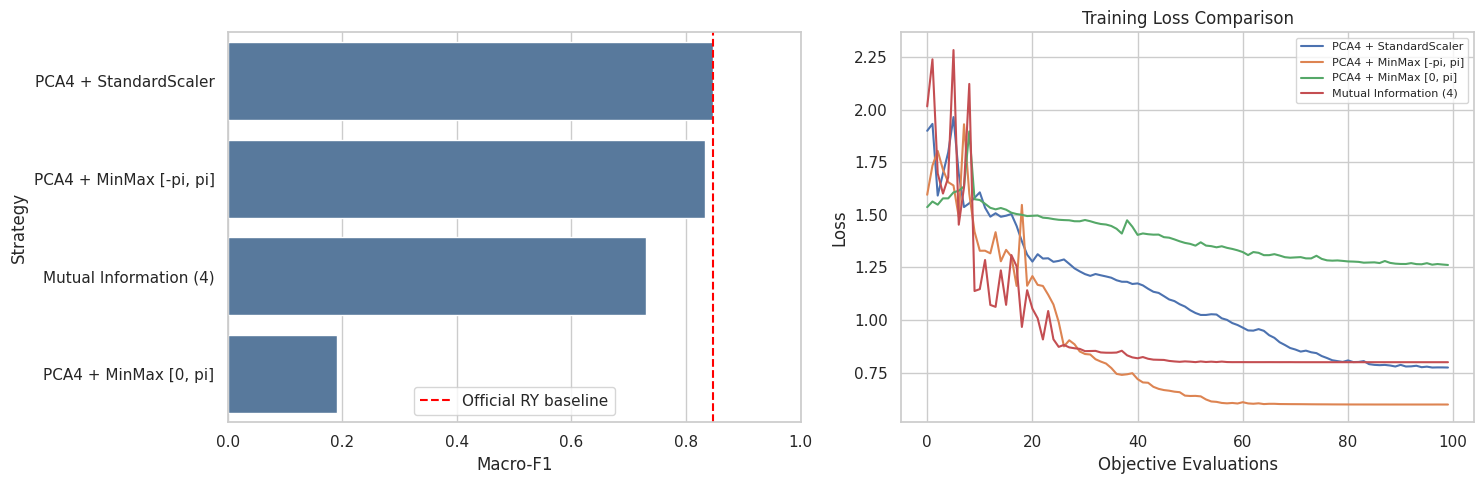


BEST STRATEGY:
Strategy             PCA4 + StandardScaler
Macro-F1                            0.8473
Accuracy                          0.846667
Training Time (s)               181.881689


In [43]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.metrics import f1_score, accuracy_score
from functools import partial

from challenge.data import load_data
from challenge.models import QuantumClassifier

tables, _, manifest, _ = load_data()

X_train = tables["train"][manifest["features"]].to_numpy()
X_val = tables["validation"][manifest["features"]].to_numpy()

y_train = tables["train"]["target"].to_numpy()
y_val = tables["validation"]["target"].to_numpy()

labels = ["alfalfa", "maize", "wheat"]

# Feature representation strategies
strategies = {
    "PCA4 + StandardScaler": make_pipeline(
        StandardScaler(),
        PCA(n_components=4),
        StandardScaler()
    ),

    "PCA4 + MinMax [-pi, pi]": make_pipeline(
        StandardScaler(),
        PCA(n_components=4),
        MinMaxScaler(feature_range=(-np.pi, np.pi))
    ),

    "PCA4 + MinMax [0, pi]": make_pipeline(
        StandardScaler(),
        PCA(n_components=4),
        MinMaxScaler(feature_range=(0, np.pi))
    ),

    "Mutual Information (4)": make_pipeline(
        StandardScaler(),
        SelectKBest(
            partial(mutual_info_classif, random_state=42),
            k=4
        ),
        StandardScaler()
    )
}

results = []
histories = {}

for name, prep in strategies.items():

    print(f"\nTraining: {name}")

    Xtr = prep.fit_transform(X_train, y_train)
    Xva = prep.transform(X_val)

    model = QuantumClassifier(
        labels=labels,
        encoding="ry",
        max_evals=100
    )

    start = time.perf_counter()
    model.fit(Xtr, y_train, seed=0)
    train_time = time.perf_counter() - start

    pred = model.predict(Xva)

    f1 = f1_score(y_val, pred, average="macro")

    results.append({
        "Strategy": name,
        "Macro-F1": f1,
        "Accuracy": accuracy_score(y_val, pred),
        "Training Time (s)": train_time
    })

    histories[name] = [
        h["objective"] for h in model.history
    ]

results_df = pd.DataFrame(results).sort_values(
    "Macro-F1", ascending=False
)

display(results_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=results_df,
    x="Macro-F1",
    y="Strategy",
    color="#4C78A8",
    ax=axes[0]
)

axes[0].axvline(
    0.8473,
    color="red",
    linestyle="--",
    label="Official RY baseline"
)
axes[0].set_xlim(0, 1)
axes[0].legend()

for name, history in histories.items():
    axes[1].plot(history, label=name)

axes[1].set_title("Training Loss Comparison")
axes[1].set_xlabel("Objective Evaluations")
axes[1].set_ylabel("Loss")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

results_df.to_csv(
    "/kaggle/working/qnn_feature_comparison.csv",
    index=False
)

print("\nBEST STRATEGY:")
print(results_df.iloc[0].to_string())



### Quantum Feature Representation — Results

- **PCA (4) + StandardScaler:** Best Macro-F1 = 0.8473.
- **PCA (4) + MinMax [-π, π]:** Competitive performance ≈ 0.83.
- **Mutual Information (4):** Lower performance ≈ 0.73.
- **PCA (4) + MinMax [0, π]:** Poor performance ≈ 0.19.

**Conclusion:**
- StandardScaler + PCA (4) remains the best preprocessing strategy.
- Quantum encoding is highly sensitive to feature scaling.
- Lower training loss does not always imply better validation performance.
- None of the tested strategies improved the official RY baseline.

**Next:** Optimize the QNN architecture, circuit depth, and trainable parameters.



## 8.5 QNN Optimization — Training Budget

Test whether increasing COBYLA evaluations from 100 to 200 and 300 improves QNN convergence and Macro-F1. Use an internal stratified split to compare fairly without repeatedly optimizing on official validation.



Training QNN — 100 evaluations

Training QNN — 200 evaluations

Training QNN — 300 evaluations


,Evaluations,Macro-F1,Accuracy,Train Time (s),Final Loss
0,100,0.8027,0.8142,145.3888,0.7796
1,200,0.7991,0.8087,294.8044,0.7703
2,300,0.7991,0.8087,455.9871,0.7687


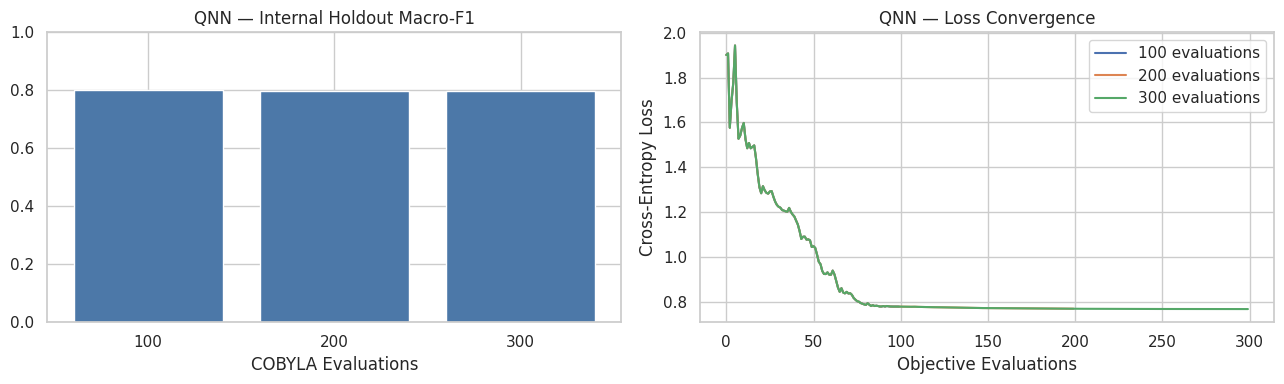


BEST TRAINING BUDGET:
Evaluations       100.000000
Macro-F1            0.802720
Accuracy            0.814208
Train Time (s)    145.388766
Final Loss          0.779587


In [44]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, accuracy_score
from challenge.data import load_data
from challenge.models import QuantumClassifier

# Load official training data
tables, _, manifest, _ = load_data()

X = tables["train"][manifest["features"]].to_numpy()
y = tables["train"]["target"].to_numpy()
labels = ["alfalfa", "maize", "wheat"]

# Internal split — official validation remains untouched
X_tr, X_hold, y_tr, y_hold = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Official preprocessing
prep = make_pipeline(
    StandardScaler(),
    PCA(n_components=4, svd_solver="full"),
    StandardScaler()
)

X_tr = prep.fit_transform(X_tr)
X_hold = prep.transform(X_hold)

results = []
histories = {}

for max_evals in [100, 200, 300]:

    print(f"\nTraining QNN — {max_evals} evaluations")

    model = QuantumClassifier(
        labels=labels,
        encoding="ry",
        max_evals=max_evals
    )

    start = time.perf_counter()
    model.fit(X_tr, y_tr, seed=0)
    train_time = time.perf_counter() - start

    pred = model.predict(X_hold)

    results.append({
        "Evaluations": max_evals,
        "Macro-F1": f1_score(
            y_hold, pred, average="macro"
        ),
        "Accuracy": accuracy_score(y_hold, pred),
        "Train Time (s)": train_time,
        "Final Loss": model.history[-1]["objective"]
    })

    histories[max_evals] = [
        h["objective"] for h in model.history
    ]

results_qnn = pd.DataFrame(results)
display(results_qnn.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(
    results_qnn["Evaluations"].astype(str),
    results_qnn["Macro-F1"],
    color="#4C78A8"
)
axes[0].set_ylim(0, 1)
axes[0].set_title("QNN — Internal Holdout Macro-F1")
axes[0].set_xlabel("COBYLA Evaluations")

for n, history in histories.items():
    axes[1].plot(history, label=f"{n} evaluations")

axes[1].set_title("QNN — Loss Convergence")
axes[1].set_xlabel("Objective Evaluations")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

results_qnn.to_csv(
    "/kaggle/working/qnn_training_budget.csv",
    index=False
)

print("\nBEST TRAINING BUDGET:")
print(
    results_qnn.loc[
        results_qnn["Macro-F1"].idxmax()
    ].to_string()
)



### QNN Training Budget — Results

- Best configuration: 100 objective evaluations.
- Best internal holdout Macro-F1: 0.8027.
- Increasing to 200 or 300 evaluations did not improve performance.
- Training loss converged within approximately 100 evaluations.
- Longer training increased computational cost without measurable benefit.

**Conclusion:** Keep 100 evaluations and focus on improving the quantum architecture, feature encoding, and optimization strategy.




## 8.6 QNN Architecture Optimization

Experiment with different circuit depths and entanglement patterns (Linear, Circular, Full) while keeping RY encoding, 4 qubits, and 100 COBYLA evaluations.

**Goal:** Improve Macro-F1 beyond the official QNN baseline by optimizing the quantum circuit architecture.



Training: Baseline Linear

Training: Circular

Training: Full

Training: Deep Linear

Training: Deep Circular


,Architecture,Reps,Entanglement,Parameters,Depth,Two-Qubit Gates,Macro-F1,Accuracy,Training Time (s)
0,Deep Linear,2,linear,12,9,6,0.8845,0.8798,168.5961
1,Full,1,full,8,8,6,0.8681,0.8689,157.8178
2,Deep Circular,2,circular,12,12,8,0.8595,0.8579,175.6451
3,Baseline Linear,1,linear,8,6,3,0.8027,0.8142,153.6147
4,Circular,1,circular,8,7,4,0.7843,0.7923,156.3801


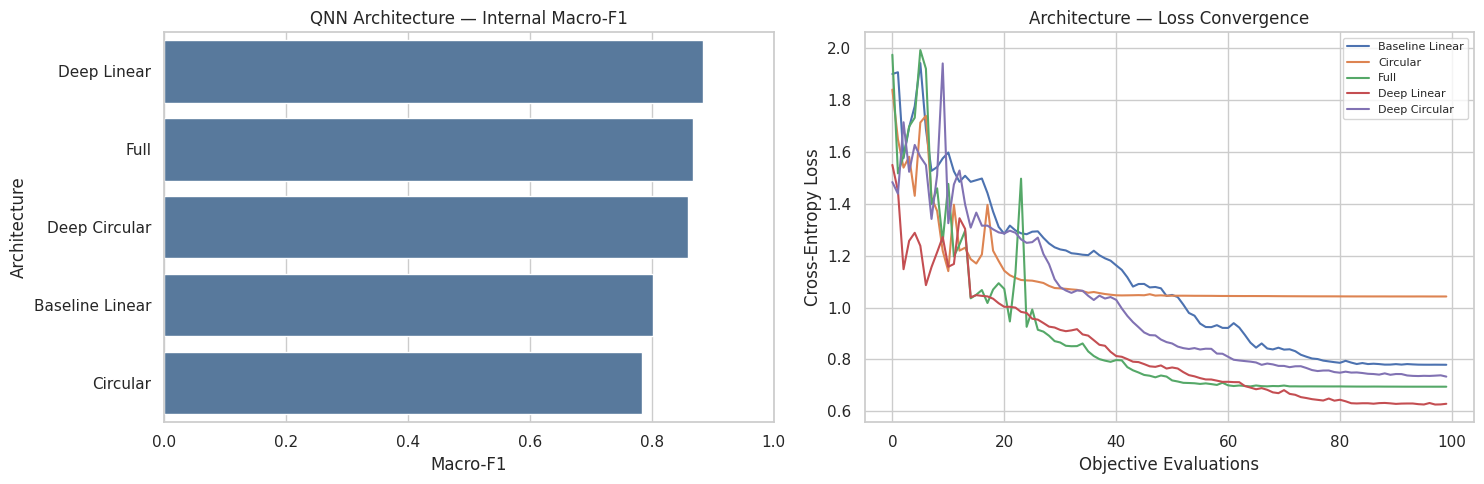


BEST ARCHITECTURE:
Architecture         Deep Linear
Reps                           2
Entanglement              linear
Parameters                    12
Depth                          9
Two-Qubit Gates                6
Macro-F1                0.884486
Accuracy                0.879781
Training Time (s)      168.59606


In [45]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import real_amplitudes
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.primitives import QMLSampler

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, accuracy_score

from challenge.data import load_data
from challenge.models import QuantumClassifier

# Official dataset — internal holdout
tables, _, manifest, _ = load_data()

X = tables["train"][manifest["features"]].to_numpy()
y = tables["train"]["target"].to_numpy()

X_tr, X_hold, y_tr, y_hold = train_test_split(
    X, y, test_size=0.20,
    stratify=y, random_state=42
)

prep = make_pipeline(
    StandardScaler(),
    PCA(n_components=4, svd_solver="full"),
    StandardScaler()
)

X_tr = prep.fit_transform(X_tr)
X_hold = prep.transform(X_hold)

labels = ["alfalfa", "maize", "wheat"]

# Custom architecture with official training methodology
class CustomQNN(QuantumClassifier):

    def __init__(self, reps=1, entanglement="linear"):
        super().__init__(
            labels=labels,
            encoding="ry",
            max_evals=100
        )

        encoding = QuantumCircuit(4)
        x = ParameterVector("x", 4)

        for i in range(4):
            encoding.ry(x[i], i)

        ansatz = real_amplitudes(
            num_qubits=4,
            reps=reps,
            entanglement=entanglement,
            parameter_prefix="theta"
        )

        self.circuit = encoding.compose(ansatz)
        self.inputs = tuple(encoding.parameters)
        self.weights = tuple(ansatz.parameters)

        # Preserve official multiclass readout
        self.qnn = SamplerQNN(
            circuit=self.circuit,
            sampler=QMLSampler(shots=None),
            input_params=self.inputs,
            weight_params=self.weights,
            interpret=lambda outcome: int(
                self.outcomes[int(outcome)]
            ),
            output_shape=len(self.labels)
        )

# Circuit configurations
configs = [
    ("Baseline Linear", 1, "linear"),
    ("Circular", 1, "circular"),
    ("Full", 1, "full"),
    ("Deep Linear", 2, "linear"),
    ("Deep Circular", 2, "circular")
]

results = []
histories = {}

for name, reps, entanglement in configs:

    print(f"\nTraining: {name}")

    model = CustomQNN(
        reps=reps,
        entanglement=entanglement
    )

    start = time.perf_counter()
    model.fit(X_tr, y_tr, seed=0)
    training_time = time.perf_counter() - start

    pred = model.predict(X_hold)

    score = f1_score(
        y_hold, pred, average="macro"
    )

    results.append({
        "Architecture": name,
        "Reps": reps,
        "Entanglement": entanglement,
        "Parameters": len(model.weights),
        "Depth": model.circuit.depth(),
        "Two-Qubit Gates": sum(
            len(inst.qubits) == 2
            for inst in model.circuit.data
        ),
        "Macro-F1": score,
        "Accuracy": accuracy_score(y_hold, pred),
        "Training Time (s)": training_time
    })

    histories[name] = [
        h["objective"] for h in model.history
    ]

architecture_results = pd.DataFrame(results).sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)

display(architecture_results.round(4))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=architecture_results,
    x="Macro-F1",
    y="Architecture",
    color="#4C78A8",
    ax=axes[0]
)
axes[0].set_xlim(0, 1)
axes[0].set_title("QNN Architecture — Internal Macro-F1")

for name, history in histories.items():
    axes[1].plot(history, label=name)

axes[1].set_title("Architecture — Loss Convergence")
axes[1].set_xlabel("Objective Evaluations")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

architecture_results.to_csv(
    "/kaggle/working/qnn_architecture_results.csv",
    index=False
)

print("\nBEST ARCHITECTURE:")
print(architecture_results.iloc[0].to_string())



### QNN Architecture Optimization — Results

- **Best Architecture:** Deep Linear
- **Qubits:** 4
- **Trainable Parameters:** 12
- **Circuit Depth:** 9
- **Two-Qubit Gates:** 6
- **Macro-F1:** 0.8845 (internal holdout).
- **Accuracy:** 87.98%
- **Training Time:** 168.60 seconds.

**Conclusion:**
- Deep Linear is the most promising architecture tested.
- Increasing circuit depth improved classification performance.
- The improvement must be confirmed across multiple seeds and on the official validation set.



## 8.7 QNN Improvement — Quantum Data Re-Uploading

Improve the Deep Linear QNN by re-encoding input features inside the quantum circuit.

Compare:
- Deep Linear (baseline)
- Deep Linear + Data Re-Uploading

Keep 4 qubits, 12 trainable parameters, 100 COBYLA evaluations, and the same internal holdout.

**Goal:** Improve Macro-F1 beyond 0.8845.



Training: Deep Linear

Training: Deep Linear + Reuploading


,Architecture,Macro-F1,Accuracy,Parameters,Depth,Two-Qubit Gates,Training Time (s)
0,Deep Linear,0.8845,0.8798,12,9,6,167.9452
1,Deep Linear + Reuploading,0.7979,0.8087,12,10,6,178.4919


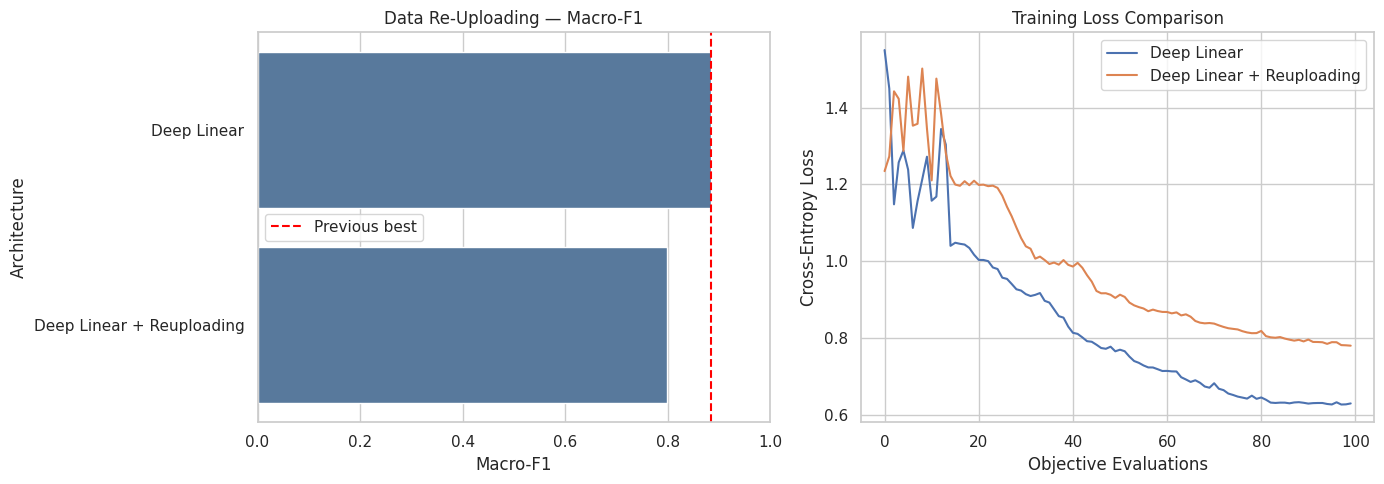


BEST CONFIGURATION:
Architecture         Deep Linear
Macro-F1                0.884486
Accuracy                0.879781
Parameters                    12
Depth                          9
Two-Qubit Gates                6
Training Time (s)     167.945188


In [46]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.primitives import QMLSampler

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, accuracy_score

from challenge.data import load_data
from challenge.models import QuantumClassifier

# --------------------------------------------------
# 1. DATA PREPARATION
# --------------------------------------------------

tables, _, manifest, _ = load_data()

X = tables["train"][manifest["features"]].to_numpy()
y = tables["train"]["target"].to_numpy()

labels = ["alfalfa", "maize", "wheat"]

X_tr, X_hold, y_tr, y_hold = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

prep = make_pipeline(
    StandardScaler(),
    PCA(n_components=4, svd_solver="full"),
    StandardScaler()
)

X_tr = prep.fit_transform(X_tr)
X_hold = prep.transform(X_hold)

# --------------------------------------------------
# 2. CUSTOM QNN WITH DATA RE-UPLOADING
# --------------------------------------------------

class ReuploadingQNN(QuantumClassifier):

    def __init__(self, reupload=False):

        super().__init__(
            labels=labels,
            encoding="ry",
            max_evals=100
        )

        x = ParameterVector("x", 4)
        theta = ParameterVector("theta", 12)

        circuit = QuantumCircuit(4)

        # Initial data encoding
        for i in range(4):
            circuit.ry(x[i], i)

        # First trainable layer
        for i in range(4):
            circuit.ry(theta[i], i)

        for i in range(3):
            circuit.cx(i, i + 1)

        # Second trainable layer
        for i in range(4):
            circuit.ry(theta[4 + i], i)

        # Re-upload the input data
        if reupload:
            for i in range(4):
                circuit.ry(x[i], i)

        for i in range(3):
            circuit.cx(i, i + 1)

        # Final trainable layer
        for i in range(4):
            circuit.ry(theta[8 + i], i)

        self.circuit = circuit
        self.inputs = tuple(x)
        self.weights = tuple(theta)

        self.qnn = SamplerQNN(
            circuit=self.circuit,
            sampler=QMLSampler(shots=None),
            input_params=self.inputs,
            weight_params=self.weights,
            interpret=lambda outcome: int(
                self.outcomes[int(outcome)]
            ),
            output_shape=3
        )

# --------------------------------------------------
# 3. EXPERIMENTS
# --------------------------------------------------

configs = {
    "Deep Linear": False,
    "Deep Linear + Reuploading": True
}

results = []
histories = {}

for name, reupload in configs.items():

    print(f"\nTraining: {name}")

    model = ReuploadingQNN(reupload=reupload)

    start = time.perf_counter()
    model.fit(X_tr, y_tr, seed=0)
    training_time = time.perf_counter() - start

    pred = model.predict(X_hold)

    score = f1_score(
        y_hold, pred, average="macro"
    )

    results.append({
        "Architecture": name,
        "Macro-F1": score,
        "Accuracy": accuracy_score(y_hold, pred),
        "Parameters": len(model.weights),
        "Depth": model.circuit.depth(),
        "Two-Qubit Gates": sum(
            len(inst.qubits) == 2
            for inst in model.circuit.data
        ),
        "Training Time (s)": training_time
    })

    histories[name] = [
        h["objective"] for h in model.history
    ]

# --------------------------------------------------
# 4. RESULTS
# --------------------------------------------------

reupload_results = pd.DataFrame(results).sort_values(
    "Macro-F1", ascending=False
)

display(reupload_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=reupload_results,
    x="Macro-F1",
    y="Architecture",
    color="#4C78A8",
    ax=axes[0]
)

axes[0].axvline(
    0.8845,
    color="red",
    linestyle="--",
    label="Previous best"
)
axes[0].set_xlim(0, 1)
axes[0].legend()
axes[0].set_title("Data Re-Uploading — Macro-F1")

for name, history in histories.items():
    axes[1].plot(history, label=name)

axes[1].set_title("Training Loss Comparison")
axes[1].set_xlabel("Objective Evaluations")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

reupload_results.to_csv(
    "/kaggle/working/qnn_reupload_results.csv",
    index=False
)

print("\nBEST CONFIGURATION:")
print(reupload_results.iloc[0].to_string())



### QNN Data Re-Uploading — Results

- **Deep Linear:** Macro-F1 = 0.8845.
- **Deep Linear + Re-Uploading:** Macro-F1 = 0.7979.
- **Performance change:** −8.66 percentage points.
- **Training time:** 167.95 s vs 178.49 s.
- **Training loss:** Deep Linear achieves better convergence.

**Conclusion:**
- Data Re-Uploading did not improve performance in this configuration.
- Adding more data-encoding operations increased circuit complexity without improving classification.
- **Best architecture remains Deep Linear (4 qubits, 12 parameters, depth 9).**
- Further experiments should investigate alternative trainable gates, optimizers, and circuit designs.



## 8.8 QNN Optimization — Trainable Quantum Gates

Compare RY, RX, RZ, and mixed rotation gates (RX-RY, RY-RZ, RX-RY-RZ) using the Deep Linear QNN architecture.

Keep 4 qubits, 12 trainable parameters, 100 COBYLA evaluations, and the same internal holdout.

**Goal:** Improve Macro-F1 beyond 0.8845.



Training: RY-RY-RY (Baseline)

Training: RX-RX-RX

Training: RZ-RZ-RZ

Training: RX-RY-RX

Training: RY-RZ-RY

Training: RX-RY-RZ

Training: RY-RX-RZ


,Architecture,Macro-F1,Accuracy,Parameters,Depth,Two-Qubit Gates,Training Time (s)
0,RY-RY-RY (Baseline),0.8845,0.8798,12,9,6,167.6037
1,RY-RZ-RY,0.8417,0.8415,12,9,6,167.8199
2,RY-RX-RZ,0.7972,0.8033,12,9,6,166.8665
3,RX-RY-RX,0.7479,0.7541,12,9,6,168.5951
4,RX-RX-RX,0.6238,0.6230,12,9,6,168.0798
5,RX-RY-RZ,0.4990,0.5519,12,9,6,167.9831
6,RZ-RZ-RZ,0.3127,0.3443,12,9,6,164.9969


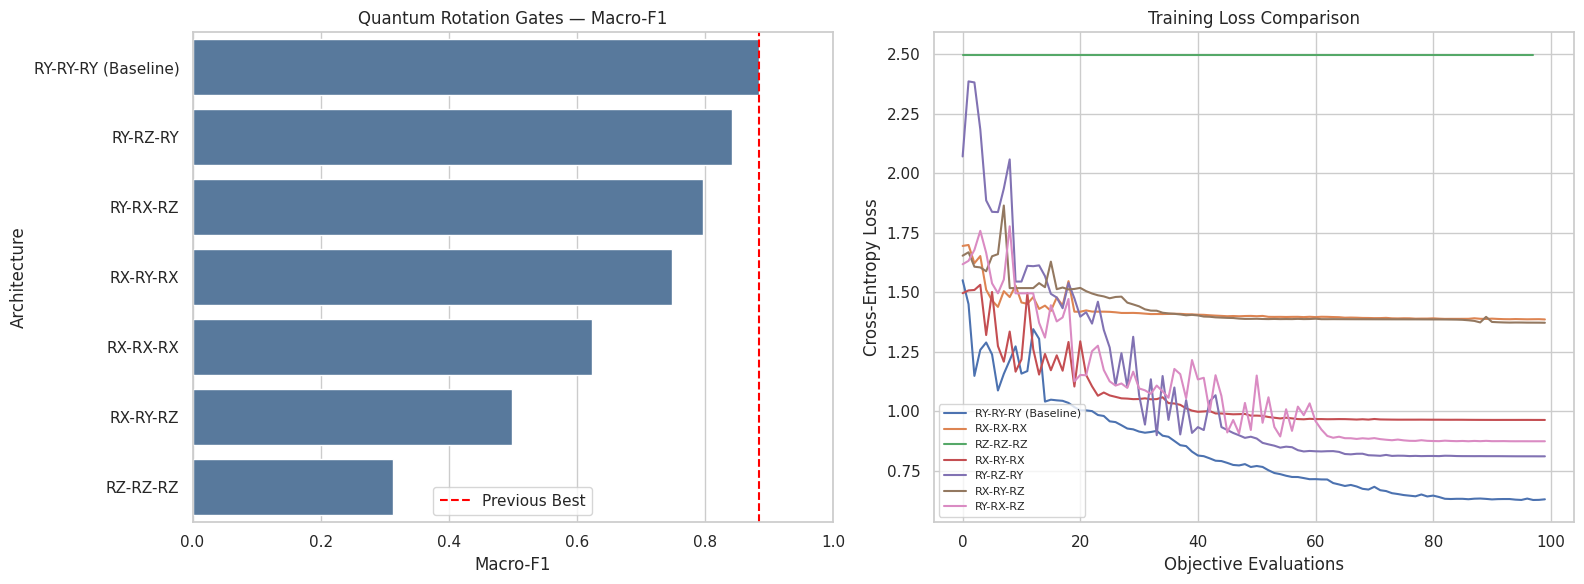


BEST QUANTUM ARCHITECTURE:
Architecture         RY-RY-RY (Baseline)
Macro-F1                        0.884486
Accuracy                        0.879781
Parameters                            12
Depth                                  9
Two-Qubit Gates                        6
Training Time (s)             167.603737


In [47]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.primitives import QMLSampler

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, accuracy_score

from challenge.data import load_data
from challenge.models import QuantumClassifier

# --------------------------------------------------
# 1. DATA — SAME INTERNAL HOLDOUT
# --------------------------------------------------

tables, _, manifest, _ = load_data()

X = tables["train"][manifest["features"]].to_numpy()
y = tables["train"]["target"].to_numpy()

labels = ["alfalfa", "maize", "wheat"]

X_tr, X_hold, y_tr, y_hold = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

prep = make_pipeline(
    StandardScaler(),
    PCA(n_components=4, svd_solver="full"),
    StandardScaler()
)

X_tr = prep.fit_transform(X_tr)
X_hold = prep.transform(X_hold)

# --------------------------------------------------
# 2. CUSTOM QUANTUM CIRCUIT
# --------------------------------------------------

class RotationQNN(QuantumClassifier):

    def __init__(self, gates=("ry", "ry", "ry")):

        super().__init__(
            labels=labels,
            encoding="ry",
            max_evals=100
        )

        x = ParameterVector("x", 4)
        theta = ParameterVector("theta", 12)

        circuit = QuantumCircuit(4)

        # Data encoding: RY
        for i in range(4):
            circuit.ry(x[i], i)

        # Three trainable rotation layers
        for layer, gate in enumerate(gates):

            for i in range(4):
                angle = theta[layer * 4 + i]

                if gate == "rx":
                    circuit.rx(angle, i)
                elif gate == "ry":
                    circuit.ry(angle, i)
                elif gate == "rz":
                    circuit.rz(angle, i)

            # Linear entanglement between layers
            if layer < 2:
                for i in range(3):
                    circuit.cx(i, i + 1)

        self.circuit = circuit
        self.inputs = tuple(x)
        self.weights = tuple(theta)

        # Keep official multiclass readout
        self.qnn = SamplerQNN(
            circuit=self.circuit,
            sampler=QMLSampler(shots=None),
            input_params=self.inputs,
            weight_params=self.weights,
            interpret=lambda outcome: int(
                self.outcomes[int(outcome)]
            ),
            output_shape=3
        )

# --------------------------------------------------
# 3. ARCHITECTURES TO TEST
# --------------------------------------------------

configs = {
    "RY-RY-RY (Baseline)": ("ry", "ry", "ry"),
    "RX-RX-RX": ("rx", "rx", "rx"),
    "RZ-RZ-RZ": ("rz", "rz", "rz"),
    "RX-RY-RX": ("rx", "ry", "rx"),
    "RY-RZ-RY": ("ry", "rz", "ry"),
    "RX-RY-RZ": ("rx", "ry", "rz"),
    "RY-RX-RZ": ("ry", "rx", "rz")
}

results = []
histories = {}

# --------------------------------------------------
# 4. TRAINING AND EVALUATION
# --------------------------------------------------

for name, gates in configs.items():

    print(f"\nTraining: {name}")

    model = RotationQNN(gates=gates)

    start = time.perf_counter()

    model.fit(X_tr, y_tr, seed=0)

    training_time = time.perf_counter() - start

    pred = model.predict(X_hold)

    score = f1_score(
        y_hold, pred, average="macro"
    )

    results.append({
        "Architecture": name,
        "Macro-F1": score,
        "Accuracy": accuracy_score(y_hold, pred),
        "Parameters": len(model.weights),
        "Depth": model.circuit.depth(),
        "Two-Qubit Gates": sum(
            len(inst.qubits) == 2
            for inst in model.circuit.data
        ),
        "Training Time (s)": training_time
    })

    histories[name] = [
        h["objective"] for h in model.history
    ]

# --------------------------------------------------
# 5. RESULTS
# --------------------------------------------------

rotation_results = pd.DataFrame(results).sort_values(
    "Macro-F1", ascending=False
).reset_index(drop=True)

display(rotation_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=rotation_results,
    x="Macro-F1",
    y="Architecture",
    color="#4C78A8",
    ax=axes[0]
)

axes[0].axvline(
    0.8845,
    color="red",
    linestyle="--",
    label="Previous Best"
)

axes[0].set_xlim(0, 1)
axes[0].set_title("Quantum Rotation Gates — Macro-F1")
axes[0].legend()

for name, history in histories.items():
    axes[1].plot(history, label=name)

axes[1].set_title("Training Loss Comparison")
axes[1].set_xlabel("Objective Evaluations")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. SAVE RESULTS
# --------------------------------------------------

rotation_results.to_csv(
    "/kaggle/working/qnn_rotation_gates_results.csv",
    index=False
)

print("\nBEST QUANTUM ARCHITECTURE:")
print(rotation_results.iloc[0].to_string())



### Quantum Rotation Gates — Results

- **Best architecture:** RY–RY–RY (Deep Linear).
- **Macro-F1:** 0.8845 on the internal holdout.
- **Circuit:** 4 qubits, 12 trainable parameters, 6 CX gates.
- Mixed RX, RY, and RZ rotations did not outperform the baseline.
- The RY-only architecture achieved the best training convergence.

**Conclusion:** Keep RY–RY–RY as our leading QNN architecture.



## 8.9 QNN Robustness — Multi-Seed Evaluation

Compare the official QNN and our improved Deep Linear QNN using seeds 0, 1, and 2.

Evaluate Macro-F1, accuracy, standard deviation, and training time on the same internal holdout to verify whether the architectural improvement is reproducible.


Training Official QNN | Seed 0
Training Deep Linear QNN | Seed 0
Training Official QNN | Seed 1
Training Deep Linear QNN | Seed 1
Training Official QNN | Seed 2
Training Deep Linear QNN | Seed 2


,Model,Seed,Macro-F1,Accuracy,Training Time (s)
0,Official QNN,0,0.8027,0.8142,146.1564
1,Deep Linear QNN,0,0.8845,0.8798,165.3177
2,Official QNN,1,0.8345,0.8306,143.9976
3,Deep Linear QNN,1,0.8074,0.8251,165.8022
4,Official QNN,2,0.8059,0.8142,144.2085
5,Deep Linear QNN,2,0.8537,0.8579,164.5701


,Model,Mean_F1,Std_F1,Mean_Accuracy,Mean_Training_Time
0,Deep Linear QNN,0.8485,0.0388,0.8543,165.2300
1,Official QNN,0.8144,0.0175,0.8197,144.7875


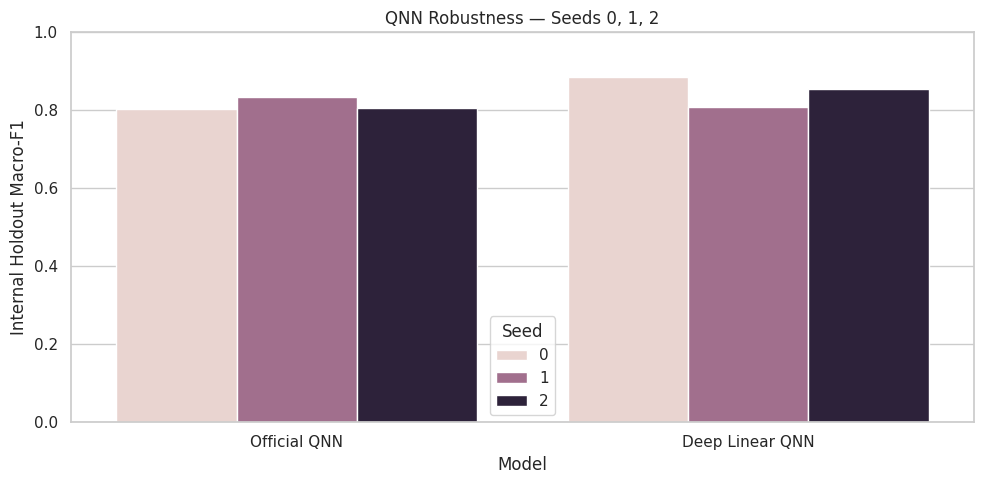

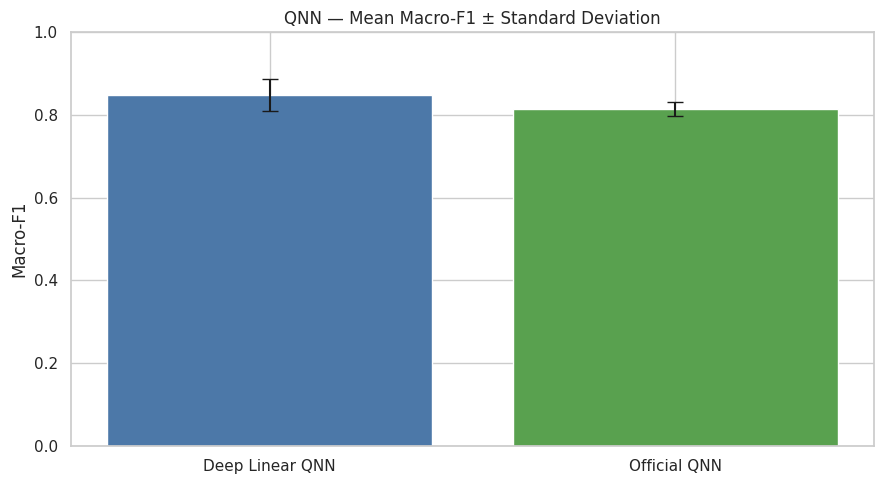


BEST MODEL:
Model                 Deep Linear QNN
Mean_F1                      0.848519
Std_F1                       0.038825
Mean_Accuracy                0.854281
Mean_Training_Time         165.229994


In [48]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, accuracy_score

from challenge.data import load_data
from challenge.models import QuantumClassifier

# Reuse RotationQNN from section 8.8
assert "RotationQNN" in globals(), (
    "Run the RotationQNN class definition from section 8.8 first."
)

# 1. Dataset
tables, _, manifest, _ = load_data()

X = tables["train"][manifest["features"]].to_numpy()
y = tables["train"]["target"].to_numpy()

labels = ["alfalfa", "maize", "wheat"]

# Same internal holdout as previous experiments
X_tr, X_hold, y_tr, y_hold = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

prep = make_pipeline(
    StandardScaler(),
    PCA(n_components=4, svd_solver="full"),
    StandardScaler()
)

X_tr = prep.fit_transform(X_tr)
X_hold = prep.transform(X_hold)

# 2. Models
model_configs = {
    "Official QNN": lambda: QuantumClassifier(
        labels=labels,
        encoding="ry",
        max_evals=100
    ),
    "Deep Linear QNN": lambda: RotationQNN(
        gates=("ry", "ry", "ry")
    )
}

results = []

# 3. Multi-seed experiments
for seed in [0, 1, 2]:

    for model_name, build_model in model_configs.items():

        print(f"Training {model_name} | Seed {seed}")

        model = build_model()

        start = time.perf_counter()
        model.fit(X_tr, y_tr, seed=seed)
        train_time = time.perf_counter() - start

        pred = model.predict(X_hold)

        results.append({
            "Model": model_name,
            "Seed": seed,
            "Macro-F1": f1_score(
                y_hold, pred, average="macro"
            ),
            "Accuracy": accuracy_score(y_hold, pred),
            "Training Time (s)": train_time
        })

        # Save after each successful run
        pd.DataFrame(results).to_csv(
            "/kaggle/working/qnn_multiseed_results.csv",
            index=False
        )

# 4. Detailed results
results_df = pd.DataFrame(results)
display(results_df.round(4))

# 5. Summary
summary = results_df.groupby("Model").agg(
    Mean_F1=("Macro-F1", "mean"),
    Std_F1=("Macro-F1", "std"),
    Mean_Accuracy=("Accuracy", "mean"),
    Mean_Training_Time=("Training Time (s)", "mean")
).reset_index()

display(summary.round(4))

# 6. Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Macro-F1",
    hue="Seed",
    errorbar=None
)

plt.ylim(0, 1)
plt.title("QNN Robustness — Seeds 0, 1, 2")
plt.ylabel("Internal Holdout Macro-F1")
plt.tight_layout()
plt.show()

# Mean performance with standard deviation
plt.figure(figsize=(9, 5))

plt.bar(
    summary["Model"],
    summary["Mean_F1"],
    yerr=summary["Std_F1"],
    capsize=6,
    color=["#4C78A8", "#59A14F"]
)

plt.ylim(0, 1)
plt.title("QNN — Mean Macro-F1 ± Standard Deviation")
plt.ylabel("Macro-F1")
plt.tight_layout()
plt.show()

print("\nBEST MODEL:")
print(
    summary.loc[
        summary["Mean_F1"].idxmax()
    ].to_string()
)



### Multi-Seed Robustness — Results

- **Best mean performance:** Deep Linear QNN.
- **Mean Macro-F1:** 0.8485.
- **Standard deviation:** 0.0388.
- **Mean accuracy:** 85.43%.
- **Mean training time:** 165.23 seconds.
- Deep Linear outperformed the official QNN on average.
- However, performance varies across seeds, indicating sensitivity to initialization.

**Conclusion:** Deep Linear is a promising improvement, but greater robustness is required before final model selection.



## 8.10 QNN Optimization — Parameter Initialization

Compare three initialization strategies for the Deep Linear QNN: wide random, medium random, and small random angles.

Keep the same 4-qubit architecture, 100 COBYLA evaluations, seed 0, and internal holdout.

**Goal:** Improve Macro-F1 and training stability by finding a better initialization strategy.



Training: Wide [-pi, pi] (Baseline)

Training: Medium [-0.5, 0.5]

Training: Small [-0.1, 0.1]


,Initialization,Macro-F1,Accuracy,Final Loss,Training Time (s)
0,"Wide [-pi, pi] (Baseline)",0.8845,0.8798,0.6292,165.9844
1,"Medium [-0.5, 0.5]",0.8333,0.8415,0.7710,172.3852
2,"Small [-0.1, 0.1]",0.8054,0.8142,0.8281,177.6102


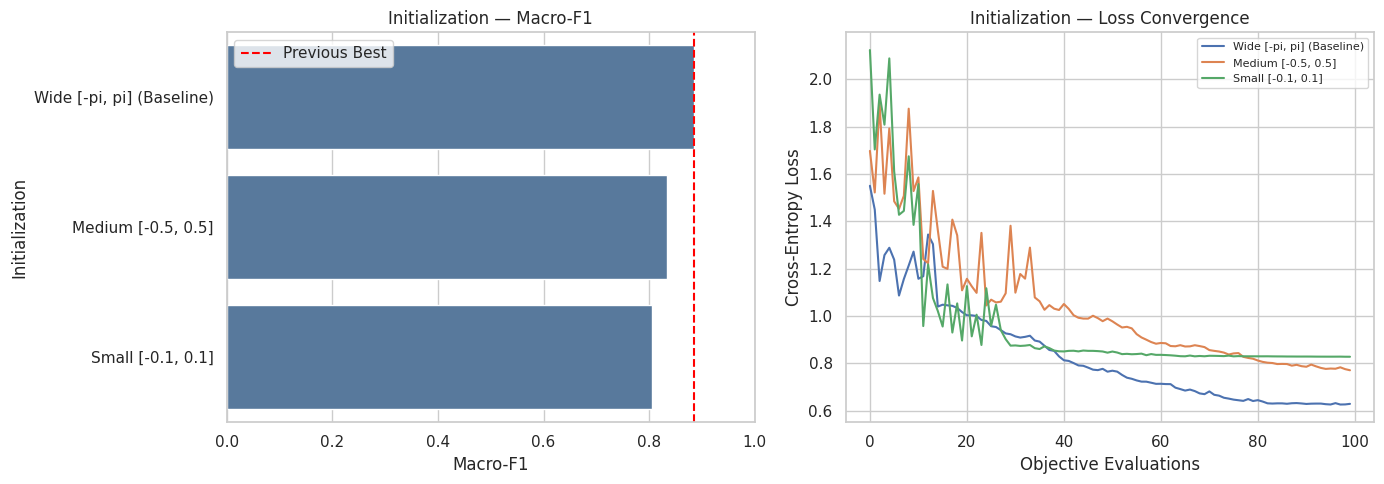


BEST INITIALIZATION:
Initialization       Wide [-pi, pi] (Baseline)
Macro-F1                              0.884486
Accuracy                              0.879781
Final Loss                            0.629158
Training Time (s)                   165.984365


In [49]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, accuracy_score

from qiskit_machine_learning.algorithms import NeuralNetworkClassifier
from qiskit_machine_learning.optimizers import COBYLA

from challenge.data import load_data
from challenge.models import angles

# Reuse our verified Deep Linear architecture
assert "RotationQNN" in globals()

tables, _, manifest, _ = load_data()

X = tables["train"][manifest["features"]].to_numpy()
y = tables["train"]["target"].to_numpy()

X_tr, X_hold, y_tr, y_hold = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

prep = make_pipeline(
    StandardScaler(),
    PCA(n_components=4, svd_solver="full"),
    StandardScaler()
)

X_tr = prep.fit_transform(X_tr)
X_hold = prep.transform(X_hold)

labels = ["alfalfa", "maize", "wheat"]

# Initialization strategies
initializations = {
    "Wide [-pi, pi] (Baseline)": np.pi,
    "Medium [-0.5, 0.5]": 0.5,
    "Small [-0.1, 0.1]": 0.1
}

results = []
histories = {}

for name, scale in initializations.items():

    print(f"\nTraining: {name}")

    model = RotationQNN(gates=("ry", "ry", "ry"))

    rng = np.random.default_rng(0)
    initial_point = rng.uniform(
        -scale, scale, len(model.weights)
    )

    history = []

    def callback(weights, loss):
        history.append(float(loss))

    model.model = NeuralNetworkClassifier(
        neural_network=model.qnn,
        one_hot=True,
        loss="cross_entropy",
        optimizer=COBYLA(maxiter=100),
        initial_point=initial_point,
        callback=callback
    )

    y_encoded = np.array([
        labels.index(v) for v in y_tr
    ])

    y_onehot = np.eye(3)[y_encoded]

    start = time.perf_counter()

    model.model.fit(
        angles(X_tr),
        y_onehot
    )

    training_time = time.perf_counter() - start

    pred = model.predict(X_hold)

    results.append({
        "Initialization": name,
        "Macro-F1": f1_score(
            y_hold, pred, average="macro"
        ),
        "Accuracy": accuracy_score(y_hold, pred),
        "Final Loss": history[-1],
        "Training Time (s)": training_time
    })

    histories[name] = history

# Results
init_results = pd.DataFrame(results).sort_values(
    "Macro-F1", ascending=False
)

display(init_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=init_results,
    x="Macro-F1",
    y="Initialization",
    color="#4C78A8",
    ax=axes[0]
)

axes[0].axvline(
    0.8845,
    color="red",
    linestyle="--",
    label="Previous Best"
)

axes[0].set_xlim(0, 1)
axes[0].legend()
axes[0].set_title("Initialization — Macro-F1")

for name, history in histories.items():
    axes[1].plot(history, label=name)

axes[1].set_title("Initialization — Loss Convergence")
axes[1].set_xlabel("Objective Evaluations")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Save results
init_results.to_csv(
    "/kaggle/working/qnn_initialization_results.csv",
    index=False
)

print("\nBEST INITIALIZATION:")
print(init_results.iloc[0].to_string())



### QNN Parameter Initialization — Results

- **Wide [-π, π]:** Best Macro-F1 = 0.8845.
- **Medium [-0.5, 0.5]:** Macro-F1 ≈ 0.83.
- **Small [-0.1, 0.1]:** Macro-F1 ≈ 0.80.
- **Best Final Loss:** 0.6292 with Wide initialization.
- **Training Time:** 165.98 seconds.

**Conclusion:**
- Wide initialization achieves the best performance.
- Smaller initialization ranges did not improve the QNN.
- Initialization strongly influences model convergence.
- **Selected configuration: Deep Linear + RY rotations + Wide initialization.**



## 8.11 Official Validation — QNN vs Deep Linear QNN

Compare the official QNN and our optimized Deep Linear QNN using the complete training dataset (914 samples) and official validation set (150 samples).

Evaluate both models with seeds 0, 1, and 2, measuring Macro-F1, accuracy, stability, and execution time.

**Goal:** Verify whether Deep Linear consistently outperforms the official quantum baseline of 0.8557 Macro-F1.



Training Official QNN | Seed 0

Training Deep Linear QNN | Seed 0

Training Official QNN | Seed 1

Training Deep Linear QNN | Seed 1

Training Official QNN | Seed 2

Training Deep Linear QNN | Seed 2


,Model,Seed,Macro-F1,Accuracy,Training Time (s),Inference Time (s)
0,Official QNN,0,0.8473,0.8467,182.5163,0.3015
1,Deep Linear QNN,0,0.8788,0.8800,207.9727,0.3433
2,Official QNN,1,0.8586,0.8600,181.8510,0.2998
3,Deep Linear QNN,1,0.7920,0.7933,205.8031,0.3367
4,Official QNN,2,0.8612,0.8600,179.9871,0.2960
5,Deep Linear QNN,2,0.8113,0.8133,205.8236,0.3392


,Model,Mean_F1,Std_F1,Mean_Accuracy,Mean_Training_Time
0,Deep Linear QNN,0.8274,0.0455,0.8289,206.5331
1,Official QNN,0.8557,0.0074,0.8556,181.4515


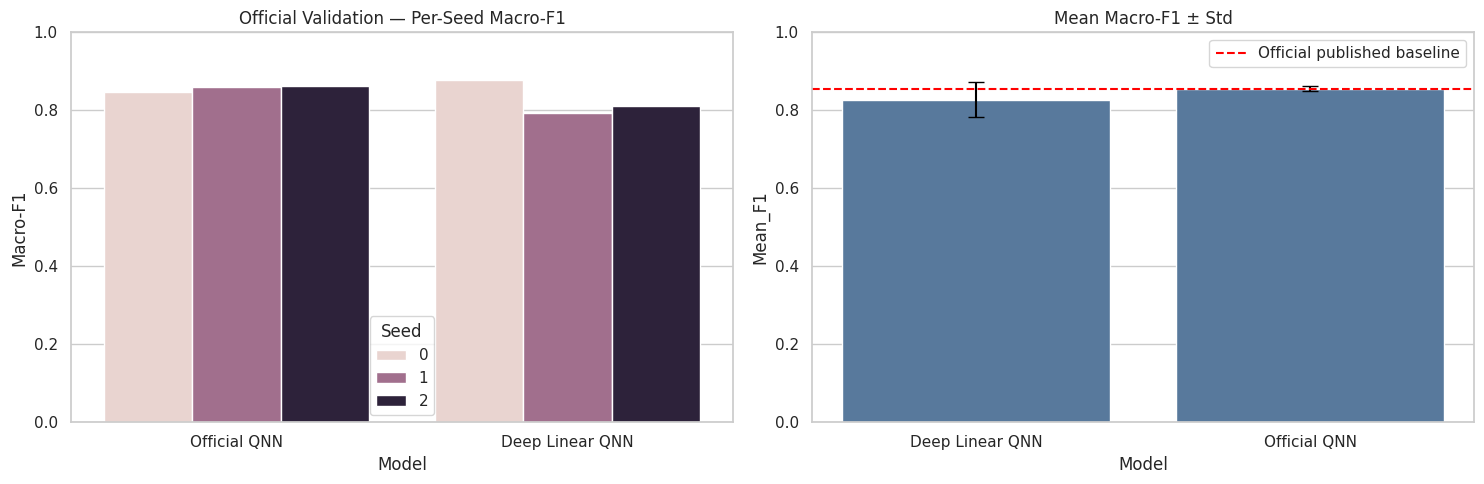


BEST MODEL:
Model                 Official QNN
Mean_F1                   0.855694
Std_F1                    0.007382
Mean_Accuracy             0.855556
Mean_Training_Time      181.451466


In [50]:

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, accuracy_score

from challenge.data import load_data
from challenge.models import QuantumClassifier

# Reuse the custom architecture from section 8.8
assert "RotationQNN" in globals(), (
    "Run the RotationQNN class definition first."
)

# =====================================================
# 1. OFFICIAL DATASET
# =====================================================

tables, _, manifest, _ = load_data()

features_q = manifest["features"]
labels = ["alfalfa", "maize", "wheat"]

X_train_raw = tables["train"][features_q].to_numpy()
X_val_raw = tables["validation"][features_q].to_numpy()

y_train = tables["train"]["target"].to_numpy()
y_val = tables["validation"]["target"].to_numpy()

# Preprocessing fitted ONLY on training data
prep = make_pipeline(
    StandardScaler(),
    PCA(n_components=4, svd_solver="full"),
    StandardScaler()
)

X_train_q = prep.fit_transform(X_train_raw)
X_val_q = prep.transform(X_val_raw)

# =====================================================
# 2. MODEL CONFIGURATIONS
# =====================================================

models = {
    "Official QNN": lambda: QuantumClassifier(
        labels=labels,
        encoding="ry",
        max_evals=100
    ),
    "Deep Linear QNN": lambda: RotationQNN(
        gates=("ry", "ry", "ry")
    )
}

# =====================================================
# 3. TRAINING — SEEDS 0, 1, 2
# =====================================================

results = []
output_path = Path(
    "/kaggle/working/qnn_official_validation_comparison.csv"
)

for seed in [0, 1, 2]:

    for model_name, build_model in models.items():

        print(f"\nTraining {model_name} | Seed {seed}")

        model = build_model()

        start = time.perf_counter()
        model.fit(X_train_q, y_train, seed=seed)
        training_time = time.perf_counter() - start

        start = time.perf_counter()
        pred = model.predict(X_val_q)
        inference_time = time.perf_counter() - start

        results.append({
            "Model": model_name,
            "Seed": seed,
            "Macro-F1": f1_score(
                y_val, pred, average="macro"
            ),
            "Accuracy": accuracy_score(y_val, pred),
            "Training Time (s)": training_time,
            "Inference Time (s)": inference_time
        })

        # Save each completed experiment
        pd.DataFrame(results).to_csv(
            output_path, index=False
        )

# =====================================================
# 4. RESULTS SUMMARY
# =====================================================

results_df = pd.DataFrame(results)

summary = results_df.groupby("Model").agg(
    Mean_F1=("Macro-F1", "mean"),
    Std_F1=("Macro-F1", "std"),
    Mean_Accuracy=("Accuracy", "mean"),
    Mean_Training_Time=("Training Time (s)", "mean")
).reset_index()

display(results_df.round(4))
display(summary.round(4))

# =====================================================
# 5. VISUALIZATIONS
# =====================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Macro-F1",
    hue="Seed",
    errorbar=None,
    ax=axes[0]
)

axes[0].set_ylim(0, 1)
axes[0].set_title("Official Validation — Per-Seed Macro-F1")

sns.barplot(
    data=summary,
    x="Model",
    y="Mean_F1",
    color="#4C78A8",
    ax=axes[1]
)

axes[1].errorbar(
    x=np.arange(len(summary)),
    y=summary["Mean_F1"],
    yerr=summary["Std_F1"],
    fmt="none",
    ecolor="black",
    capsize=6
)

axes[1].axhline(
    0.8557,
    color="red",
    linestyle="--",
    label="Official published baseline"
)

axes[1].set_ylim(0, 1)
axes[1].set_title("Mean Macro-F1 ± Std")
axes[1].legend()

plt.tight_layout()
plt.show()

summary.to_csv(
    "/kaggle/working/qnn_official_validation_summary.csv",
    index=False
)

print("\nBEST MODEL:")
print(
    summary.loc[
        summary["Mean_F1"].idxmax()
    ].to_string()
)



### Official Validation — QNN Comparison

- **Official QNN:** Mean Macro-F1 = 0.8557.
- **Deep Linear QNN:** Mean Macro-F1 = 0.8274.
- **Performance difference:** −2.83 percentage points.
- **Stability:** Official QNN is more stable across seeds.
- **Training time:** Deep Linear is approximately 25 seconds slower.

**Conclusion:**
- Deep Linear improved internal holdout performance but did not generalize better to official validation.
- Increasing circuit depth did not produce a reliable improvement.
- The official QNN remains our strongest quantum baseline.



## 8.12 Final Test — Official QNN vs Deep Linear QNN

Generate predictions for the 221 unlabeled test samples using both quantum architectures.

Compare prediction distributions and agreement between models without using test labels or modifying the selected configurations.


Training Official QNN...
Training Deep Linear QNN...

Prediction agreement: 77.83%
Test samples: 221


,Official QNN,Deep Linear QNN,Agreement
0,maize,maize,True
1,maize,maize,True
2,wheat,wheat,True
3,maize,maize,True
4,maize,maize,True
5,maize,maize,True
6,maize,alfalfa,False
7,maize,maize,True
8,alfalfa,maize,False
9,maize,maize,True


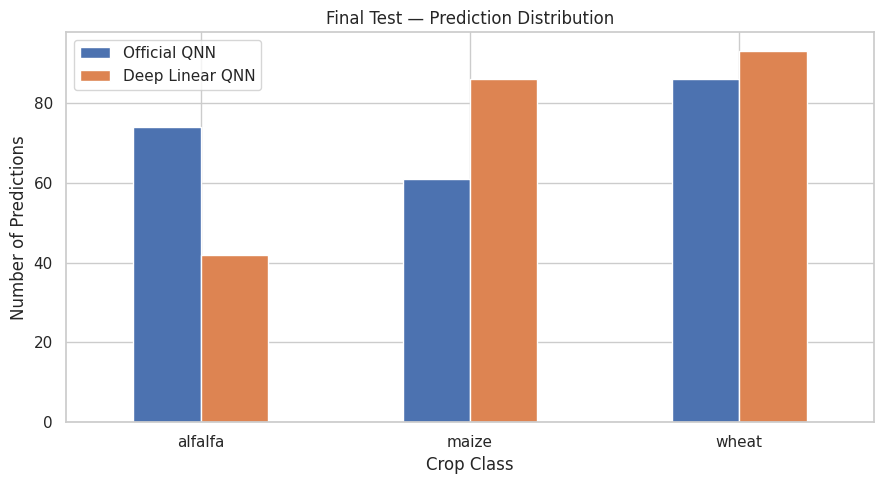


Test predictions saved successfully.


In [51]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from challenge.data import load_data
from challenge.models import QuantumClassifier

assert "RotationQNN" in globals(), (
    "Run the RotationQNN class definition first."
)

# 1. Load datasets
tables, _, manifest, _ = load_data()

feature_names = manifest["features"]
labels = ["alfalfa", "maize", "wheat"]

X_train_raw = tables["train"][feature_names].to_numpy()
X_test_raw = tables["test"][feature_names].to_numpy()
y_train = tables["train"]["target"].to_numpy()

# 2. Preprocessing — training data only
prep = make_pipeline(
    StandardScaler(),
    PCA(n_components=4, svd_solver="full"),
    StandardScaler()
)

X_train_q = prep.fit_transform(X_train_raw)
X_test_q = prep.transform(X_test_raw)

# 3. Models
models = {
    "Official QNN": QuantumClassifier(
        labels=labels, encoding="ry", max_evals=100
    ),
    "Deep Linear QNN": RotationQNN(
        gates=("ry", "ry", "ry")
    )
}

predictions_test = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_q, y_train, seed=0)
    predictions_test[name] = model.predict(X_test_q)

# 4. Compare predictions
comparison = pd.DataFrame({
    "Official QNN": predictions_test["Official QNN"],
    "Deep Linear QNN": predictions_test["Deep Linear QNN"]
})

comparison["Agreement"] = (
    comparison["Official QNN"]
    == comparison["Deep Linear QNN"]
)

agreement = comparison["Agreement"].mean()

print(f"\nPrediction agreement: {agreement:.2%}")
print("Test samples:", len(comparison))

display(comparison.head(10))

# 5. Prediction distributions
distribution = pd.DataFrame({
    name: pd.Series(pred).value_counts()
    for name, pred in predictions_test.items()
}).fillna(0).astype(int)

distribution = distribution.reindex(labels, fill_value=0)

distribution.plot(kind="bar", figsize=(9, 5))
plt.title("Final Test — Prediction Distribution")
plt.xlabel("Crop Class")
plt.ylabel("Number of Predictions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 6. Save predictions
output = Path("/kaggle/working")

comparison.to_csv(
    output / "qnn_test_comparison.csv",
    index=False
)

for name, pred in predictions_test.items():
    filename = name.lower().replace(" ", "_")
    pd.DataFrame({"prediction": pred}).to_csv(
        output / f"{filename}_test_predictions.csv",
        index=False
    )

print("\nTest predictions saved successfully.")



### Final Test — QNN Prediction Distribution

- **Official QNN:** Predicts approximately 74 Alfalfa, 61 Maize, and 86 Wheat samples.
- **Deep Linear QNN:** Predicts approximately 42 Alfalfa, 86 Maize, and 93 Wheat samples.
- Deep Linear predicts significantly fewer Alfalfa and more Maize samples.
- Both models predict Wheat most frequently.
- The two architectures produce different class distributions.

**Conclusion:**
- The models behave differently on the 221 unlabeled test samples.
- True test labels are unavailable, so prediction accuracy and Macro-F1 cannot be calculated.
- Official QNN remains the preferred quantum baseline based on official validation performance.
